In [52]:
# Load standard libraries
import os
import json
import sys
import pandas as pd
import requests
from dotenv import load_dotenv
import time

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from matplotlib.dates import MonthLocator, AutoDateLocator, ConciseDateFormatter, MO
from matplotlib.ticker import FuncFormatter, PercentFormatter, StrMethodFormatter

import datetime

from IPython.display import HTML

# Load env variables
load_dotenv("API_KEYS.env")
blockworks_api_key = os.getenv("BLOCKWORKS_API_KEY")
coingecko_api_key = os.getenv("COINGECKO_API_KEY")
dune_api_key = os.getenv("DUNE_API_KEY")
messari_api_key = os.getenv("MESSARI_API_KEY")
fred_api_key = os.getenv("FRED_API_KEY")

# Import data processing functions
sys.path.append('src')
from data import data_processing
from data import metadao
from data import hyperliquid

# Import visualization functions
sys.path.append('src')
from visualization import visualization

# Import utils functions
sys.path.append('utils')
import helper_functions
today = datetime.datetime.today()
date = helper_functions.format_date_with_suffix(today)

# Define outputs filepath
plots_filepath = 'outputs/plots'
if not os.path.exists(plots_filepath):
        os.makedirs(plots_filepath)
tables_filepath = 'outputs/tables'
if not os.path.exists(tables_filepath):
        os.makedirs(tables_filepath)

In [53]:
# Clear all existing outputs, you will be prompted for yes/no
directory_path = 'outputs/'
helper_functions.delete_directories(directory_path)


Found 93 files to delete


{'total_found': 93, 'deleted': 93, 'errors': []}

In [54]:
# FINANCIAL METRICS

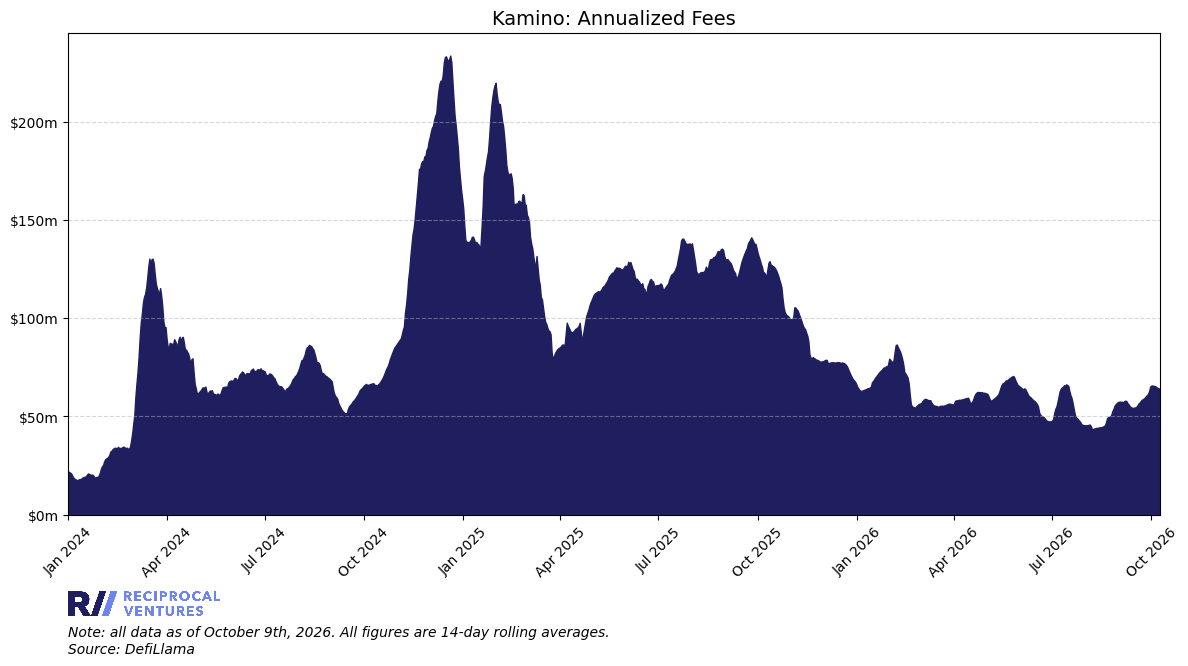

           date      fees      fees-14d
1088 2026-10-05  60219890  6.527037e+07
1089 2026-10-06  59787730  6.475645e+07
1090 2026-10-07  56993655  6.448314e+07
1091 2026-10-08  58810625  6.427011e+07
1092 2026-10-09  56622815  6.378312e+07


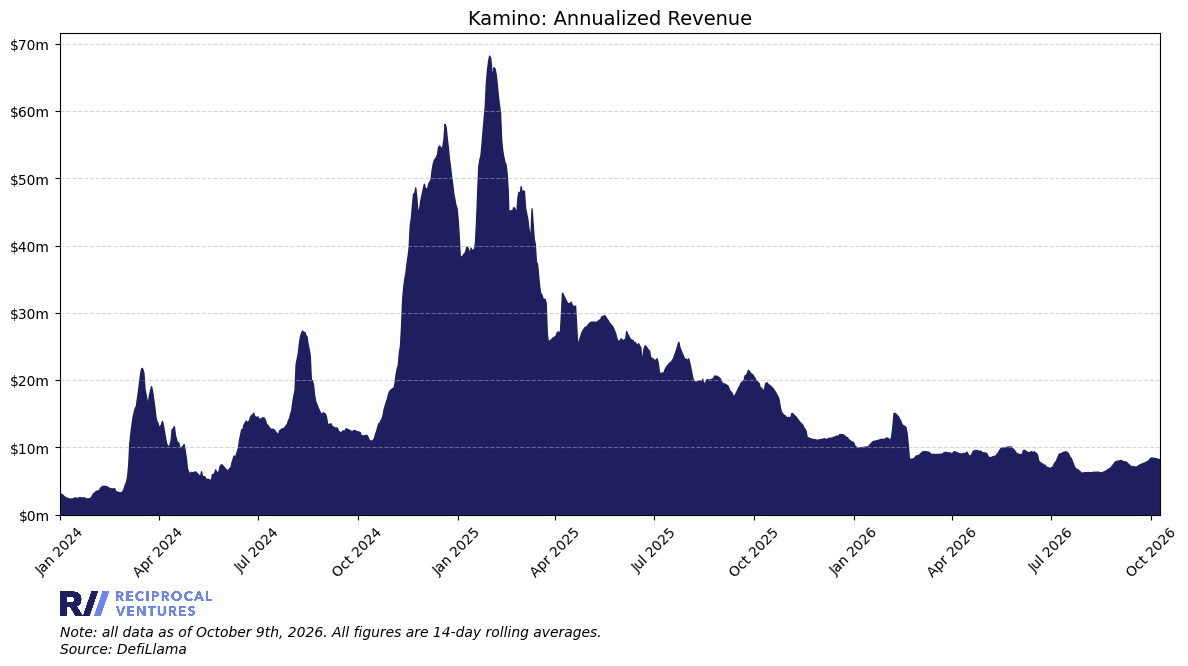

           date  revenue   revenue-14d
1088 2026-10-05  8095700  8.400788e+06
1089 2026-10-06  7764645  8.340380e+06
1090 2026-10-07  7408770  8.297988e+06
1091 2026-10-08  7656605  8.273742e+06
1092 2026-10-09  7400375  8.225510e+06


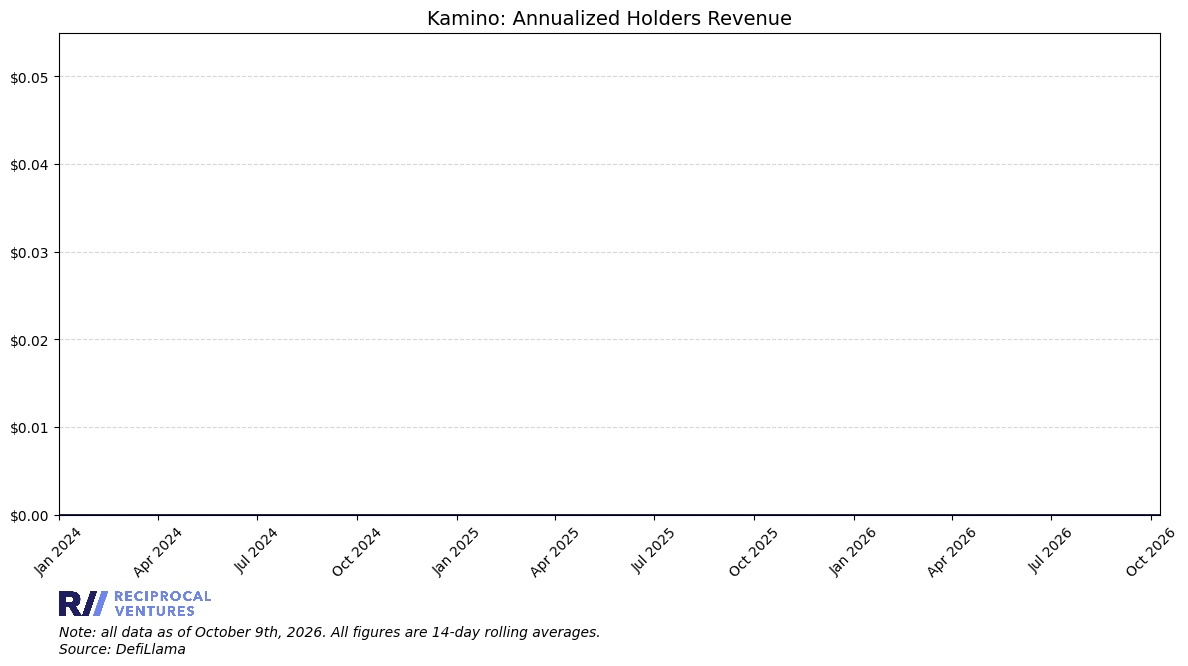

           date  holders-revenue  holders-revenue-14d
1055 2026-10-05                0                  0.0
1056 2026-10-06                0                  0.0
1057 2026-10-07                0                  0.0
1058 2026-10-08                0                  0.0
1059 2026-10-09                0                  0.0
did not annualize TVL


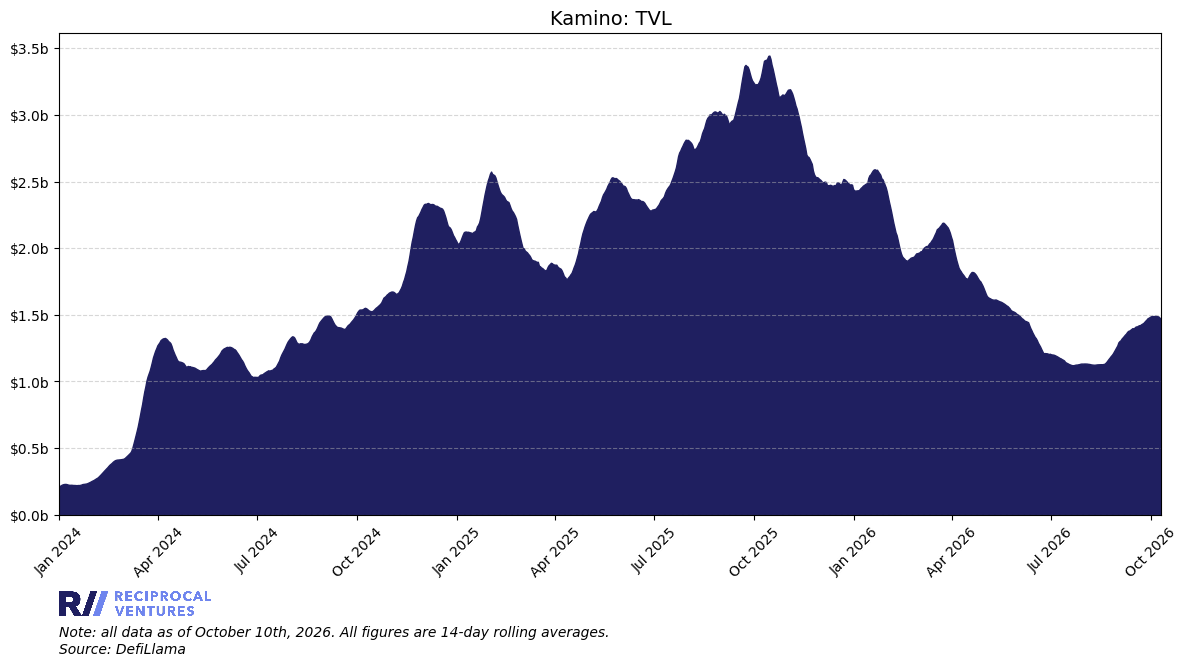

                    date         tvl       tvl-14d
1493 2026-10-07 00:00:00  1474494711  1.489351e+09
1494 2026-10-08 00:00:00  1437480907  1.486060e+09
1495 2026-10-09 00:00:00  1383546432  1.477494e+09
1496 2026-10-10 00:00:00  1396781001  1.466702e+09
1497 2026-10-10 13:01:59  1399428824  1.456474e+09
Skipping Holders Revenue for kamino: all values are zero
Skipping Earnings for kamino: equals revenue (no incentives tracked)


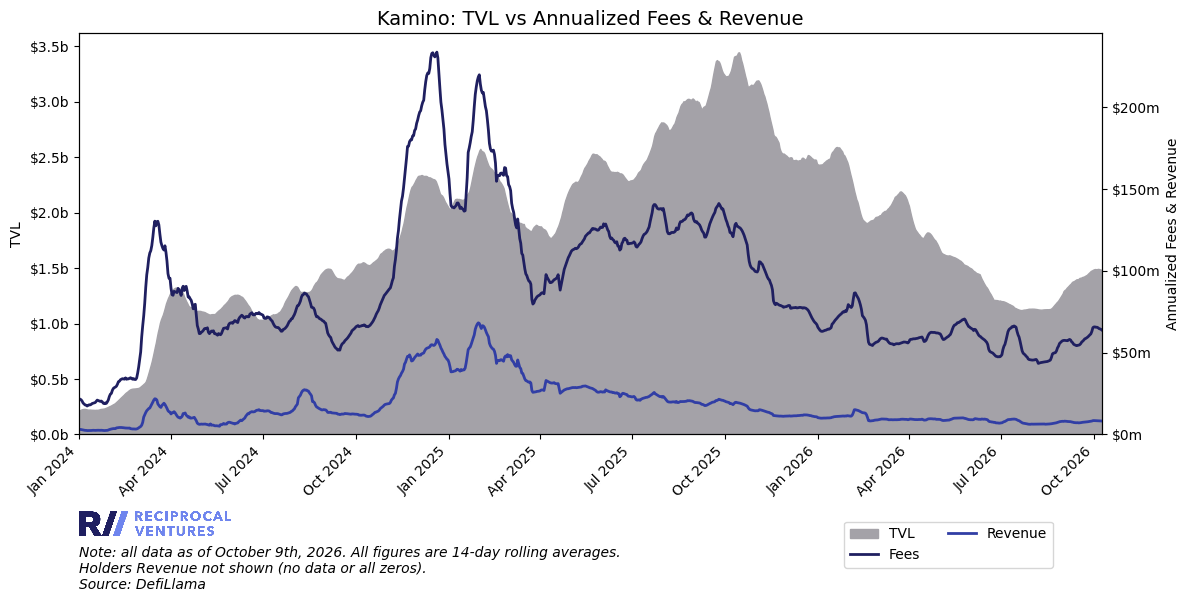

           date      fees-14d   revenue-14d  holders-revenue-14d  \
1088 2026-10-05  6.527037e+07  8.400788e+06                  0.0   
1089 2026-10-06  6.475645e+07  8.340380e+06                  0.0   
1090 2026-10-07  6.448314e+07  8.297988e+06                  0.0   
1091 2026-10-08  6.427011e+07  8.273742e+06                  0.0   
1092 2026-10-09  6.378312e+07  8.225510e+06                  0.0   

      earnings-14d       tvl-14d  
1088  8.400788e+06  1.492970e+09  
1089  8.340380e+06  1.491577e+09  
1090  8.297988e+06  1.489351e+09  
1091  8.273742e+06  1.486060e+09  
1092  8.225510e+06  1.477494e+09  


In [55]:
metrics = ['dailyFees','dailyRevenue', 'dailyHoldersRevenue', 'tvl'] # 'dailyFees' or 'dailyRevenue' or 'dailyHoldersRevenue' or 'tvl' or 'mcap' or 'fdv'
assets = {'kamino': 'Kamino'}
start_date = '2024-01-01'
trailing_window = 14
annualize = True
index_from_first_date = False
combined_metrics = False

visualization.single_asset_daily_metric(metrics, assets, start_date, trailing_window, plots_filepath, date, annualize, index_from_first_date, combined_metrics)

combined_metrics = True
visualization.single_asset_daily_metric(metrics, assets, start_date, trailing_window, plots_filepath, date, annualize, index_from_first_date, combined_metrics)

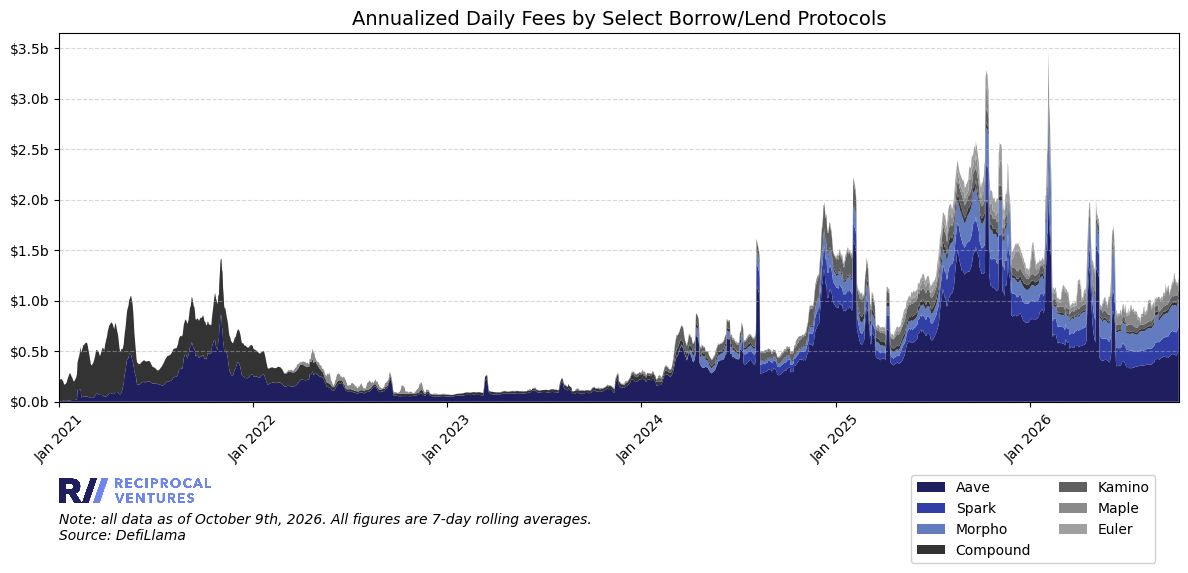

           date          Aave        Morpho         Maple        Kamino  \
2103 2026-10-05  4.587538e+08  2.593672e+08  1.121392e+08  6.835897e+07   
2104 2026-10-06  4.737157e+08  2.535375e+08  1.031749e+08  6.569197e+07   
2105 2026-10-07  4.833022e+08  2.608131e+08  7.763644e+07  6.155902e+07   
2106 2026-10-08  4.986602e+08  2.785151e+08  7.926267e+07  6.102790e+07   
2107 2026-10-09  4.977477e+08  2.823208e+08  9.853274e+07  6.006404e+07   

             Euler      Compound         Spark  
2103  2.131157e+07  3.109180e+07  2.293643e+08  
2104  2.135719e+07  3.001432e+07  2.297123e+08  
2105  2.135151e+07  2.910969e+07  2.308935e+08  
2106  2.122584e+07  2.813003e+07  2.341306e+08  
2107  2.104819e+07  2.834298e+07  2.343278e+08  


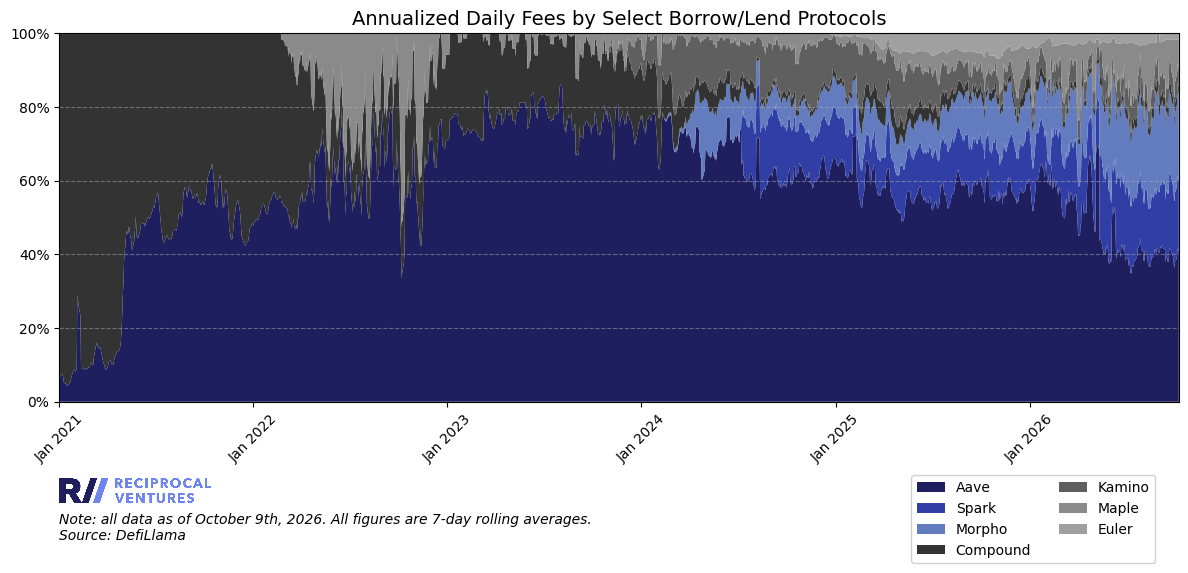

           date          Aave        Morpho         Maple        Kamino  \
2103 2026-10-05  4.587538e+08  2.593672e+08  1.121392e+08  6.835897e+07   
2104 2026-10-06  4.737157e+08  2.535375e+08  1.031749e+08  6.569197e+07   
2105 2026-10-07  4.833022e+08  2.608131e+08  7.763644e+07  6.155902e+07   
2106 2026-10-08  4.986602e+08  2.785151e+08  7.926267e+07  6.102790e+07   
2107 2026-10-09  4.977477e+08  2.823208e+08  9.853274e+07  6.006404e+07   

             Euler      Compound         Spark  
2103  2.131157e+07  3.109180e+07  2.293643e+08  
2104  2.135719e+07  3.001432e+07  2.297123e+08  
2105  2.135151e+07  2.910969e+07  2.308935e+08  
2106  2.122584e+07  2.813003e+07  2.341306e+08  
2107  2.104819e+07  2.834298e+07  2.343278e+08  


In [56]:
# Test the function to plot multi asset daily metric
metrics = ['dailyFees'] # 'dailyFees' or 'dailyRevenue' or 'dailyHoldersRevenue' or 'tvl' or 'mcap' or 'fdv'
assets = {'aave': 'Aave',
          'morpho': 'Morpho',
          'maple-finance': 'Maple',
          'kamino': 'Kamino',
          'euler': 'Euler',
          'compound-finance': 'Compound',
          'spark': 'Spark'}
start_date = '2021-01-01'
trailing_window = 7
chart_title = 'Annualized Daily Fees by Select Borrow/Lend Protocols'
stacked_100 = False
annualize = True
index_from_first_date=False

visualization.multi_asset_daily_metric(metrics, assets, start_date, trailing_window, plots_filepath, date, chart_title, stacked_100, annualize, index_from_first_date)

stacked_100 = True
visualization.multi_asset_daily_metric(metrics, assets, start_date, trailing_window, plots_filepath, date, chart_title, stacked_100, annualize, index_from_first_date)

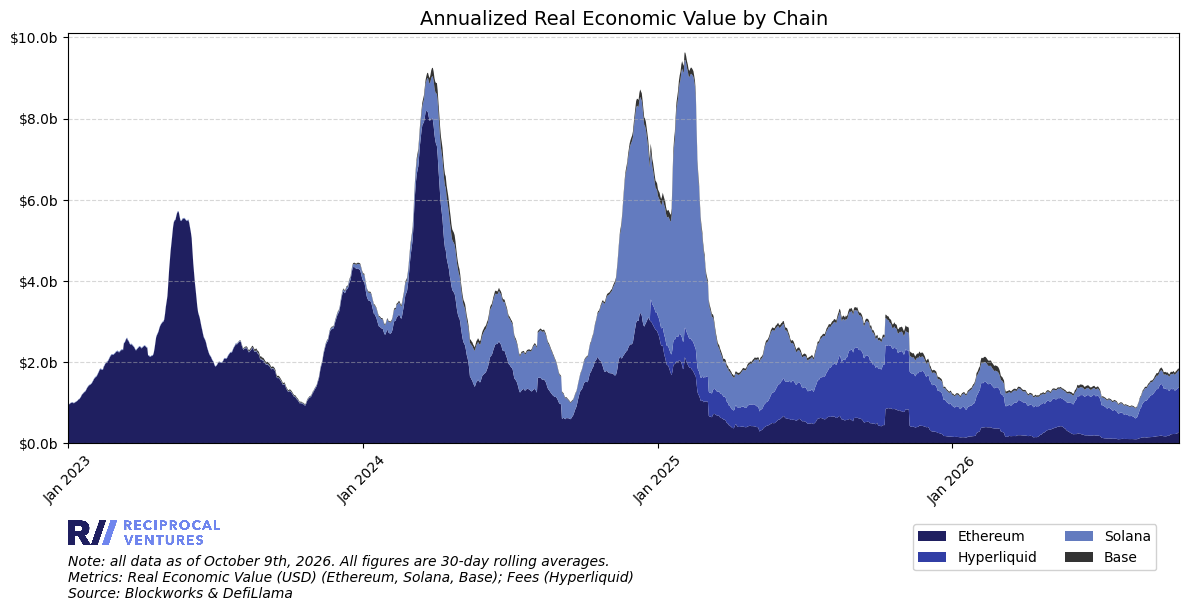

           date      Ethereum        Solana          Base   Hyperliquid
1373 2026-10-05  2.379010e+08  4.009317e+08  5.526778e+07  1.083406e+09
1374 2026-10-06  2.449190e+08  4.078818e+08  5.520917e+07  1.087527e+09
1375 2026-10-07  2.497365e+08  4.120050e+08  5.546063e+07  1.102313e+09
1376 2026-10-08  2.783560e+08  4.158106e+08  5.563879e+07  1.105847e+09
1377 2026-10-09  2.771573e+08  4.138947e+08  3.888615e+07  1.090703e+09


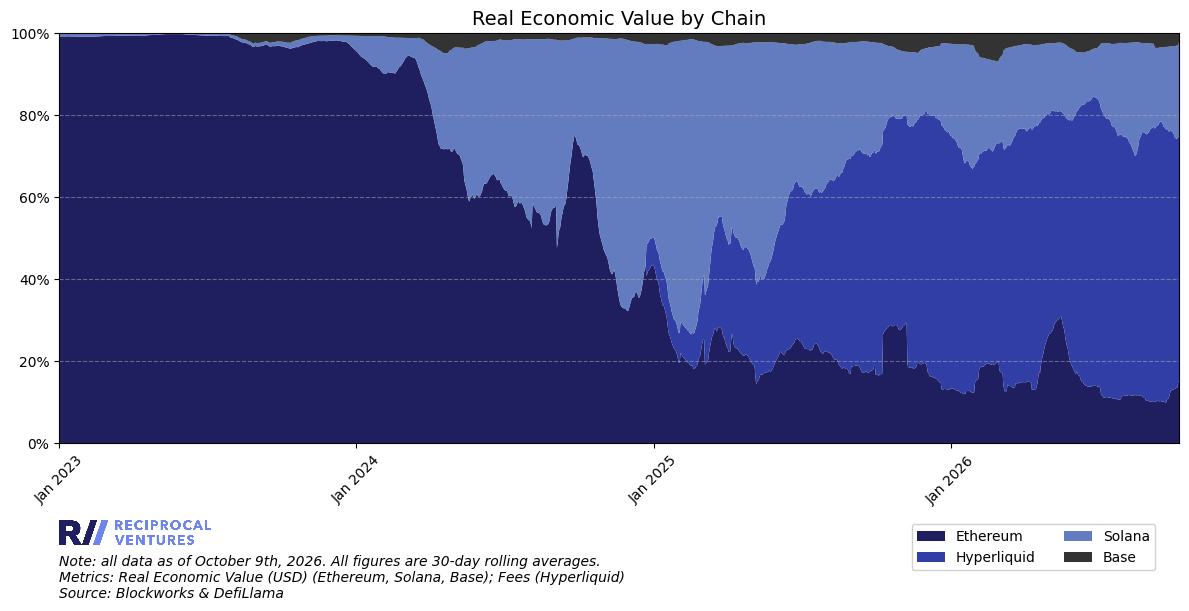

           date      Ethereum        Solana          Base   Hyperliquid
1373 2026-10-05  2.379010e+08  4.009317e+08  5.526778e+07  1.083406e+09
1374 2026-10-06  2.449190e+08  4.078818e+08  5.520917e+07  1.087527e+09
1375 2026-10-07  2.497365e+08  4.120050e+08  5.546063e+07  1.102313e+09
1376 2026-10-08  2.783560e+08  4.158106e+08  5.563879e+07  1.105847e+09
1377 2026-10-09  2.771573e+08  4.138947e+08  3.888615e+07  1.090703e+09


In [57]:
# Test the function to plot multi asset daily metric
metrics = ['rev-usd'] # 'dailyFees' or 'dailyRevenue' or 'dailyHoldersRevenue' or 'tvl' or 'mcap' or 'fdv'
assets = {'ethereum': 'Ethereum',
    'solana': 'Solana',
    'base': 'Base'
          }

additional_assets = {'hyperliquid': {'name': 'Hyperliquid', 'metric': 'dailyFees'}}
start_date = '2023-01-01'
trailing_window = 30
chart_title = 'Annualized Real Economic Value by Chain'
stacked_100 = False
annualize = True
index_from_first_date=False

visualization.multi_asset_daily_metric(metrics, assets, start_date, trailing_window, plots_filepath, date, chart_title, stacked_100, annualize, index_from_first_date, additional_assets)

chart_title = 'Real Economic Value by Chain'
stacked_100 = True
visualization.multi_asset_daily_metric(metrics, assets, start_date, trailing_window, plots_filepath, date, chart_title, stacked_100, annualize, index_from_first_date, additional_assets)

39 projects: ['aptos', 'arbitrum', 'arc', 'avalanche', 'base', 'berachain', 'bitcoin', 'bnb', 'bob', 'boba', 'cardano', 'celestia', 'ethereum', 'fogo', 'hyperevm', 'ink', 'katana', 'mantle', 'megaeth', 'monad', 'monero', 'movement', 'near', 'optimism', 'plasma', 'polygon', 'robinhood', 'shape', 'solana', 'sui', 'superseed', 'tempo', 'thorchain', 'tron', 'unichain', 'worldchain', 'xrpl', 'zcash', 'zksync']
Rolled 31 assets into 'Other': Aptos, Arc, Avalanche, Berachain, Bob, Boba, Cardano, Celestia, Fogo, Hyperevm, Ink, Katana, Mantle, Megaeth, Monad, Monero, Movement, Near, Optimism, Plasma, Polygon, Shape, Sui, Superseed, Tempo, Thorchain, Unichain, Worldchain, Xrpl, Zcash, Zksync


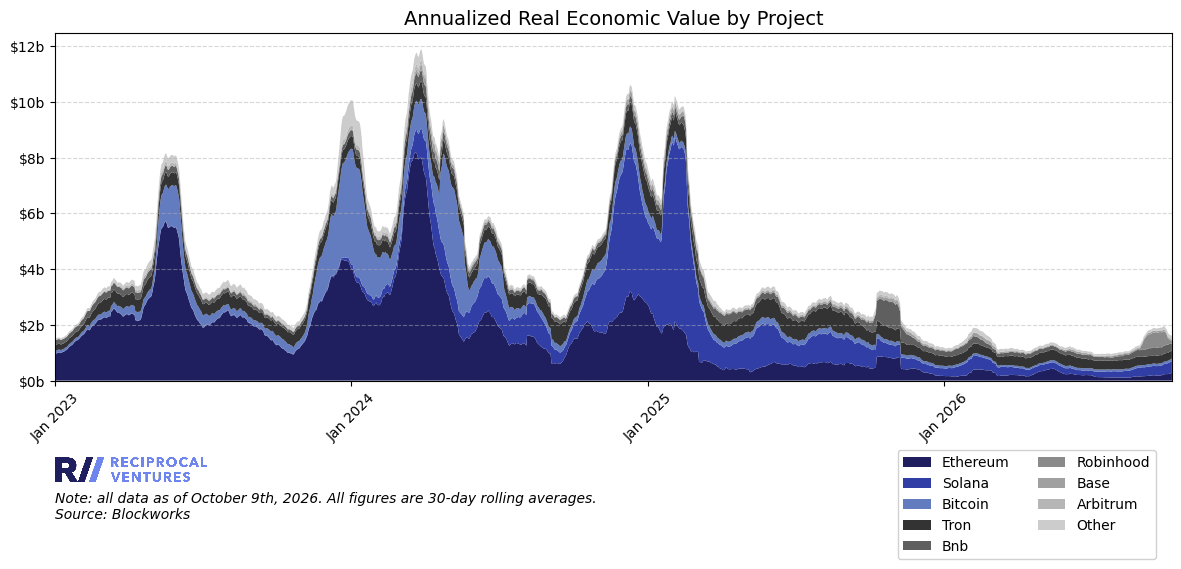

           date      Arbitrum          Base       Bitcoin           Bnb  \
1373 2026-10-05  7.982750e+06  5.526778e+07  8.813912e+07  2.887808e+08   
1374 2026-10-06  8.061088e+06  5.520917e+07  8.868257e+07  2.841949e+08   
1375 2026-10-07  8.184820e+06  5.546063e+07  8.889656e+07  2.750009e+08   
1376 2026-10-08  8.309007e+06  5.563879e+07  8.911793e+07  2.593671e+08   
1377 2026-10-09  8.354452e+06  3.888615e+07  8.904770e+07  2.488739e+08   

          Ethereum     Robinhood        Solana          Tron         Other  
1373  2.379010e+08  1.934598e+08  4.009317e+08  2.874006e+08  1.184430e+08  
1374  2.449190e+08  1.522129e+08  4.078818e+08  2.914543e+08  1.188893e+08  
1375  2.497365e+08  1.269326e+08  4.120050e+08  2.917536e+08  1.198871e+08  
1376  2.783560e+08  1.087918e+08  4.158106e+08  2.909654e+08  1.227853e+08  
1377  2.771573e+08  9.637272e+07  4.138947e+08  2.908547e+08  1.230753e+08  
Rolled 31 assets into 'Other': Aptos, Arc, Avalanche, Berachain, Bob, Boba, Cardano, Ce

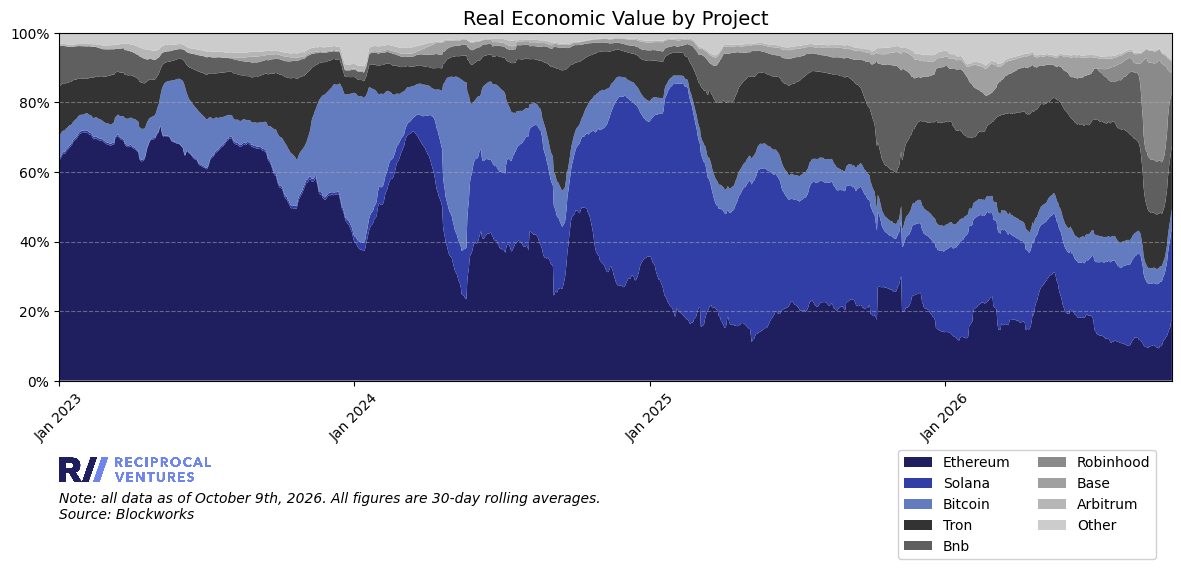

           date      Arbitrum          Base       Bitcoin           Bnb  \
1373 2026-10-05  7.982750e+06  5.526778e+07  8.813912e+07  2.887808e+08   
1374 2026-10-06  8.061088e+06  5.520917e+07  8.868257e+07  2.841949e+08   
1375 2026-10-07  8.184820e+06  5.546063e+07  8.889656e+07  2.750009e+08   
1376 2026-10-08  8.309007e+06  5.563879e+07  8.911793e+07  2.593671e+08   
1377 2026-10-09  8.354452e+06  3.888615e+07  8.904770e+07  2.488739e+08   

          Ethereum     Robinhood        Solana          Tron         Other  
1373  2.379010e+08  1.934598e+08  4.009317e+08  2.874006e+08  1.184430e+08  
1374  2.449190e+08  1.522129e+08  4.078818e+08  2.914543e+08  1.188893e+08  
1375  2.497365e+08  1.269326e+08  4.120050e+08  2.917536e+08  1.198871e+08  
1376  2.783560e+08  1.087918e+08  4.158106e+08  2.909654e+08  1.227853e+08  
1377  2.771573e+08  9.637272e+07  4.138947e+08  2.908547e+08  1.230753e+08  


In [58]:
# Plot Real Economic Value for ALL projects with pulled Blockworks data
# Charts every project with a file in data/raw/blockworks/rev-usd/ -- run the
# pull_metric_data cell in example-pull-raw-data.ipynb first to download all projects

metrics = ['rev-usd']
metric_dir = f'data/raw/blockworks/{metrics[0]}'
assets = {f[:-5]: f[:-5].replace('-', ' ').title()
          for f in sorted(os.listdir(metric_dir)) if f.endswith('.json')}
print(f'{len(assets)} projects: {list(assets)}')

start_date = '2023-01-01'
trailing_window = 30
chart_title = 'Annualized Real Economic Value by Project'
stacked_100 = False
annualize = True
index_from_first_date = False
top_n = 8  # show the top 8 projects individually, roll the rest into 'Other'

visualization.multi_asset_daily_metric(metrics, assets, start_date, trailing_window, plots_filepath, date, chart_title, stacked_100, annualize, index_from_first_date, top_n=top_n)

chart_title = 'Real Economic Value by Project'
stacked_100 = True
visualization.multi_asset_daily_metric(metrics, assets, start_date, trailing_window, plots_filepath, date, chart_title, stacked_100, annualize, index_from_first_date, top_n=top_n)

22 projects: ['arbitrum', 'avalanche', 'base', 'bnb', 'ethereum', 'fogo', 'hyperevm', 'hyperliquid', 'ink', 'katana', 'mantle', 'monad', 'movement', 'robinhood', 'solana', 'sui', 'tempo', 'thorchain', 'tron', 'unichain', 'worldchain', 'xrpl']
skipping Tron: no DEX Spot Volume (USD) data
Rolled 13 assets into 'Other': Avalanche, Fogo, Hyperevm, Ink, Katana, Mantle, Monad, Movement, Sui, Tempo, Thorchain, Worldchain, Xrpl


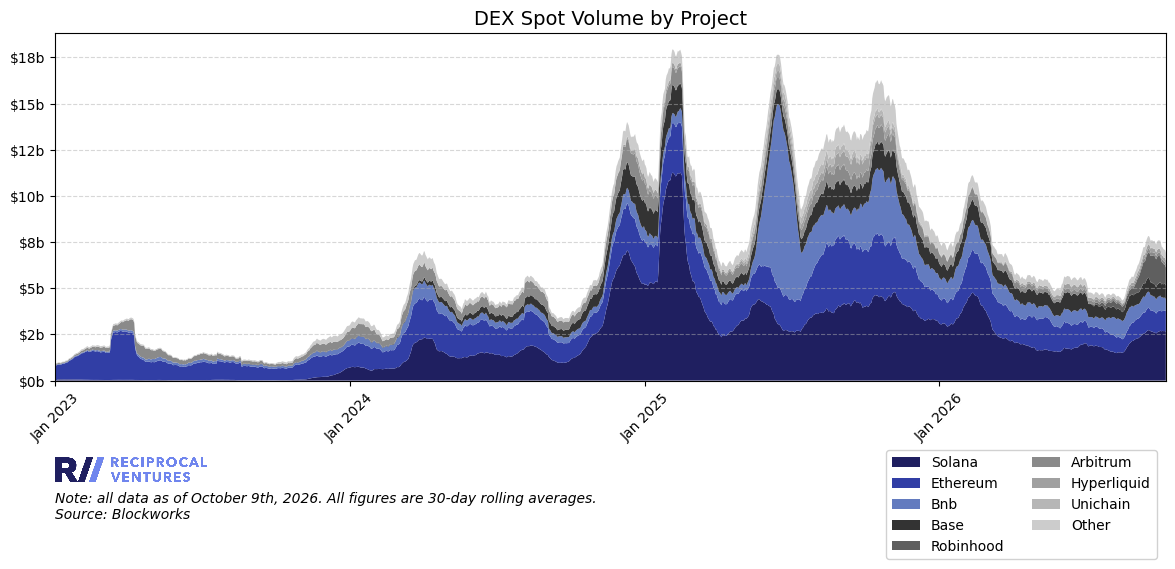

           date      Arbitrum          Base           Bnb      Ethereum  \
1373 2026-10-05  1.695635e+08  7.340946e+08  7.291837e+08  1.082993e+09   
1374 2026-10-06  1.674100e+08  7.378116e+08  7.127191e+08  1.089572e+09   
1375 2026-10-07  1.688843e+08  7.460591e+08  7.019507e+08  1.107056e+09   
1376 2026-10-08  1.712615e+08  7.601100e+08  6.835295e+08  1.122626e+09   
1377 2026-10-09  1.698890e+08  7.539388e+08  6.354656e+08  1.114447e+09   

       Hyperliquid     Robinhood        Solana      Unichain         Other  
1373  1.951391e+08  1.157682e+09  2.695068e+09  1.133558e+07  4.408361e+08  
1374  1.937704e+08  1.097181e+09  2.678430e+09  1.115039e+07  4.415950e+08  
1375  1.947261e+08  1.056585e+09  2.679415e+09  1.126552e+07  4.263887e+08  
1376  1.980182e+08  1.019717e+09  2.684613e+09  1.156621e+07  4.240534e+08  
1377  1.966646e+08  9.762491e+08  2.641557e+09  1.139050e+07  4.183772e+08  
skipping Tron: no DEX Spot Volume (USD) data
Rolled 13 assets into 'Other': Avalanche, 

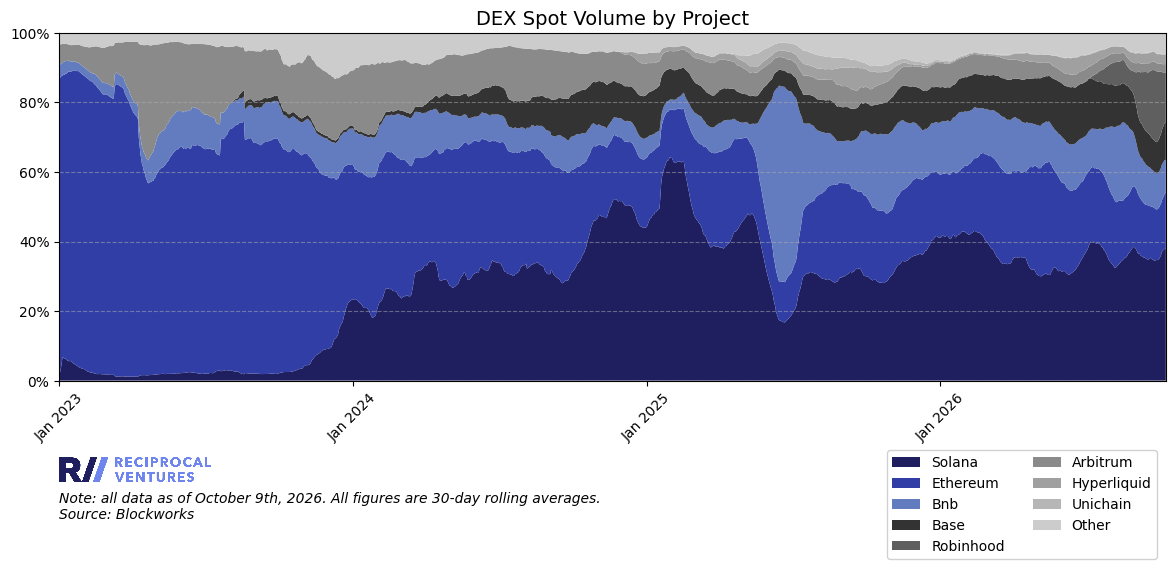

           date      Arbitrum          Base           Bnb      Ethereum  \
1373 2026-10-05  1.695635e+08  7.340946e+08  7.291837e+08  1.082993e+09   
1374 2026-10-06  1.674100e+08  7.378116e+08  7.127191e+08  1.089572e+09   
1375 2026-10-07  1.688843e+08  7.460591e+08  7.019507e+08  1.107056e+09   
1376 2026-10-08  1.712615e+08  7.601100e+08  6.835295e+08  1.122626e+09   
1377 2026-10-09  1.698890e+08  7.539388e+08  6.354656e+08  1.114447e+09   

       Hyperliquid     Robinhood        Solana      Unichain         Other  
1373  1.951391e+08  1.157682e+09  2.695068e+09  1.133558e+07  4.408361e+08  
1374  1.937704e+08  1.097181e+09  2.678430e+09  1.115039e+07  4.415950e+08  
1375  1.947261e+08  1.056585e+09  2.679415e+09  1.126552e+07  4.263887e+08  
1376  1.980182e+08  1.019717e+09  2.684613e+09  1.156621e+07  4.240534e+08  
1377  1.966646e+08  9.762491e+08  2.641557e+09  1.139050e+07  4.183772e+08  


In [59]:
# Plot DEX Spot Volume for ALL projects with pulled Blockworks data
# Charts every project with a file in data/raw/blockworks/dex-spot-volume-total-usd/ -- run the
# pull_metric_data cell in example-pull-raw-data.ipynb first to download all projects

metrics = ['dex-spot-volume-total-usd']
metric_dir = f'data/raw/blockworks/{metrics[0]}'
assets = {f[:-5]: f[:-5].replace('-', ' ').title()
          for f in sorted(os.listdir(metric_dir)) if f.endswith('.json')}
print(f'{len(assets)} projects: {list(assets)}')

start_date = '2023-01-01'
trailing_window = 30
chart_title = 'DEX Spot Volume by Project'
stacked_100 = False
annualize = False
index_from_first_date = False
top_n = 8  # show the top 8 projects individually, roll the rest into 'Other'

visualization.multi_asset_daily_metric(metrics, assets, start_date, trailing_window, plots_filepath, date, chart_title, stacked_100, annualize, index_from_first_date, top_n=top_n)

stacked_100 = True
visualization.multi_asset_daily_metric(metrics, assets, start_date, trailing_window, plots_filepath, date, chart_title, stacked_100, annualize, index_from_first_date, top_n=top_n)

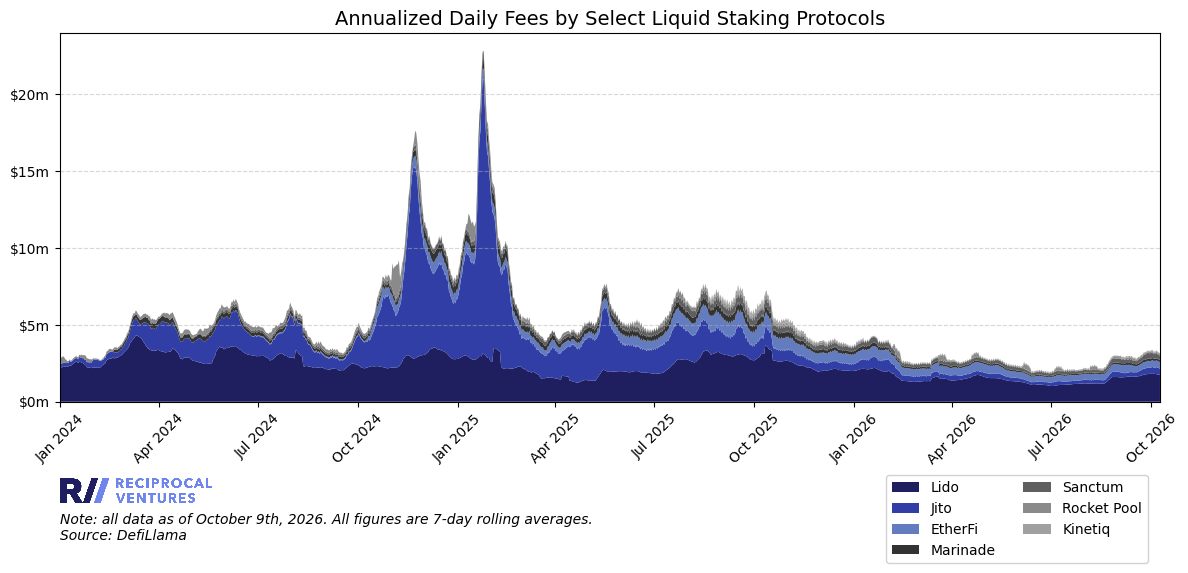

           date          Lido           Jito   Rocket Pool        Sanctum  \
1008 2026-10-05  1.802545e+06  426443.428571  92954.571429  294733.987143   
1009 2026-10-06  1.793805e+06  463779.000000  87843.000000  354027.987143   
1010 2026-10-07  1.778705e+06  431490.142857  88853.000000  296184.245714   
1011 2026-10-08  1.763894e+06  427310.857143  90735.285714  292349.674286   
1012 2026-10-09  1.736618e+06  416994.857143  93280.571429  288209.054286   

            EtherFi       Marinade       Kinetiq  
1008  429057.714286  146125.000000  74150.000000  
1009  428661.142857  145703.285714  80235.571429  
1010  434165.571429  144889.285714  70636.315714  
1011  416278.714286  142920.142857  67755.208571  
1012  412358.285714  140751.714286  67847.770000  


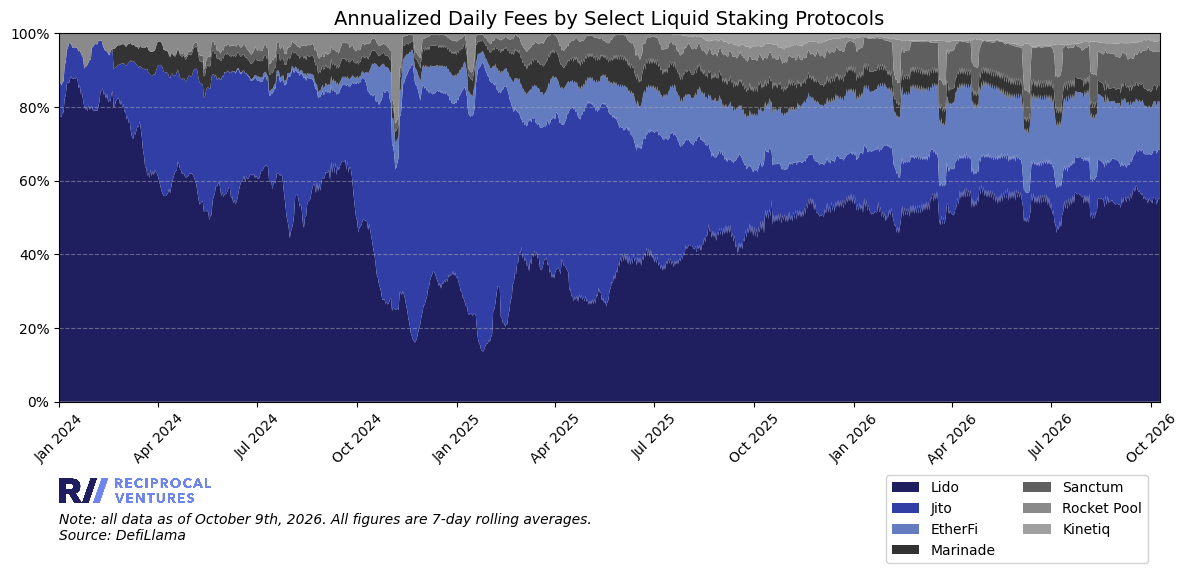

           date          Lido           Jito   Rocket Pool        Sanctum  \
1008 2026-10-05  1.802545e+06  426443.428571  92954.571429  294733.987143   
1009 2026-10-06  1.793805e+06  463779.000000  87843.000000  354027.987143   
1010 2026-10-07  1.778705e+06  431490.142857  88853.000000  296184.245714   
1011 2026-10-08  1.763894e+06  427310.857143  90735.285714  292349.674286   
1012 2026-10-09  1.736618e+06  416994.857143  93280.571429  288209.054286   

            EtherFi       Marinade       Kinetiq  
1008  429057.714286  146125.000000  74150.000000  
1009  428661.142857  145703.285714  80235.571429  
1010  434165.571429  144889.285714  70636.315714  
1011  416278.714286  142920.142857  67755.208571  
1012  412358.285714  140751.714286  67847.770000  


In [60]:
# Test the function to plot multi asset daily metric
metrics = ['dailyFees'] # 'dailyFees' or 'dailyRevenue' or 'dailyHoldersRevenue'
assets = {'lido': 'Lido',
            'jito': 'Jito',
            'rocket-pool': 'Rocket Pool',
            'sanctum': 'Sanctum',
            'ether-fi': 'EtherFi',
            'marinade': 'Marinade',
            'kinetiq': 'Kinetiq'}
start_date = '2024-01-01'
trailing_window = 7
chart_title = 'Annualized Daily Fees by Select Liquid Staking Protocols'

visualization.multi_asset_daily_metric(metrics, assets, start_date, trailing_window, plots_filepath, date, chart_title, stacked_100=False)
visualization.multi_asset_daily_metric(metrics, assets, start_date, trailing_window, plots_filepath, date, chart_title, stacked_100=True)

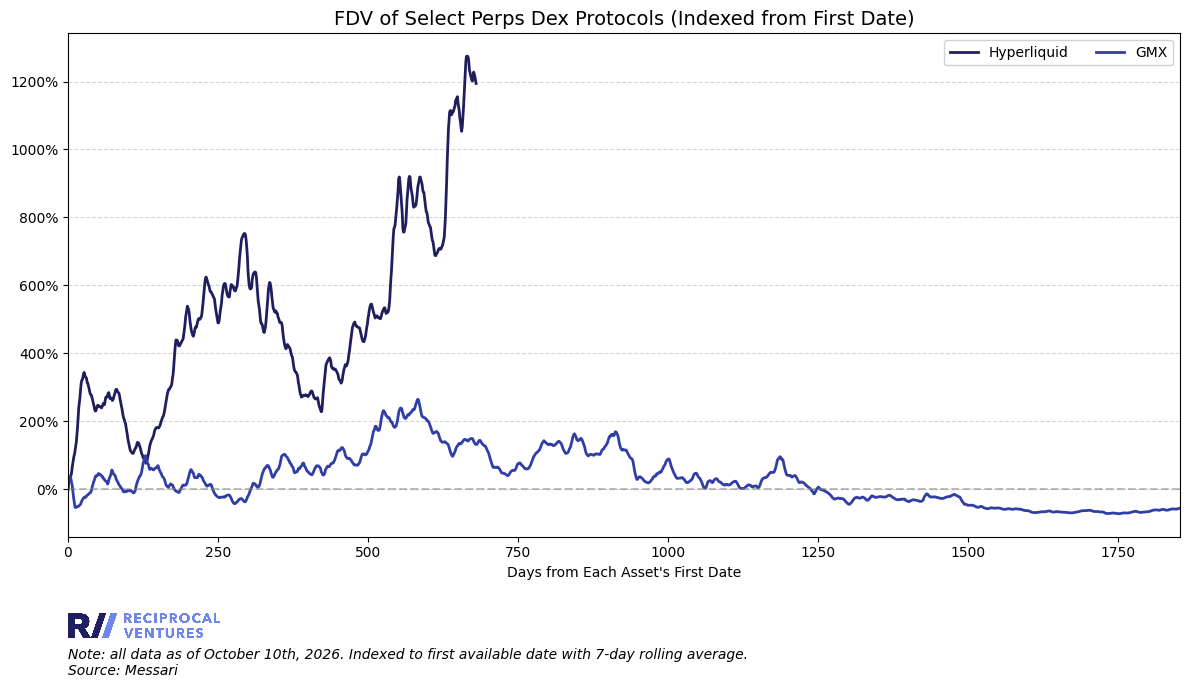

           date   Hyperliquid           GMX  Hyperliquid_days  \
1849 2026-10-06  8.647363e+10  8.666610e+07               676   
1850 2026-10-07  8.614179e+10  8.731298e+07               677   
1851 2026-10-08  8.566336e+10  8.768376e+07               678   
1852 2026-10-09  8.498408e+10  8.847138e+07               679   
1853 2026-10-10  8.429454e+10  8.887262e+07               680   

      Hyperliquid_pct  Hyperliquid_mult  GMX_days    GMX_pct  GMX_mult  
1849      1227.780133         13.277801      1849 -57.140453  0.428595  
1850      1222.684809         13.226848      1850 -56.820546  0.431795  
1851      1215.338679         13.153387      1851 -56.637181  0.433628  
1852      1204.908479         13.049085      1852 -56.247677  0.437523  
1853      1194.320790         12.943208      1853 -56.049245  0.439508  


In [61]:
# Test the function to plot multi asset daily metric
metrics = ['fdv'] # 'dailyFees' or 'dailyRevenue' or 'dailyHoldersRevenue' or 'tvl' or 'mcap' or 'fdv'
assets = {'hyperliquid': 'Hyperliquid',
          'gmx': 'GMX'}
start_date = '2023-01-01'
trailing_window = 7
chart_title = 'FDV of Select Perps Dex Protocols'
annualize = False
stacked_100=False
index_from_first_date=True


visualization.multi_asset_daily_metric(metrics, assets, start_date, trailing_window, plots_filepath, date, chart_title, stacked_100, annualize, index_from_first_date)

,Sale close,Committed,Accepted,Fill,1d,7d,30d,90d,Latest,Latest date,"Return / $1 committed, 30d","Return / $1 committed, latest"
,,,,,,,,,,,,
UMBRA,2025-10-10,$155m,$3.0m,1.9%,-,-,-,-,-,-,-,-
AVICI,2025-10-18,$34m,$3.5m,10.2%,-,-,-,-,-,-,-,-
LOYAL,2025-10-22,$76m,$2.5m,3.3%,-,-,-,-,-,-,-,-
SOLO,2025-11-18,$103m,$8.0m,7.8%,-,-,-,-,-,-,-,-
RNGR,2026-01-10,$86m,$8.0m,9.3%,-,-,-,-,-,-,-,-
P2P,2026-04-01,$7.2m,$6.0m,83.9%,-,-,-,-,-,-,-,-
LASO,2026-07-04,$26m,$1.0m,3.9%,-,-,-,-,-,-,-,-
CRED,2026-07-17,$33m,$4.0m,12.2%,-,-,-,-,-,-,-,-
launches with data,-,-,-,-,0,0,0,0,0,-,-,-


Note: data as of October 10th, 2026. Multiple = daily VWAP on the MetaDAO spot AMM on day k after the first trade / ICO price (USDC accepted / 10M tokens). Fill = USDC accepted / USDC committed. Return per $1 committed = fill x (multiple - 1); the refunded part earns nothing. Latest = last day the token traded on the MetaDAO AMM. Source: MetaDAO.
Table saved to: outputs/tables/metadao-ico-returns-min1m.png


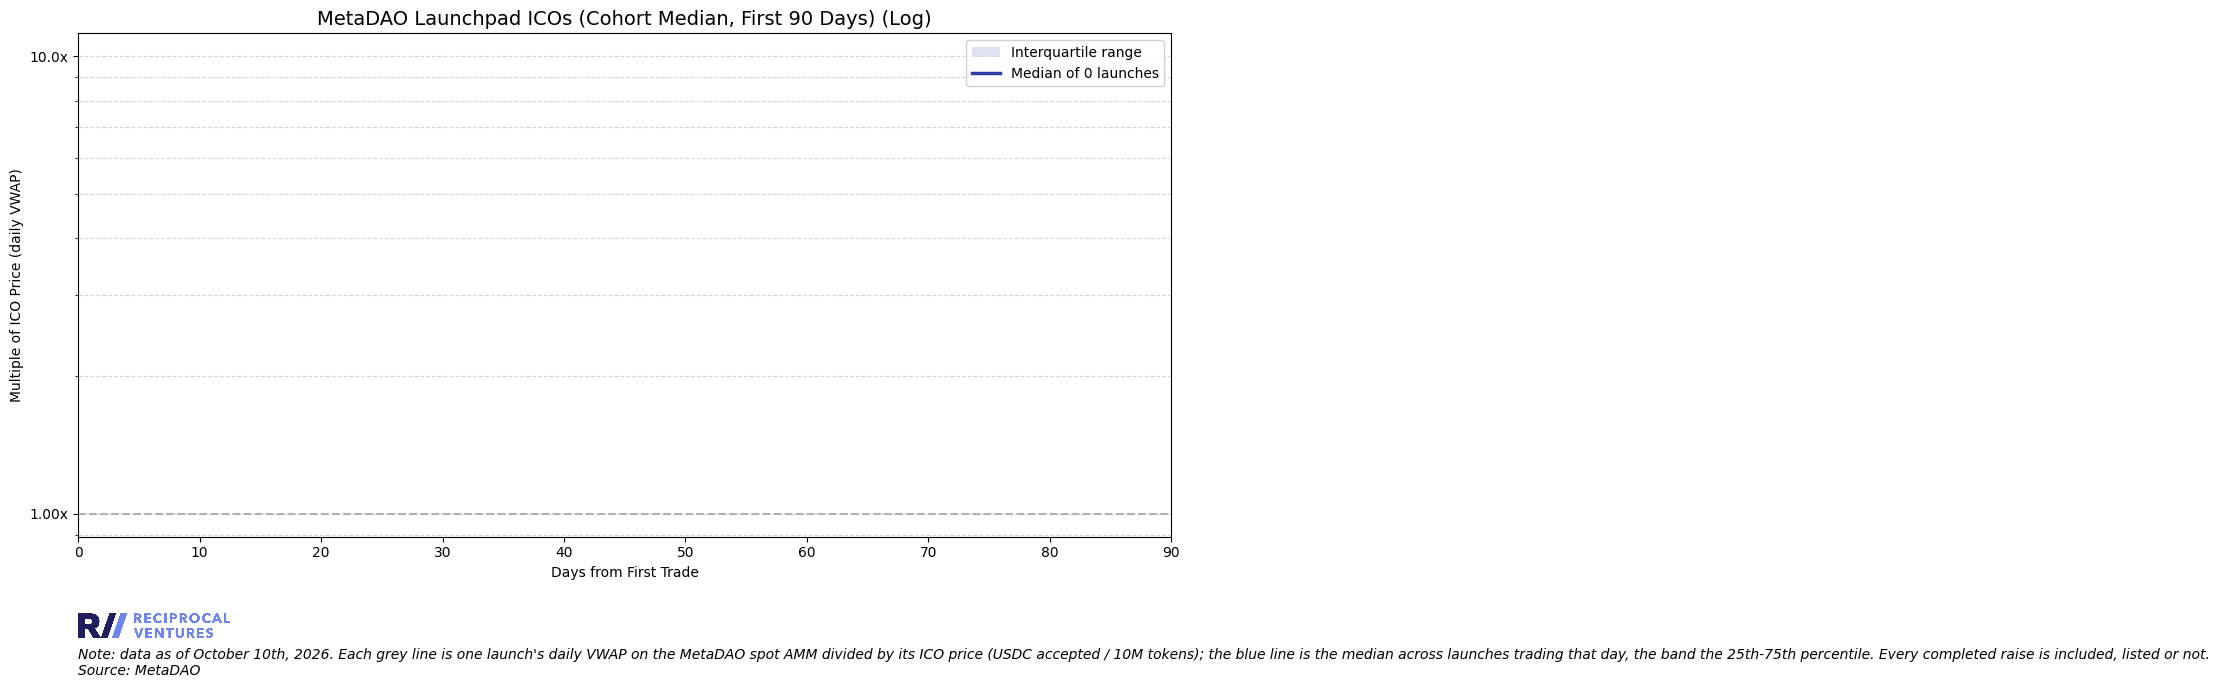

no launch is old enough for that horizon


In [62]:
# METADAO: is participating in MetaDAO ICOs profitable?
# Everyone in a MetaDAO sale pays the same price (ICO price = USDC accepted / 10M tokens), but
# allocations are pro rata to what the founder accepts, so a participant's return per dollar
# committed is fill_rate x (multiple - 1): an oversubscribed raise refunds most of the money.
# Multiples use the daily VWAP on the MetaDAO spot AMM (data/raw/metadao/market-data.json);
# the universe is every completed raise in config/metadao_launches.json that the pull collected,
# listed or not, filtered here by min_fundraise_usd. Run the METADAO cells in
# example-pull-raw-data.ipynb first.

horizon_days = 30              # headline horizon
horizons = (1, 7, 30, 90)      # columns in the table
n_days = 7                     # window of the hourly file the launch list comes from
min_fundraise_usd = 1_000_000  # only launches that raised (USDC accepted) at least this
launch_prices = f'data/processed/metadao/launch-prices-{n_days}d.json'
metadao_raw = 'data/raw/metadao'
chart_title = 'MetaDAO Launchpad ICOs'
cutoff_suffix = f'-min{min_fundraise_usd / 1e6:g}m' if min_fundraise_usd > 0 else ''

# 1. Headline table: multiples at each horizon, fill rate, return per $1 committed, cohort summary
returns = metadao.horizon_returns(launch_prices, metadao_raw, horizons=horizons, min_fundraise_usd=min_fundraise_usd)
summary = metadao.cohort_summary(returns, horizons=horizons)
note = (f'Note: data as of {date}. Multiple = daily VWAP on the MetaDAO spot AMM on day k after the first trade / ICO price '
        f'(USDC accepted / 10M tokens). Fill = USDC accepted / USDC committed. Return per $1 committed = fill x (multiple - 1); '
        f'the refunded part earns nothing. Latest = last day the token traded on the MetaDAO AMM. Source: MetaDAO.')
visualization.metadao_horizon_table(returns, summary, tables_filepath, date, horizons=horizons, headline=horizon_days,
                                    filename=f'metadao-ico-returns{cutoff_suffix}',
                                    title=f'{chart_title}: multiple of ICO price by horizon and return per $1 committed', note=note)

# 2. Cohort curve: median multiple of ICO price by day since first trade, with the interquartile band
daily, _ = metadao.daily_multiples(launch_prices, metadao_raw, max_days=90, min_fundraise_usd=min_fundraise_usd)
visualization.metadao_cohort_curve(daily, plots_filepath, date, chart_title, max_days=90, log_scale=True,
                                   filename=f'metadao-ico-cohort-curve{cutoff_suffix}')

# 3. Return per $1 committed at the headline horizon, one bar per launch
visualization.metadao_fill_adjusted_returns(returns, plots_filepath, date, chart_title, horizon=horizon_days,
                                            filename=f'metadao-ico-return-per-dollar{cutoff_suffix}')


below the $1.0m fundraise cutoff, not plotted: ZKFG, PAYS, RAWR, CARS, ORDR, NECTAR


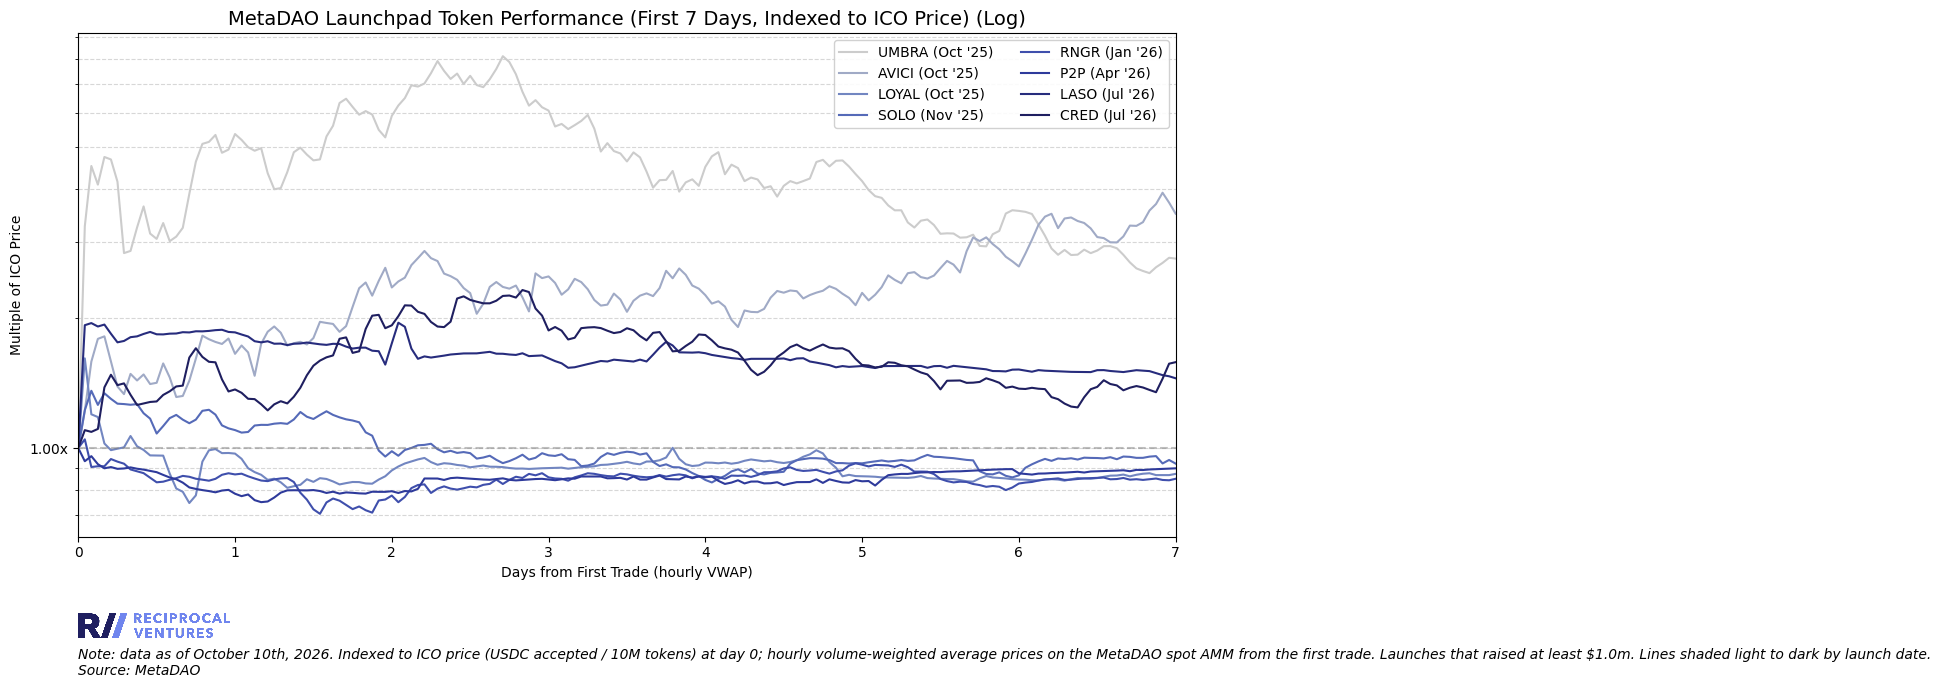

,Token,Sale close,USDC accepted,ICO price,Day 1,Day 2,Day 3,Day 4,Day 5,Day 6,Day 7,Best hour,Worst hour
#,,,,,,,,,,,,,
1,AVICI,2025-10-18,$3.5m,0.35,1.4x,2.1x,2.5x,2.4x,2.2x,2.7x,3.4x,3.9x,1.2x
2,UMBRA,2025-10-10,$3.0m,0.3,3.8x,5.3x,6.9x,4.7x,4.4x,3.4x,2.9x,8.1x,2.5x
3,LASO,2026-07-04,$1.0m,0.1,1.9x,1.7x,1.7x,1.6x,1.6x,1.5x,1.5x,2.0x,1.5x
4,CRED,2026-07-17,$4.0m,0.4,1.2x,1.7x,2.1x,1.8x,1.6x,1.4x,1.4x,2.3x,1.1x
5,SOLO,2025-11-18,$8.0m,0.8,1.2x,1.1x,1.0x,0.9x,0.9x,0.9x,0.9x,1.4x,0.8x
6,P2P,2026-04-01,$6.0m,0.6,0.9x,0.8x,0.8x,0.9x,0.8x,0.9x,0.9x,1.0x,0.7x
7,LOYAL,2025-10-22,$2.5m,0.25,1.3x,0.8x,0.9x,0.9x,0.9x,0.9x,0.9x,1.6x,0.7x
8,RNGR,2026-01-10,$8.0m,0.8,1.0x,0.7x,0.8x,0.9x,0.9x,0.8x,0.8x,1.0x,0.7x


8 protocols qualified; showing top 8.
Note: ICO price = USDC accepted / 10M tokens. Day k = volume-weighted average price over trading hours 24(k-1) to 24k on the MetaDAO spot AMM, divided by the ICO price; best/worst hour are hourly VWAPs. Source: MetaDAO.
Table saved to: outputs/tables/metadao-launch-first-7d-min1m.png


,ticker,sale_closed,usdc_accepted,ico_price_usd,day_1,day_2,day_3,day_4,day_5,day_6,day_7,max_hourly,min_hourly,hours_with_trades
#,,,,,,,,,,,,,,
1,AVICI,2025-10-18,3500000.0,0.35,1.405284,2.053403,2.463737,2.362002,2.155977,2.661073,3.393505,3.913397,1.218645,168
2,UMBRA,2025-10-10,3000000.0,0.30,3.833799,5.320082,6.915625,4.721429,4.370339,3.361241,2.917536,8.118021,2.546485,168
3,LASO,2026-07-04,1000000.0,0.10,1.922978,1.706429,1.720527,1.642848,1.599145,1.524717,1.483510,1.953666,1.451687,137
4,CRED,2026-07-17,4000000.0,0.40,1.214212,1.703564,2.120408,1.794396,1.627767,1.441813,1.384728,2.326489,1.090045,168
5,SOLO,2025-11-18,8000000.0,0.80,1.221642,1.054995,0.965920,0.904333,0.893595,0.892534,0.934913,1.357894,0.831892,168
6,P2P,2026-04-01,6000000.0,0.60,0.897602,0.771406,0.839867,0.851790,0.833344,0.854801,0.882847,0.957406,0.748800,161
7,LOYAL,2025-10-22,2500000.0,0.25,1.312837,0.842152,0.919404,0.948950,0.914191,0.850767,0.851687,1.614796,0.745361,158
8,RNGR,2026-01-10,8000000.0,0.80,0.990376,0.745515,0.808677,0.857985,0.877809,0.848060,0.843645,1.047517,0.703585,167


In [63]:
# Supporting detail: first n days of trading vs ICO price, hourly VWAP on the
# MetaDAO spot AMM, from data/processed/metadao/launch-prices-{n}d.json.
# Run the METADAO cells in example-pull-raw-data.ipynb first (they build that file).
# Day 0 = the ICO price (USDC accepted / 10M tokens); each line then follows the hourly
# volume-weighted average price from the first trade. The processed file holds every launch
# the pull included (config/metadao_launches.json, include=true); min_fundraise_usd below
# decides which of those are shown here, so the pull's own floor should stay at or under it.

chart_title = 'MetaDAO Launchpad Token Performance'  # n_days, min_fundraise_usd, launch_prices set above
color_by_launch_date = True    # shade lines light (earliest launch) -> dark (newest)
log_scale = True               # False: % change from ICO price; True: multiple of ICO price on a log axis

visualization.metadao_launch_performance(launch_prices, plots_filepath, date, chart_title, n_days=n_days, log_scale=log_scale, color_by_launch_date=color_by_launch_date, min_fundraise_usd=min_fundraise_usd)

# Table: multiple of the ICO price for each of the first n days (VWAP over each 24h window
# from the first trade), plus the best and worst hour in the window.
df = metadao.first_days_table(launch_prices, n_days=n_days, min_fundraise_usd=min_fundraise_usd).reset_index()
columns = {'ticker': ('Token', None), 'sale_closed': ('Sale close', None), 'usdc_accepted': ('USDC accepted', 'usd'), 'ico_price_usd': ('ICO price', None)}
columns.update({f'day_{k}': (f'Day {k}', 'mult') for k in range(1, n_days + 1)})
columns.update({'max_hourly': ('Best hour', 'mult'), 'min_hourly': ('Worst hour', 'mult')})
note = ('Note: ICO price = USDC accepted / 10M tokens. Day k = volume-weighted average price over trading hours '
        '24(k-1) to 24k on the MetaDAO spot AMM, divided by the ICO price; best/worst hour are hourly VWAPs. Source: MetaDAO.')
table_title = f'MetaDAO launches: first {n_days} days vs ICO price' + (f' (raised at least ${min_fundraise_usd / 1e6:g}M)' if min_fundraise_usd > 0 else '')
visualization.ranking_table(df, f'day_{n_days}', 50, table_title, columns, tables_filepath, date, f'metadao-launch-first-{n_days}d{cutoff_suffix}', note=note)


aqav2 (USDC): 45 active days in 2 period(s), 1 paid; identity holds to 9.9e-09 on every day; base = treasury balance at midnight on all 56 days read (52 exact to the cent); tie-out clean


,Start,End,Paid on,Days,Status,Accrued (USDC),Avg balance,Avg rate,Paid (USDC),Paid - accrued
,,,,,,,,,,
Period 1,2026-08-27,2026-09-25,2026-10-03,30 / 30,paid,"$14,580,777",$5.6b,3.142%,"$14,580,777",$0
Period 2,2026-09-26,2026-10-25,2026-11-02,15 / 30,in-progress,"$8,041,252",$6.1b,3.232%,-,-


Note: data as of October 10th, 2026. Interest = treasury balance x AQA rate / 365.25 per UTC date, summed over each 30-day interval from activation (2026-08-27); paid to the Assistance Fund 8 days after the interval's last date. The charged balance is the treasury deployer's native-USDC balance on HyperEVM at 00:00 UTC, 90% of the USDC backing HyperCore.
Source: Hyperliquid API (aqav2InterestHistory, userNonFundingLedgerUpdates); HyperEVM archive RPC; FRED (EFFR)
Table saved to: outputs/tables/hyperliquid-aqav2-periods.png


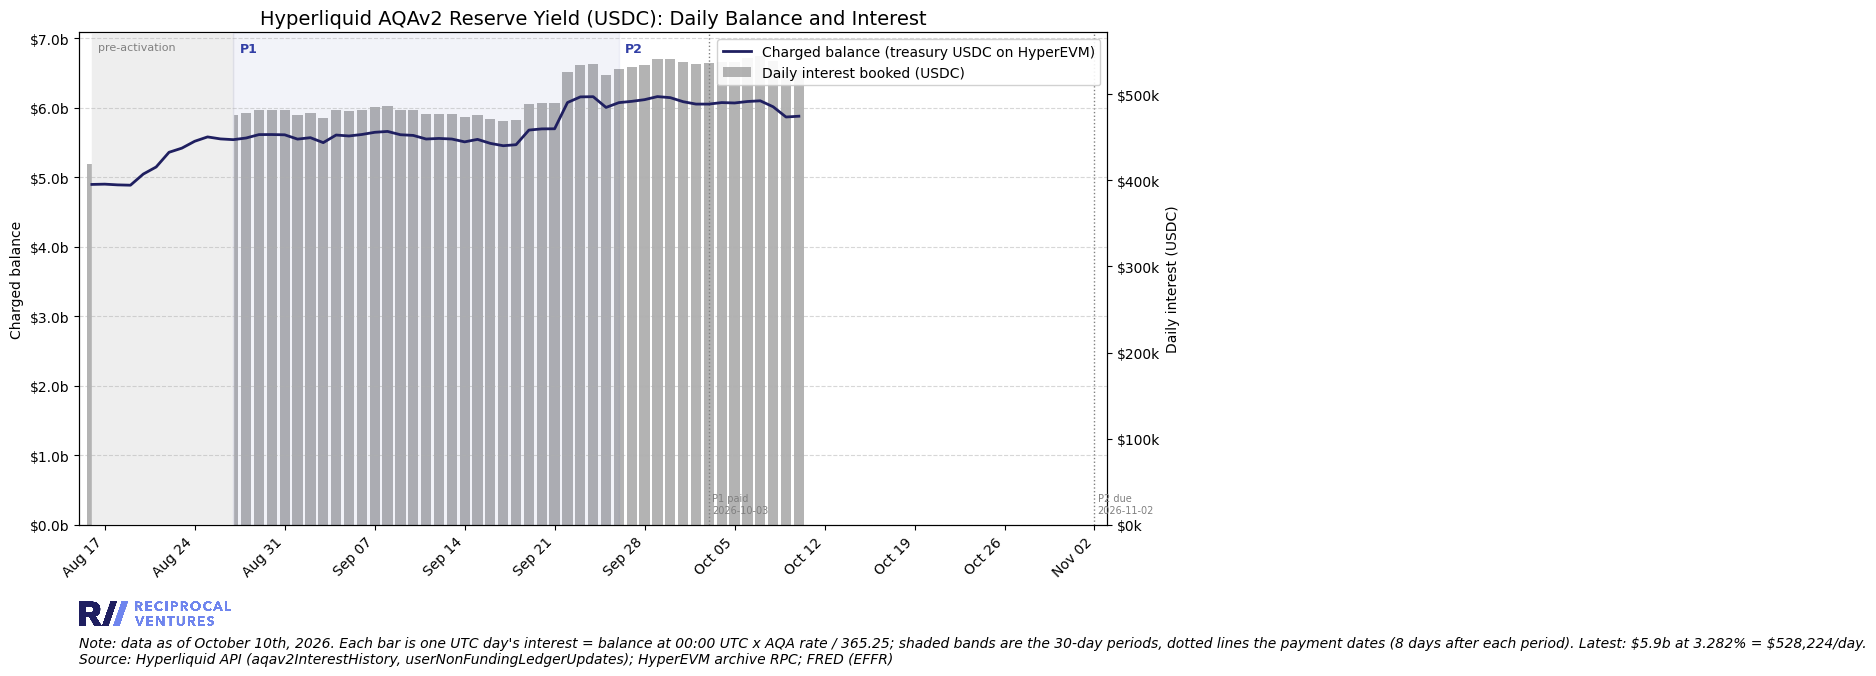

In [64]:
# HYPERLIQUID: AQAv2 reserve yield, what accrued in each 30-day period and what the next payments look like.
# The node charges the treasury deployer's HyperEVM USDC balance (90% of the USDC backing HyperCore) at the
# cost-adjusted AQA rate each UTC day; the AQA rate tracks a trailing mean of Fed funds minus a fixed cost,
# so the forward estimate is driven by a Fed path applied at FOMC decision dates. Run the HYPERLIQUID cells
# in example-pull-raw-data.ipynb first.

hyperliquid_raw = 'data/raw/hyperliquid'
token = 0
n_periods = 12                              # in-progress period + 11 projected (~1 year)
cost_bp = 50                                # fixed haircut below EFFR (observed before the Sep 17 move: 49.5bp)
treasury_cagr = 0.0                         # annual growth of the charged balance; 0 = flat at the latest reading
scenarios = hyperliquid.DEFAULT_SCENARIOS   # Flat / Cuts (-25bp at each of the next 4 meetings) / Hikes (+25bp x 2)
chart_title = 'Hyperliquid AQAv2 Reserve Yield (USDC)'

# 1. Official daily series with the treasury-balance tie-out, payments, periods, checks
treasury = hyperliquid.load_treasury_balances(hyperliquid_raw, token)
daily = hyperliquid.aqav2_daily(hyperliquid.load_interest_history(hyperliquid_raw, token), treasury)
payments = hyperliquid.aqav2_payments(hyperliquid.load_ledger(hyperliquid_raw, token), token)
periods = hyperliquid.aqav2_periods(daily, payments)
issues = hyperliquid.check_aqav2(daily, periods, payments)
assert periods is not None and abs(periods.loc[1, 'interest_accrued'] - 14_580_776.69) < 0.01, periods.loc[1, 'interest_accrued']
assert not issues, issues

visualization.hyperliquid_aqav2_period_table(periods, tables_filepath, date, title=f'{chart_title}: accrued interest by 30-day period')
visualization.hyperliquid_aqav2_daily_chart(daily, periods, plots_filepath, date, chart_title)

AQA rate model: EFFR trailing 39d mean - 50bp (implied pre-move cost 49.5bp); RMSE 0.6bp over 56 days; latest model 3.277% vs actual 3.282%; steady state at EFFR 3.88% = 3.380%
per +25bp in EFFR at the 2026-10-10 base of $5.88b: $40k/day, $1.21m/period, $14.70m/yr (+7.6% of the current rate)


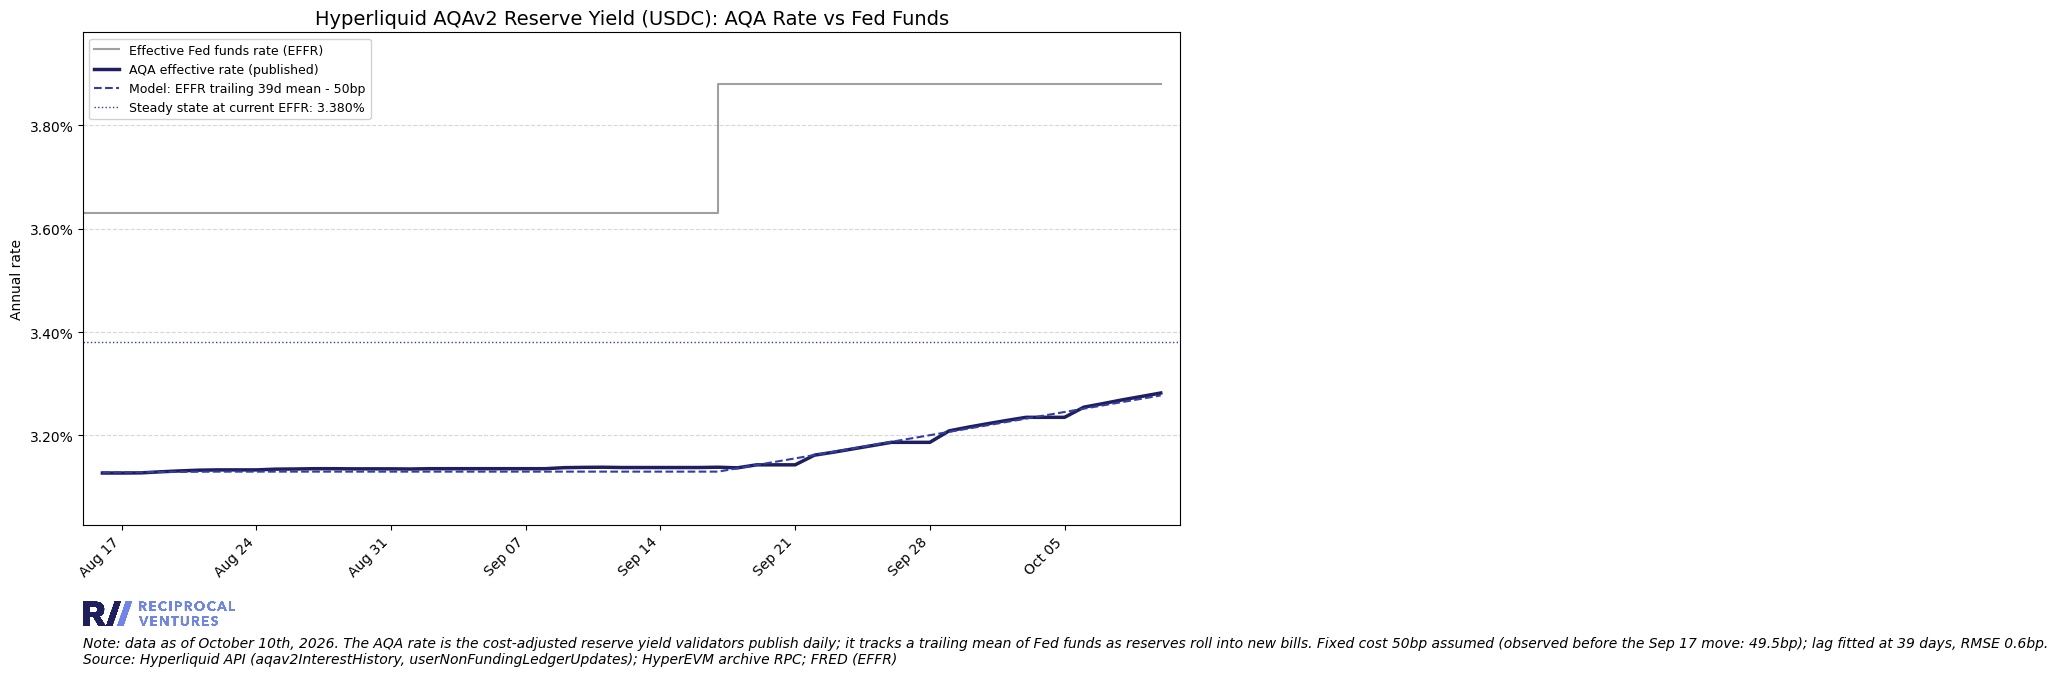

,Days actual / projected,Flat (USDC),Flat avg rate,Cuts (USDC),Cuts avg rate,Hikes (USDC),Hikes avg rate
,,,,,,,
"P2: 2026-09-26 to 2026-10-25, paid 2026-11-02",15 / 15,"$16,077,067",3.281%,"$16,077,067",3.281%,"$16,077,067",3.281%
"P3: 2026-10-26 to 2026-11-24, paid 2026-12-02",0 / 30,"$16,319,230",3.380%,"$15,957,117",3.305%,"$16,681,343",3.455%
"P4: 2026-11-25 to 2026-12-24, paid 2027-01-01",0 / 30,"$16,319,230",3.380%,"$15,084,332",3.124%,"$17,554,129",3.636%
"P5: 2026-12-25 to 2027-01-23, paid 2027-01-31",0 / 30,"$16,319,230",3.380%,"$14,214,641",2.944%,"$18,423,819",3.816%
"P6: 2027-01-24 to 2027-02-22, paid 2027-03-02",0 / 30,"$16,319,230",3.380%,"$13,569,853",2.811%,"$18,733,318",3.880%
"P7: 2027-02-23 to 2027-03-24, paid 2027-04-01",0 / 30,"$16,319,230",3.380%,"$12,770,316",2.645%,"$18,733,318",3.880%
"P8: 2027-03-25 to 2027-04-23, paid 2027-05-01",0 / 30,"$16,319,230",3.380%,"$12,032,678",2.492%,"$18,733,318",3.880%
"P9: 2027-04-24 to 2027-05-23, paid 2027-05-31",0 / 30,"$16,319,230",3.380%,"$11,494,151",2.381%,"$18,733,318",3.880%
"P10: 2027-05-24 to 2027-06-22, paid 2027-06-30",0 / 30,"$16,319,230",3.380%,"$11,491,056",2.380%,"$18,733,318",3.880%


Note: data as of October 10th, 2026. Days already published use the node's actual interest; remaining days are balance x rate / 365.25 with the balance held at $5.9b (2026-10-10) and the rate = EFFR trailing 39d mean - 50bp, EFFR starting at 3.88%.
Flat: no Fed moves. Cuts: -25bp Oct 28 2026, -25bp Dec 09 2026, -25bp Jan 27 2027, -25bp Mar 17 2027. Hikes: +25bp Oct 28 2026, +25bp Dec 09 2026.
Each Fed move applies the day after the decision and passes through over the lag. 365.25-day count as the node uses (hl.eco's estimator uses 365).
Source: Hyperliquid API (aqav2InterestHistory, userNonFundingLedgerUpdates); HyperEVM archive RPC; FRED (EFFR)
Table saved to: outputs/tables/hyperliquid-aqav2-estimate.png


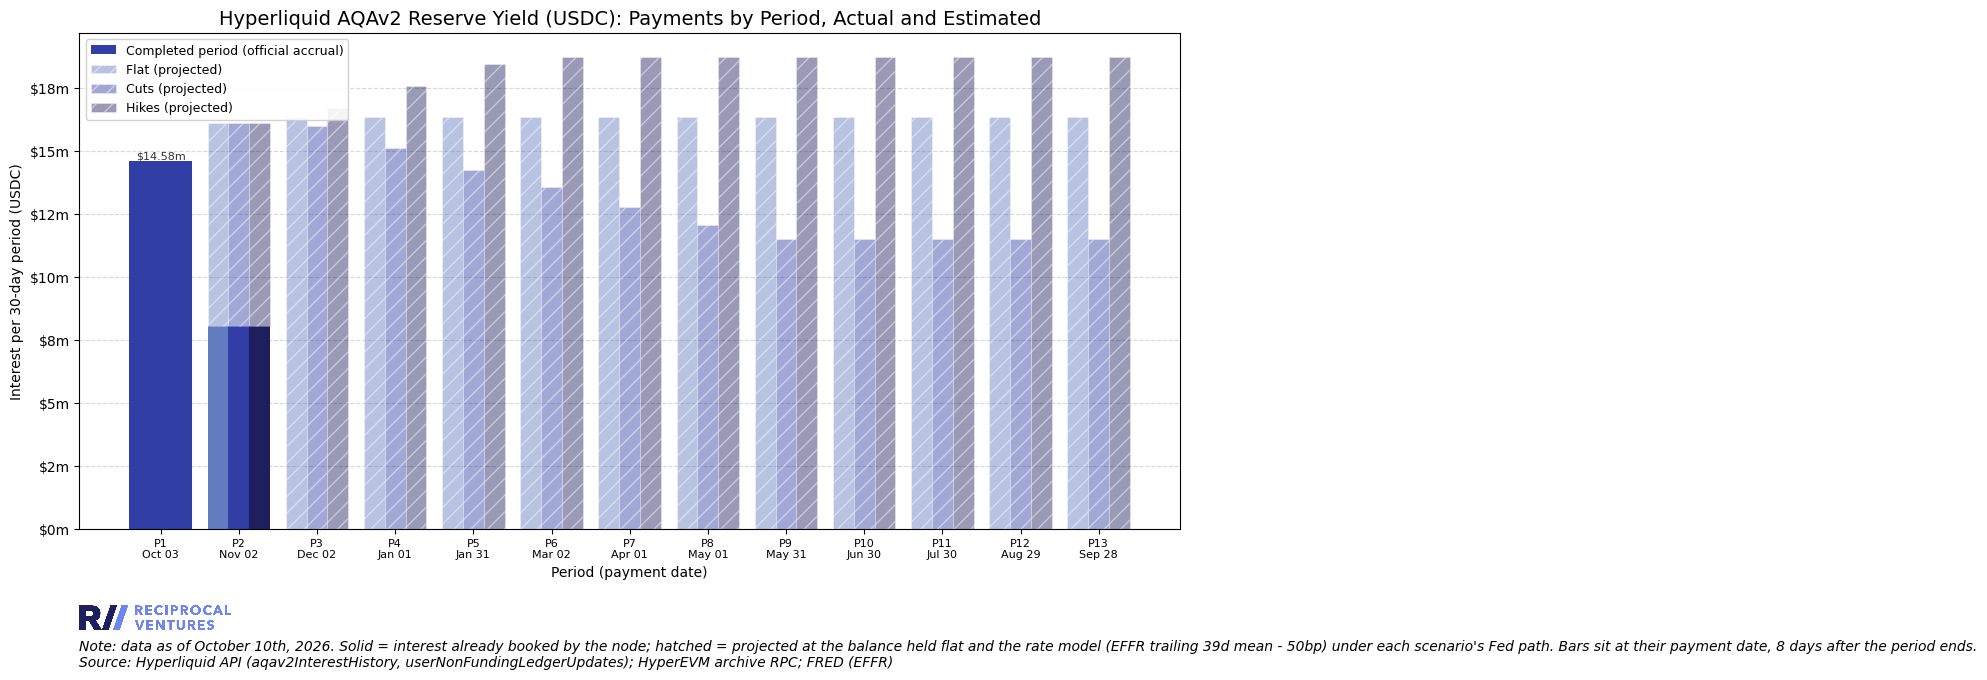

In [65]:
# 2. Rate model and forward estimate. calibrate_passthrough fits only the lag L (the fixed cost is yours);
# sensitivity_per_25bp prints what one Fed move is worth at the latest balance once it has passed through.
ref = hyperliquid.load_reference_rate(f'data/raw/fred/{hyperliquid.DEFAULT_REFERENCE_SERIES}.json')
calib = hyperliquid.calibrate_passthrough(daily, ref, cost_bp=cost_bp)
hyperliquid.sensitivity_per_25bp(daily)
visualization.hyperliquid_aqav2_rate_chart(daily, ref, calib, plots_filepath, date, chart_title)

est = hyperliquid.estimate_aqav2_payments(daily, ref, n_periods=n_periods, cost_bp=cost_bp,
                                          passthrough_days=calib['passthrough_days'], treasury_cagr=treasury_cagr,
                                          scenarios=scenarios)
visualization.hyperliquid_aqav2_estimate_table(est, tables_filepath, date, title=f'{chart_title}: estimated payments to the Assistance Fund')
visualization.hyperliquid_aqav2_payments_chart(periods, est, plots_filepath, date, chart_title)

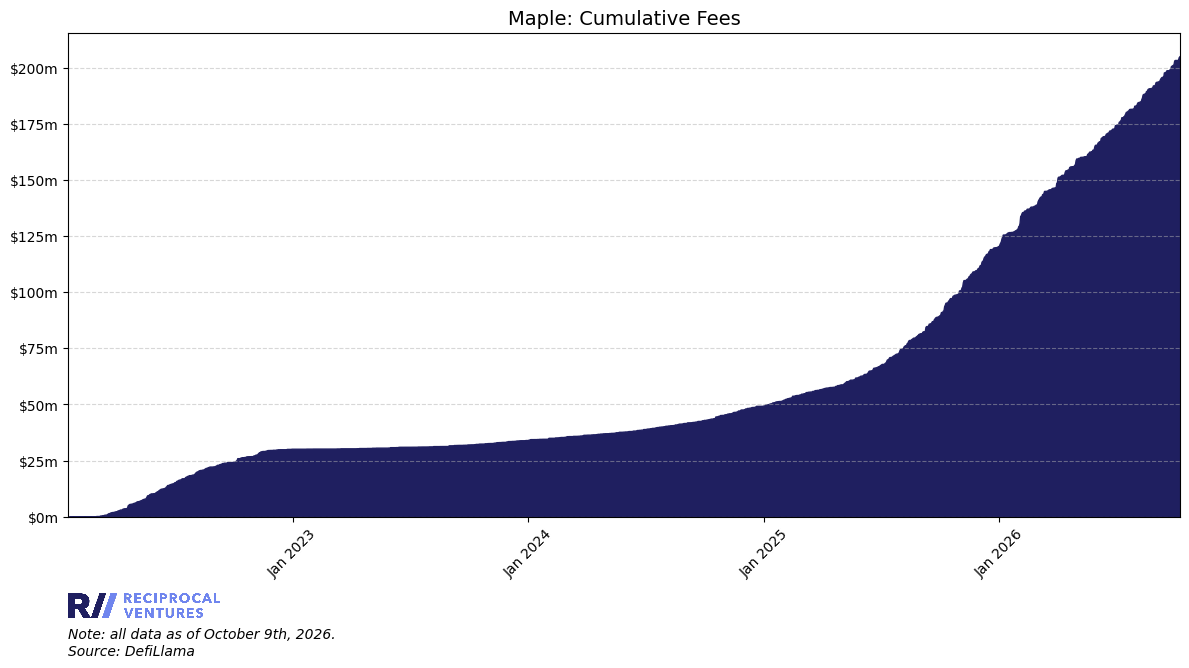

           date       fees  cumulative-fees
1721 2026-10-05    10625.0     2.034541e+08
1722 2026-10-06   113347.0     2.035674e+08
1723 2026-10-07  1139004.0     2.047064e+08
1724 2026-10-08   255472.0     2.049619e+08
1725 2026-10-09   371221.0     2.053331e+08
Latest Maple Cumulative fees: $205.3m


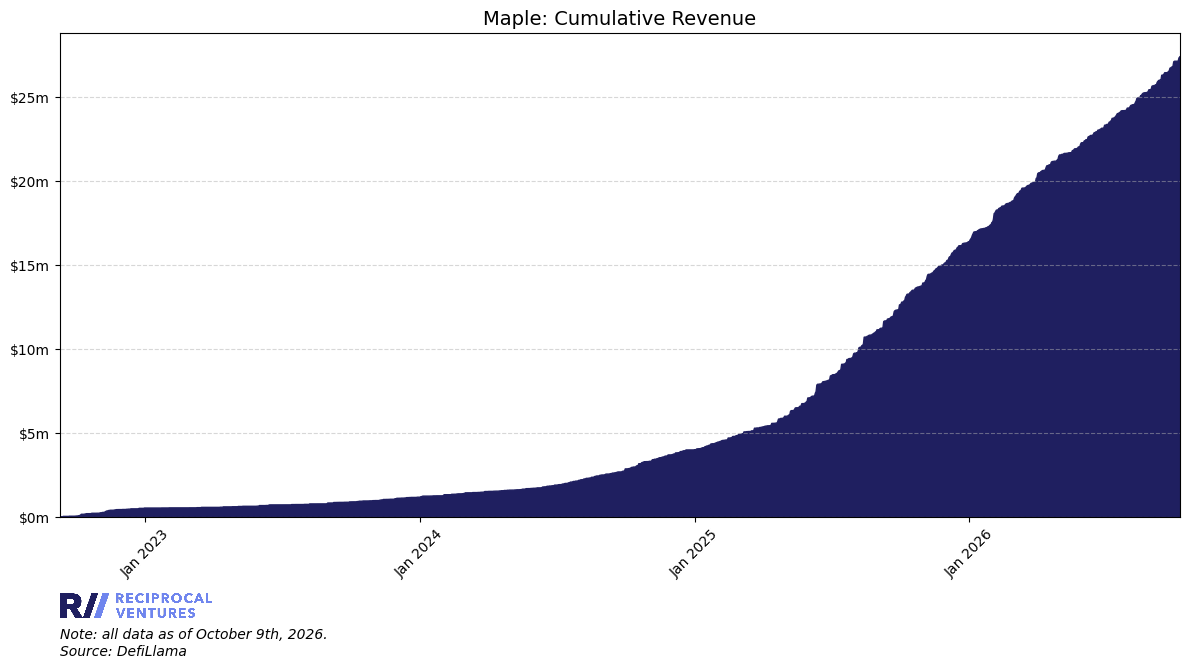

           date   revenue  cumulative-revenue
1721 2026-10-05    1732.0          27146687.7
1722 2026-10-06   18423.0          27165110.7
1723 2026-10-07  180626.0          27345736.7
1724 2026-10-08   45619.0          27391355.7
1725 2026-10-09   50642.0          27441997.7
Latest Maple Cumulative revenue: $27.4m


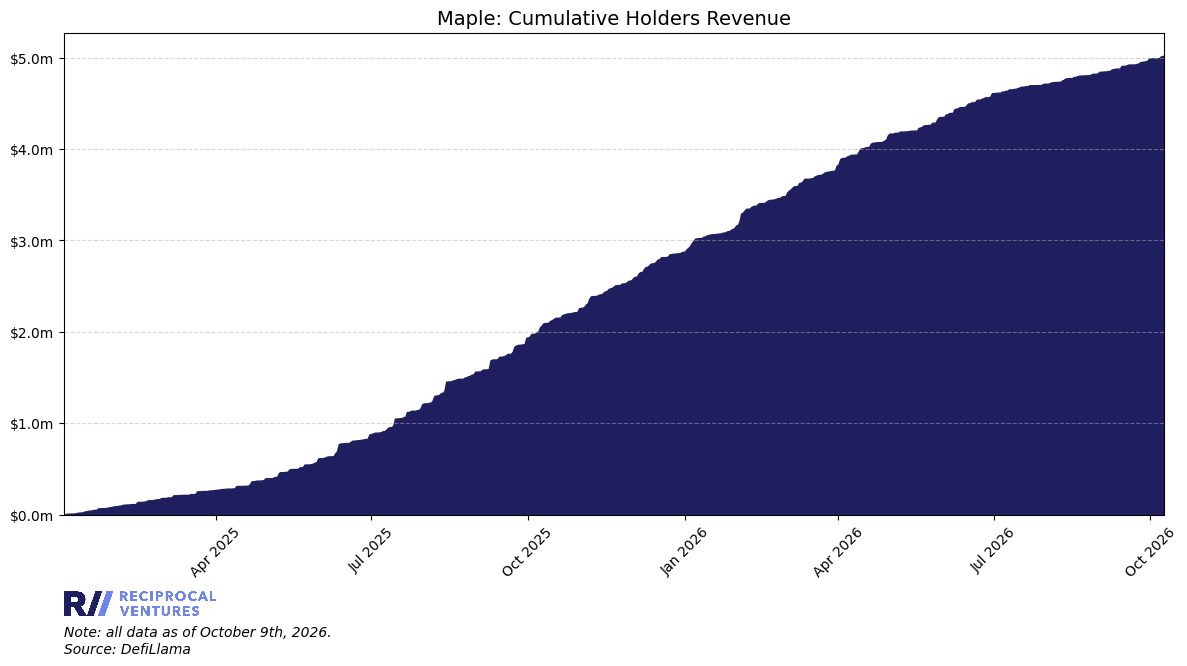

           date  holders-revenue  cumulative-holders-revenue
1721 2026-10-05            173.0                  4992094.25
1722 2026-10-06           1842.0                  4993936.25
1723 2026-10-07          18063.0                  5011999.25
1724 2026-10-08           4562.0                  5016561.25
1725 2026-10-09           5064.0                  5021625.25
Latest Maple Cumulative holders-revenue: $5.0m


In [66]:
# Test the function to plot cumulative metric

metrics = ['dailyFees','dailyRevenue', 'dailyHoldersRevenue'] # 'dailyFees' or 'dailyRevenue' or 'dailyHoldersRevenue'
assets = {'maple-finance': 'Maple'}

visualization.single_asset_cumulitative_metric(metrics, assets, plots_filepath, date)

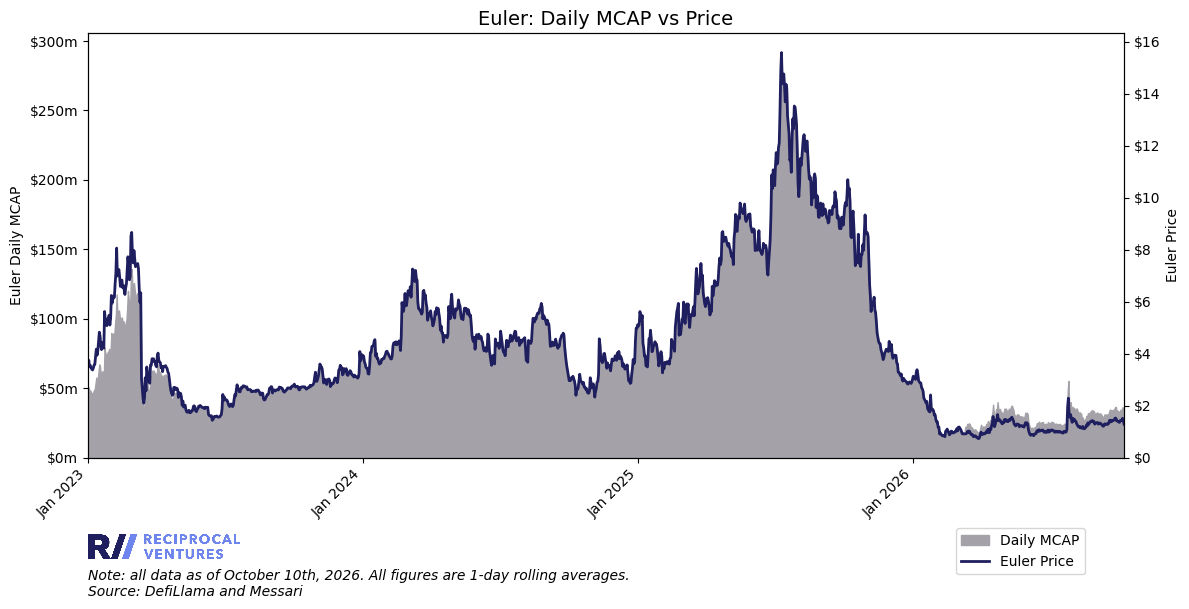

           date     price  price-1d      mcap     mcap-1d
1563 2026-10-04  1.426465  1.426465  34284724  34284724.0
1564 2026-10-05  1.447481  1.447481  34789847  34789847.0
1565 2026-10-06  1.514289  1.514289  36395553  36395553.0
1566 2026-10-07  1.436991  1.436991  34537723  34537723.0
1567 2026-10-08  1.287770  1.287770  30951233  30951233.0


In [67]:
# Test plotting top metric vs bottom for a given asset
asset_slug = 'euler'
asset_name = 'Euler'
bottom_metric = 'mcap' # can be fees, revenue, holders-revenue, price, mcap, or fdv
top_metric = 'price' # can be price, mcap, or fdv
start_date = '2023-01-01'
trailing_window = 1


visualization.asset_top_metric_vs_bottom_metric(asset_slug, asset_name, bottom_metric, top_metric, start_date, trailing_window, plots_filepath, date)

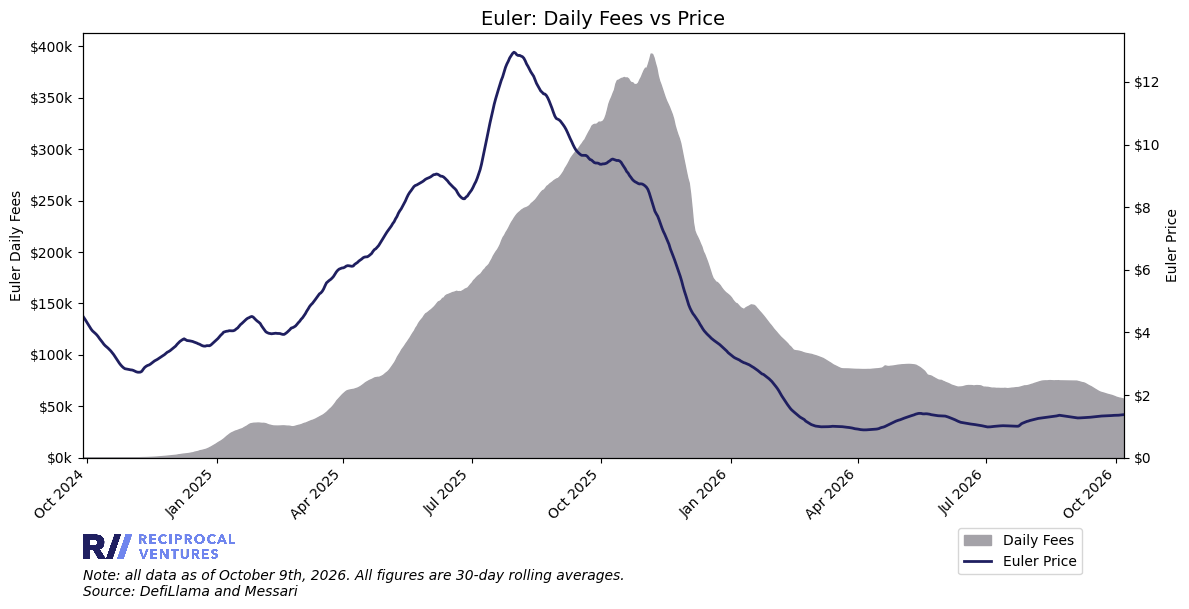

          date     price  price-30d   fees      fees-30d
753 2026-10-03  1.431909   1.356381  58534  58529.066667
754 2026-10-04  1.426465   1.360972  59343  58261.666667
755 2026-10-05  1.447481   1.365254  58777  57948.000000
756 2026-10-06  1.514289   1.371380  58706  57619.833333
757 2026-10-07  1.436991   1.375548  57404  57269.000000


In [68]:
# Test plotting top metric vs bottom for a given asset
asset_slug = 'euler'
asset_name = 'Euler'
bottom_metric = 'fees' # can be fees, revenue, holders-revenue, price, mcap, or fdv
top_metric = 'price' # can be price, mcap, or fdv
start_date = '2023-01-01'
trailing_window = 30


visualization.asset_top_metric_vs_bottom_metric(asset_slug, asset_name, bottom_metric, top_metric, start_date, trailing_window, plots_filepath, date)

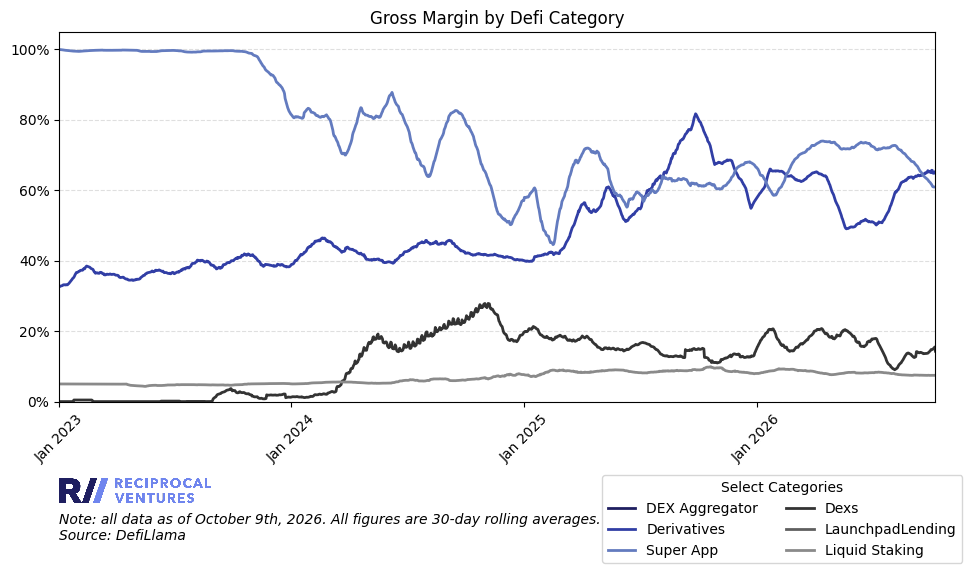

           date DEX Aggregator-gross-margin-30d  Derivatives-gross-margin-30d  \
2103 2026-10-05                            None                      0.647975   
2104 2026-10-06                            None                      0.647544   
2105 2026-10-07                            None                      0.647739   
2106 2026-10-08                            None                      0.649989   
2107 2026-10-09                            None                      0.652578   

      Super App-gross-margin-30d  Dexs-gross-margin-30d  \
2103                    0.609173               0.148857   
2104                    0.608785               0.150688   
2105                    0.608727               0.152850   
2106                    0.608642               0.154943   
2107                    0.608529               0.142831   

     LaunchpadLending-gross-margin-30d  Liquid Staking-gross-margin-30d  
2103                              None                         0.074471  
2104      

In [69]:
# Test function to plot gross margins by category
categories = ['DEX Aggregator',
              'Derivatives',
              'Super App',
              'Dexs',
              'Launchpad',
              'Lending',
              'Liquid Staking'
              ]
start_date = '2023-01-01'

visualization.category_gross_margin_comparison(categories, start_date, plots_filepath, date)

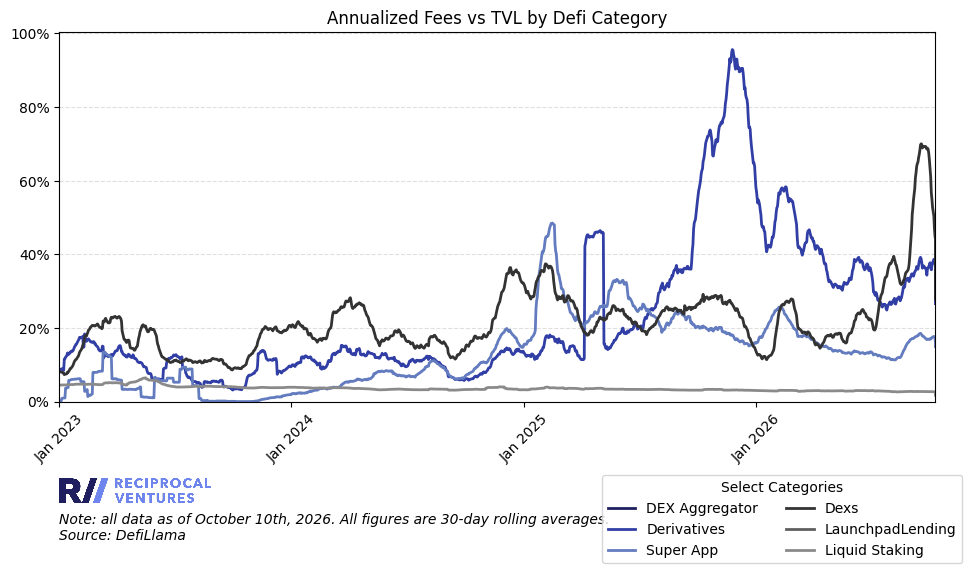

                    date DEX Aggregator-fees-to-tvl-30d  \
2267 2026-10-10 13:39:11                           None   
2268 2026-10-10 13:40:11                           None   
2269 2026-10-10 13:41:11                           None   
2270 2026-10-10 13:42:11                           None   
2271 2026-10-10 13:43:11                           None   

      Derivatives-fees-to-tvl-30d  Super App-fees-to-tvl-30d  \
2267                     0.282311                   0.155053   
2268                     0.282311                   0.155053   
2269                     0.282311                   0.155053   
2270                     0.266009                   0.155053   
2271                     0.266009                   0.149234   

      Dexs-fees-to-tvl-30d LaunchpadLending-fees-to-tvl-30d  \
2267              0.277677                             None   
2268              0.277677                             None   
2269              0.277677                             None   
2270    

In [70]:
visualization.category_fees_to_tvl_comparison(categories, start_date, plots_filepath, date)

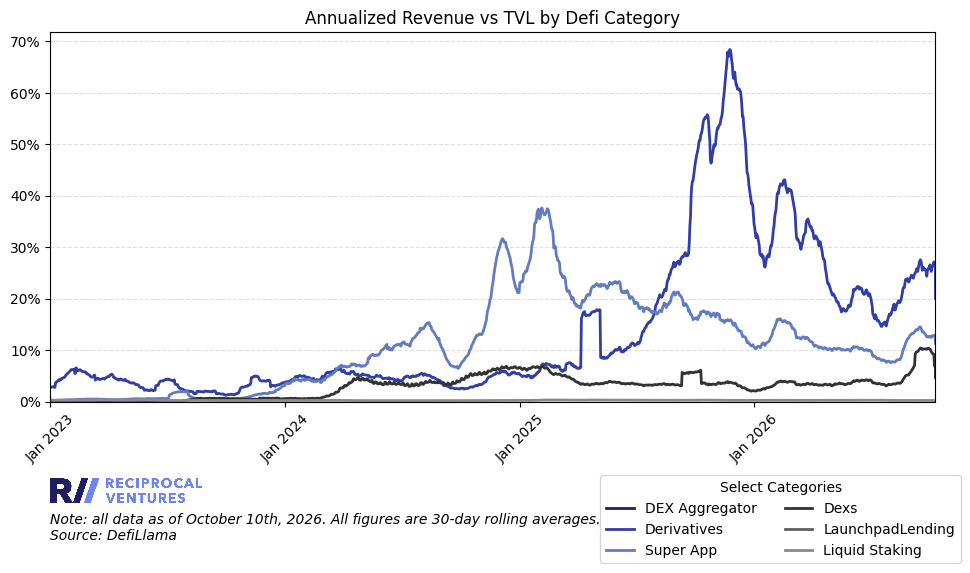

                    date DEX Aggregator-revenue-to-tvl-30d  \
2268 2026-10-10 13:39:11                              None   
2269 2026-10-10 13:40:11                              None   
2270 2026-10-10 13:41:11                              None   
2271 2026-10-10 13:42:11                              None   
2272 2026-10-10 13:43:11                              None   

      Derivatives-revenue-to-tvl-30d  Super App-revenue-to-tvl-30d  \
2268                        0.208908                      0.116228   
2269                        0.208908                      0.116228   
2270                        0.208908                      0.116228   
2271                        0.200138                      0.116228   
2272                        0.200138                      0.113297   

      Dexs-revenue-to-tvl-30d LaunchpadLending-revenue-to-tvl-30d  \
2268                 0.046215                                None   
2269                 0.046215                                None   

In [71]:
visualization.category_revenue_to_tvl_comparison(categories, start_date, plots_filepath, date)

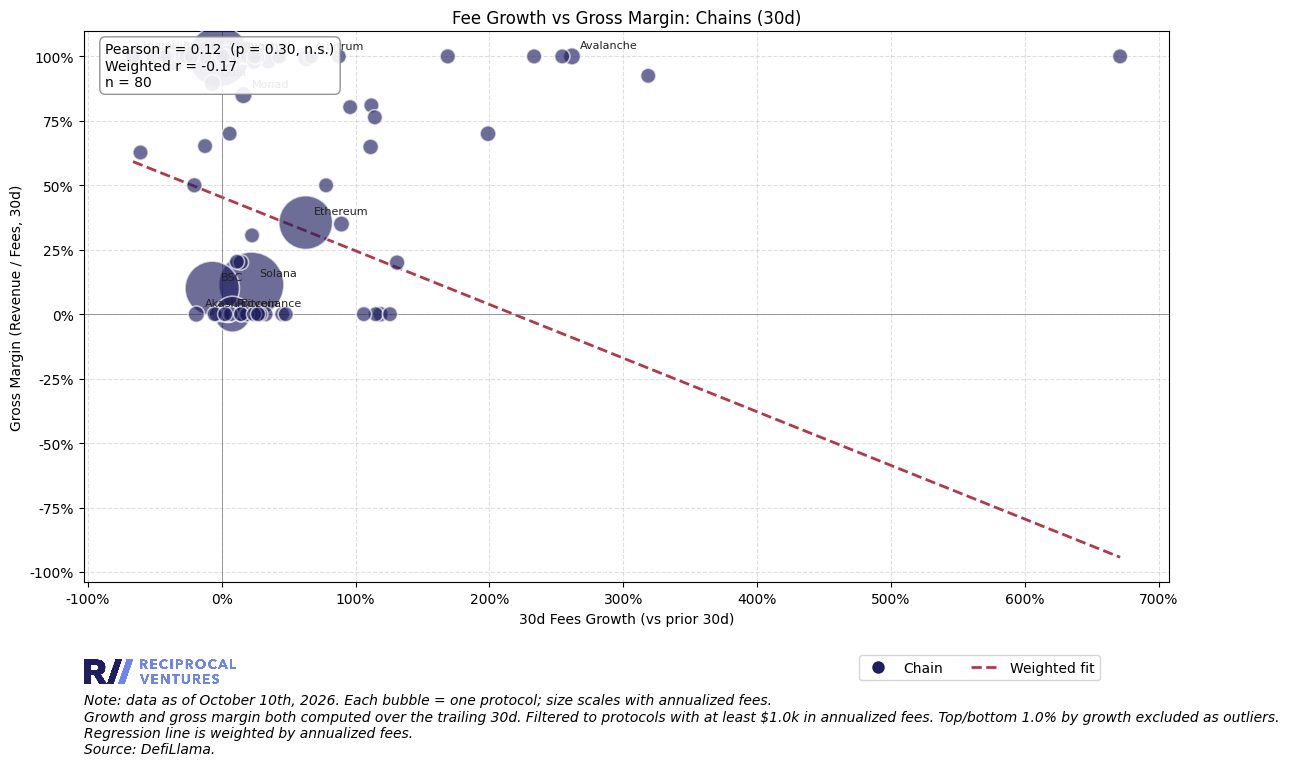


Protocols dropped during filtering:
  - no_revenue: 45
  - below_min_fees: 36
  - missing_growth: 77
  - invalid_margin: 1
  - wrong_category: 2742

Growth outliers dropped (top/bottom 1.0% by growth):
  - Robinhood Chain                     Chain                  growth=     -77%
  - BOB                                 Chain                  growth=   +1039%

Protocol data (showing top 20 of 80 by annualized fees):
      protocol category annualized_fees growth gross_margin
        Solana    Chain           $338m    22%          11%
          Tron    Chain           $291m    -2%         100%
           BSC    Chain           $230m    -7%          10%
      Ethereum    Chain           $224m    63%          36%
       Bitcoin    Chain            $89m     8%           0%
          Base    Chain            $39m   -35%          99%
       Polygon    Chain            $28m     4%         100%
      Arbitrum    Chain             $8m    63%          99%
Hyperliquid L1    Chain             $8m

{'data':             protocol category  annualized_fees  growth  gross_margin  \
 0             Solana    Chain     3.375008e+08  0.2211      0.114569   
 1               Tron    Chain     2.910845e+08 -0.0205      1.000000   
 2                BSC    Chain     2.298828e+08 -0.0711      0.100000   
 3           Ethereum    Chain     2.237394e+08  0.6273      0.355270   
 4            Bitcoin    Chain     8.906742e+07  0.0797      0.000000   
 ..               ...      ...              ...     ...           ...   
 75              Boba    Chain     2.781178e+03 -0.6629      1.000000   
 76           Fraxtal    Chain     2.054220e+03  0.6690      1.000000   
 77              CORE    Chain     1.789595e+03 -0.4292      1.000000   
 78  Gravity by Galxe    Chain     1.404763e+03 -0.2250      1.000000   
 79            Fantom    Chain     1.038182e+03  0.4783      0.000000   
 
                 slug       date  
 0             solana 2026-10-10  
 1               tron 2026-10-10  
 2       

In [72]:
# Test function to scatter fee growth vs gross margin (does growth correlate with profitability?)
# Categories are DefiLlama category names. Common options: 'Derivatives', 'Lending', 'Liquid Staking',
# 'Chain', 'Dexs', 'DEX Aggregator', 'CDP', 'Yield', 'RWA'. Set to None for every category in the data.
categories_to_plot = ['Chain']
trailing_window = 30  # one of: 1, 7, 30 - the trailing window for both growth and gross margin
min_annualized_fees = 1000  # filters out long-tail noise; lower for more coverage
chart_title = f'Fee Growth vs Gross Margin: Chains ({trailing_window}d)'

visualization.growth_vs_margin_correlation(
    categories=categories_to_plot,
    trailing_window=trailing_window,
    min_annualized_fees=min_annualized_fees,
    plots_filepath=plots_filepath,
    tables_filepath=tables_filepath,
    date=date,
    chart_title=chart_title,
)

In [73]:
# DEXS

Saved processed data to: data/processed/open-interest/oi-by-dex-processed.json


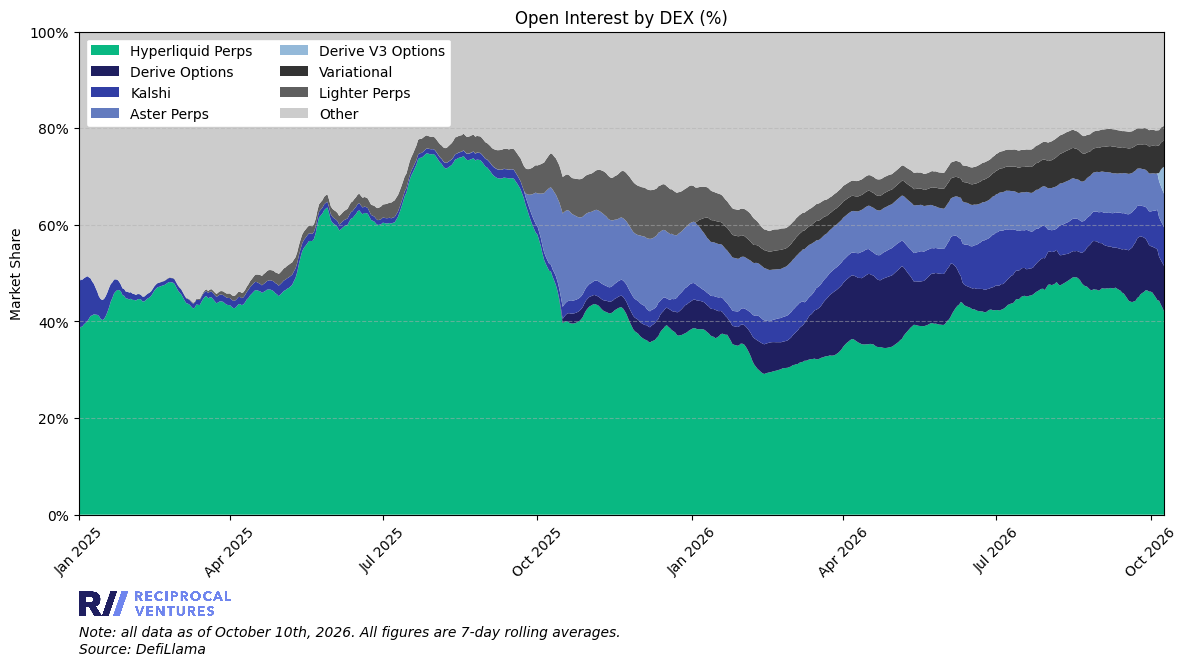

dex       date  Hyperliquid Perps  Derive Options    Kalshi  Aster Perps  \
637 2026-09-30          46.180625        9.661185  6.961311     7.840381   
638 2026-10-01          46.182472        9.417524  7.172108     7.853874   
639 2026-10-02          45.999822        9.498185  7.362600     7.807981   
640 2026-10-03          45.485401        9.824916  7.628903     7.723606   
641 2026-10-04          44.990784       10.163461  7.804542     7.641963   
642 2026-10-05          44.401075       10.475531  8.261939     7.545367   
643 2026-10-06          44.302020        9.101879  8.165449     7.465759   
644 2026-10-07          43.546581        9.204516  8.075639     7.267011   
645 2026-10-08          42.839909        9.272327  8.039575     7.063832   
646 2026-10-09          42.019716        9.447796  7.980487     6.958024   

dex  Derive V3 Options  Variational  Lighter Perps      Other  
637           0.000000     5.591059       3.366334  20.399106  
638           0.000000     5.671320

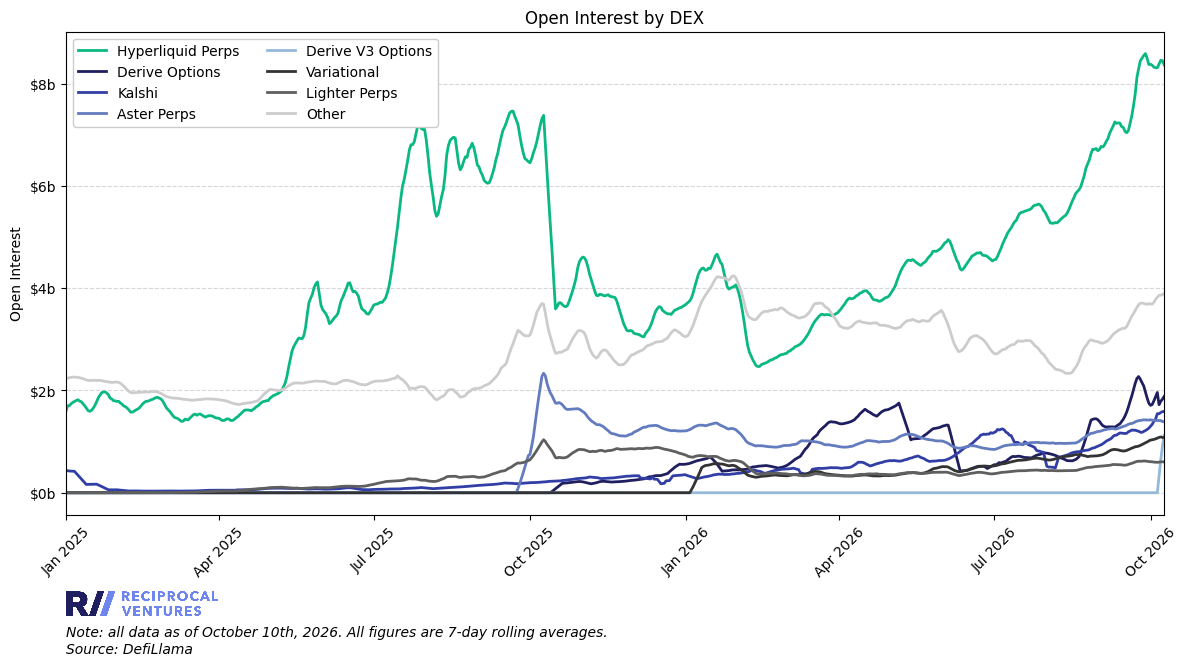

dex       date  Hyperliquid Perps  Derive Options        Kalshi   Aster Perps  \
637 2026-09-30       8.376501e+09    1.752400e+09  1.262682e+09  1.422132e+09   
638 2026-10-01       8.383284e+09    1.709518e+09  1.301919e+09  1.425676e+09   
639 2026-10-02       8.360884e+09    1.726381e+09  1.338219e+09  1.419171e+09   
640 2026-10-03       8.325873e+09    1.798401e+09  1.396432e+09  1.413767e+09   
641 2026-10-04       8.313236e+09    1.877968e+09  1.442095e+09  1.412055e+09   
642 2026-10-05       8.311649e+09    1.960964e+09  1.546592e+09  1.412453e+09   
643 2026-10-06       8.385236e+09    1.722752e+09  1.545510e+09  1.413077e+09   
644 2026-10-07       8.458151e+09    1.787814e+09  1.568550e+09  1.411488e+09   
645 2026-10-08       8.452286e+09    1.829424e+09  1.586203e+09  1.393689e+09   
646 2026-10-09       8.371902e+09    1.882355e+09  1.590012e+09  1.386299e+09   

dex  Derive V3 Options   Variational  Lighter Perps         Other  
637       0.000000e+00  1.014138e+09   6

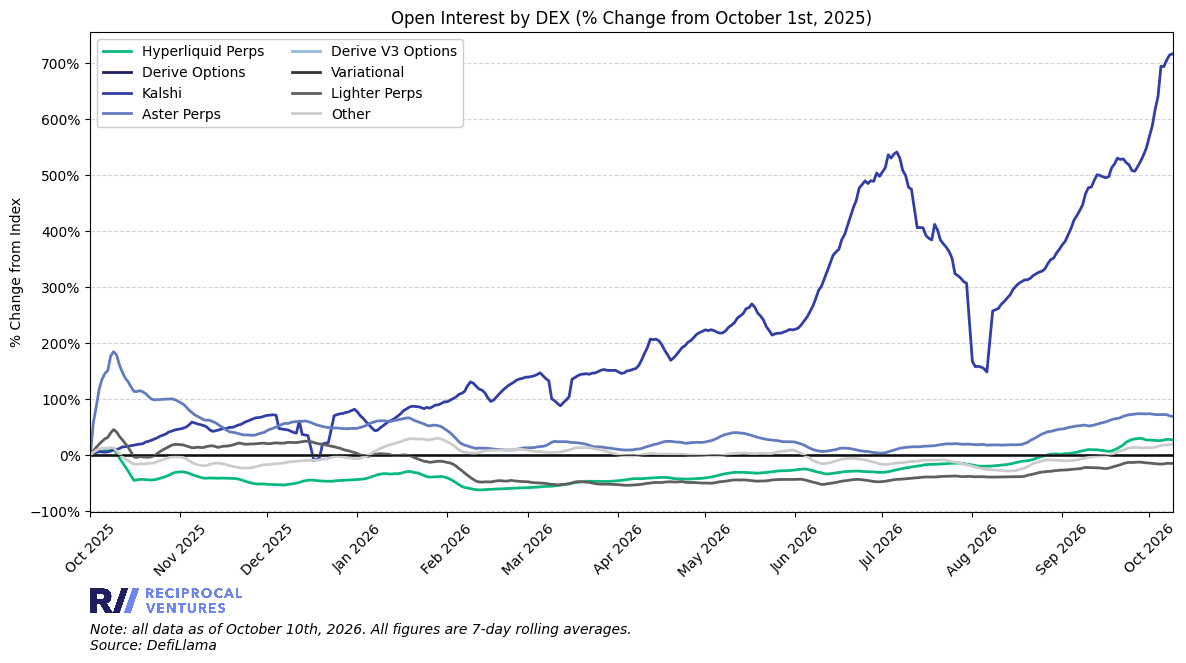

dex       date  Hyperliquid Perps  Derive Options      Kalshi  Aster Perps  \
364 2026-09-30          26.361495               0  548.802771    73.041729   
365 2026-10-01          26.463818               0  568.963828    73.472973   
366 2026-10-02          26.125899               0  587.616125    72.681434   
367 2026-10-03          25.597759               0  617.527706    72.023878   
368 2026-10-04          25.407118               0  640.990741    71.815488   
369 2026-10-05          25.383176               0  694.684046    71.863998   
370 2026-10-06          26.493264               0  694.128257    71.939859   
371 2026-10-07          27.593200               0  705.966611    71.746556   
372 2026-10-08          27.504717               0  715.037394    69.580867   
373 2026-10-09          26.292109               0  716.994616    68.681633   

dex  Derive V3 Options  Variational  Lighter Perps      Other  
364                  0            0     -14.469255  12.719255  
365          

In [74]:
# Test function to plot OI by DEX
start_date = '2025-01-01'
end_date = today
n=7
trailing_window=7 # defaults to 7
percentage = True
chart_type='area' # 'area' or 'line'
pct_change_from_start = False # turns the y-axis into % change but ONLY if chart_type = 'line'

visualization.open_interest_by_dex(start_date, end_date, n, plots_filepath, date, trailing_window, percentage, chart_type, pct_change_from_start)

percentage = False
chart_type = 'line'
visualization.open_interest_by_dex(start_date, end_date, n, plots_filepath, date, trailing_window, percentage, chart_type, pct_change_from_start)

start_date = '2025-10-01'
percentage = False
chart_type = 'line'
pct_change_from_start = True
visualization.open_interest_by_dex(start_date, end_date, n, plots_filepath, date, trailing_window, percentage, chart_type, pct_change_from_start)

In [75]:
# STABLECOINS

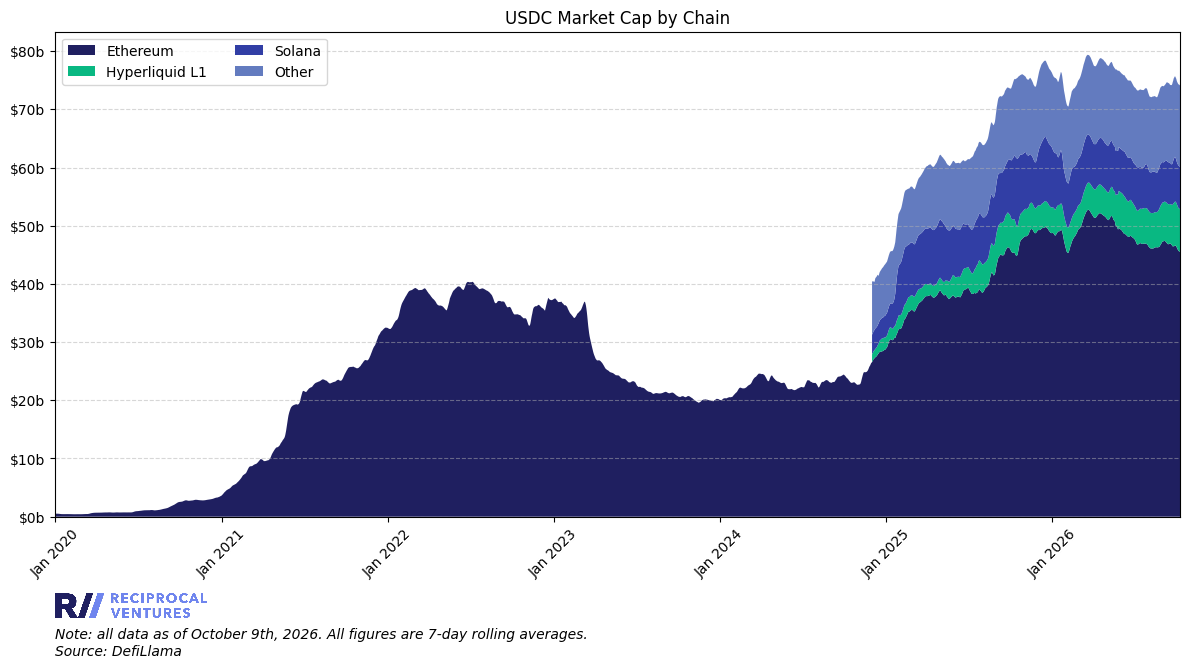

chain       date      Ethereum  Hyperliquid L1        Solana         Other
2946  2026-10-05  4.576475e+10    7.364347e+09  7.276115e+09  1.394712e+10
2947  2026-10-06  4.565454e+10    7.347304e+09  7.316088e+09  1.395872e+10
2948  2026-10-07  4.560445e+10    7.342377e+09  7.317314e+09  1.397348e+10
2949  2026-10-08  4.557089e+10    7.330192e+09  7.298263e+09  1.399737e+10
2950  2026-10-09  4.553333e+10    7.297615e+09  7.241354e+09  1.401136e+10


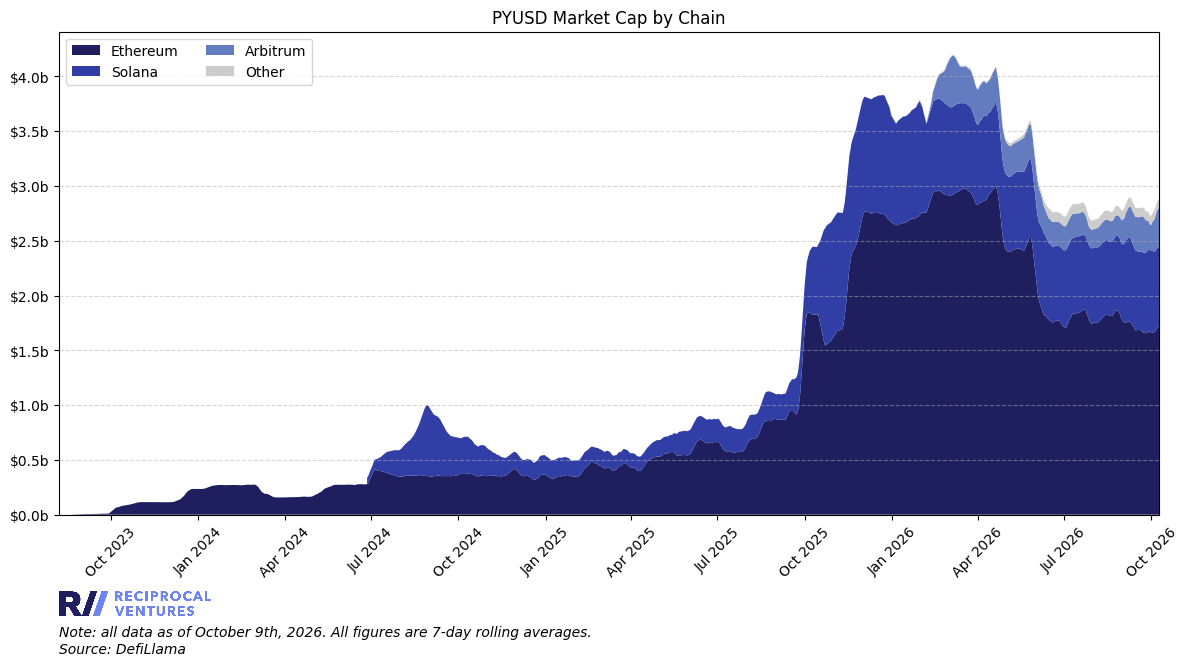

chain       date      Ethereum        Solana      Arbitrum         Other
1154  2026-10-05  1.674157e+09  7.324474e+08  3.107415e+08  8.196770e+07
1155  2026-10-06  1.689437e+09  7.312443e+08  3.275569e+08  8.192666e+07
1156  2026-10-07  1.703627e+09  7.279525e+08  3.421130e+08  8.190105e+07
1157  2026-10-08  1.716443e+09  7.203337e+08  3.561066e+08  8.185492e+07
1158  2026-10-09  1.727487e+09  7.140133e+08  3.558600e+08  8.181756e+07
Done


In [76]:
# Test function to plot stablecoin mcap by chain
assets = ['USDC', 'PYUSD']
start_date = '2020-01-01'
end_date = today
n = 3

visualization.stablecoin_mcap_by_chain(assets, start_date, end_date, n, plots_filepath, date)

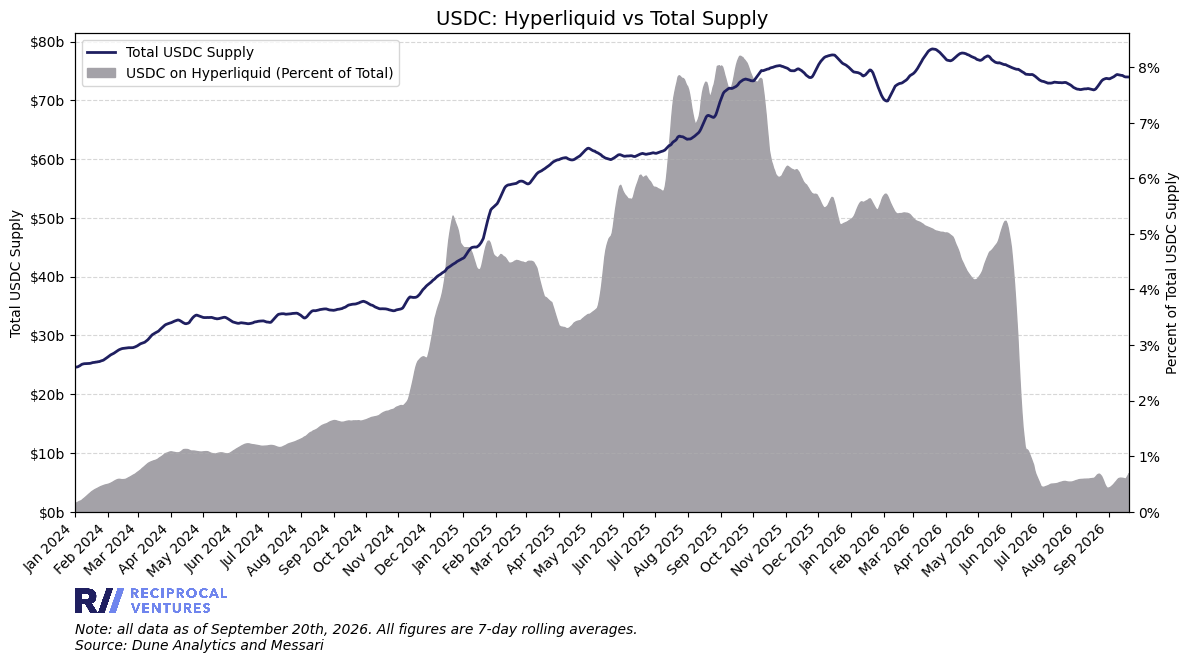

           date  outstandingSupplyUsd   USDC Supply        amount  \
1018 2026-09-16          7.357662e+10  7.402316e+10  1.158223e+07   
1019 2026-09-17          7.378362e+10  7.397904e+10  2.567653e+07   
1020 2026-09-18          7.423085e+10  7.397286e+10  1.146006e+08   
1021 2026-09-19          7.413297e+10  7.396474e+10  4.431717e+06   
1022 2026-09-20          7.419031e+10  7.397114e+10  1.128082e+05   

      cumulative_amount  USDC on Hyperliquid (Percent of Total)  
1018       4.527154e+08                                0.005993  
1019       4.783919e+08                                0.005983  
1020       5.929924e+08                                0.006292  
1021       5.974242e+08                                0.006626  
1022       5.975370e+08                                0.006960  


In [77]:
try:
    # Test hyperliquid as a % of total usdc
    dune_path = 'data/raw/dune/hyperliquid-usdc-supply.json'
    messari_path = 'data/raw/messari/supply/circle-usdc-stablecoin.json'
    start_date = '2024-01-01'

    visualization.hyperliquid_as_percent_of_total_usdc(dune_path, messari_path, start_date, plots_filepath, date)
except:
    print('Error')

In [78]:
# FRED

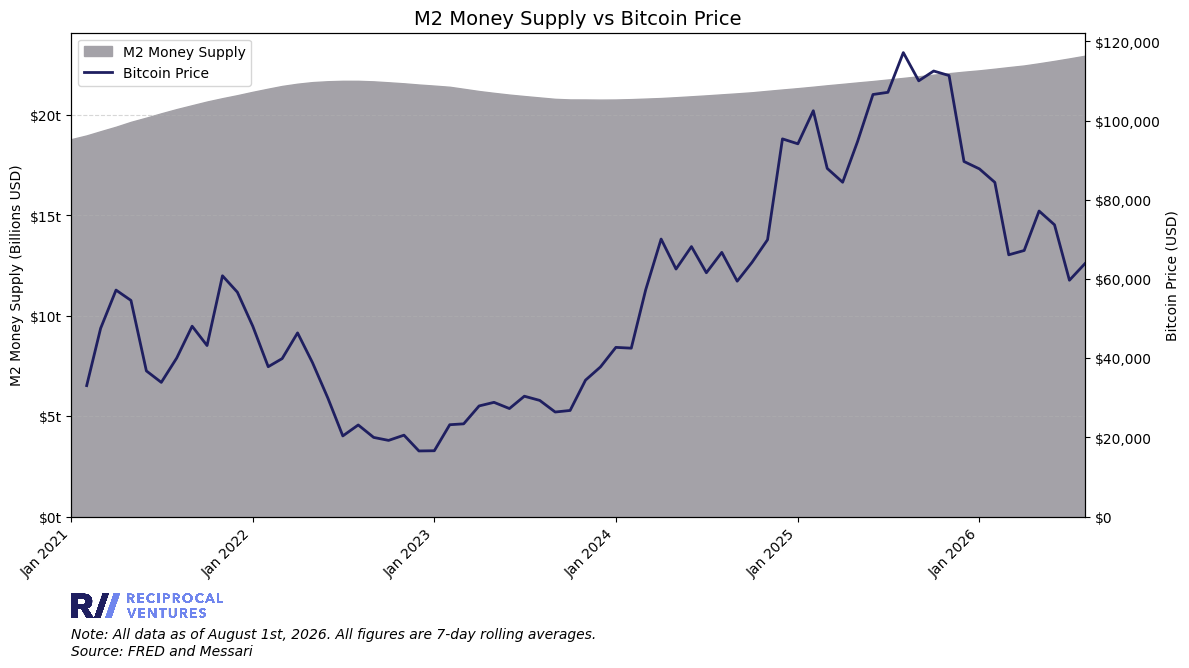

         date       m2         m2-7d         close      close-7d
63 2026-04-01  22756.6  22470.557143  68086.460678  67214.670252
64 2026-05-01  23013.7  22579.685714  78201.916788  77181.666868
65 2026-06-01  23114.9  22698.985714  71332.106402  73701.967519
66 2026-07-01  23217.9  22822.214286  59980.121275  59702.441020
67 2026-08-01  23342.8  22954.985714  62760.284745  63872.205345


In [79]:
# Test function to plot M2 money supply vs an asset price
asset_name = 'Bitcoin'
start_date = '2018-01-01'
m2_filepath = 'data/raw/fred/m2-money-supply-M2SL.json'
asset_filepath = 'data/raw/messari/price/bitcoin.json'

visualization.plot_m2_vs_price(asset_name, start_date, m2_filepath, 
                     asset_filepath, plots_filepath)

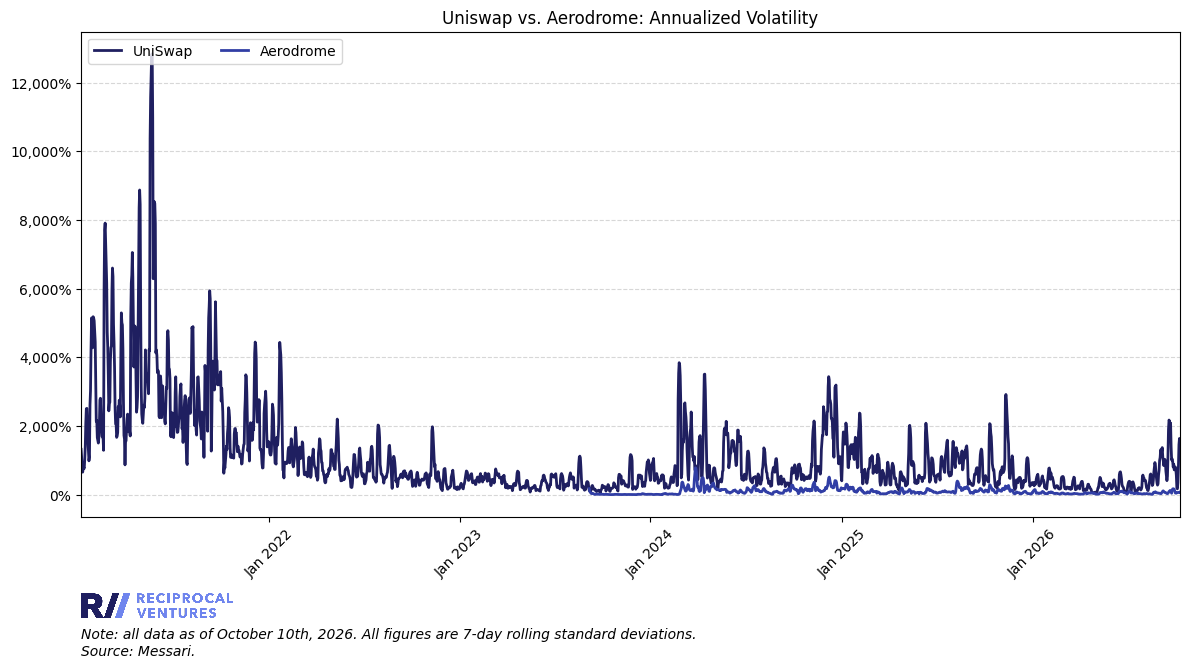

           date  uniswap_annualized_std  aerodrome_annualized_std
2104 2026-10-06                3.522751                  0.624039
2105 2026-10-07                8.223662                  0.660788
2106 2026-10-08               14.558410                  0.606962
2107 2026-10-09               16.370924                  0.581758
2108 2026-10-10               15.693712                  0.740588
Done


In [80]:
# Test plotting annualized volatility of an asset
assets = {'uniswap':'UniSwap',
          'aerodrome':'Aerodrome'}
title = "Uniswap vs. Aerodrome: Annualized Volatility"


visualization.annualized_volatility(assets, plots_filepath, title, date)

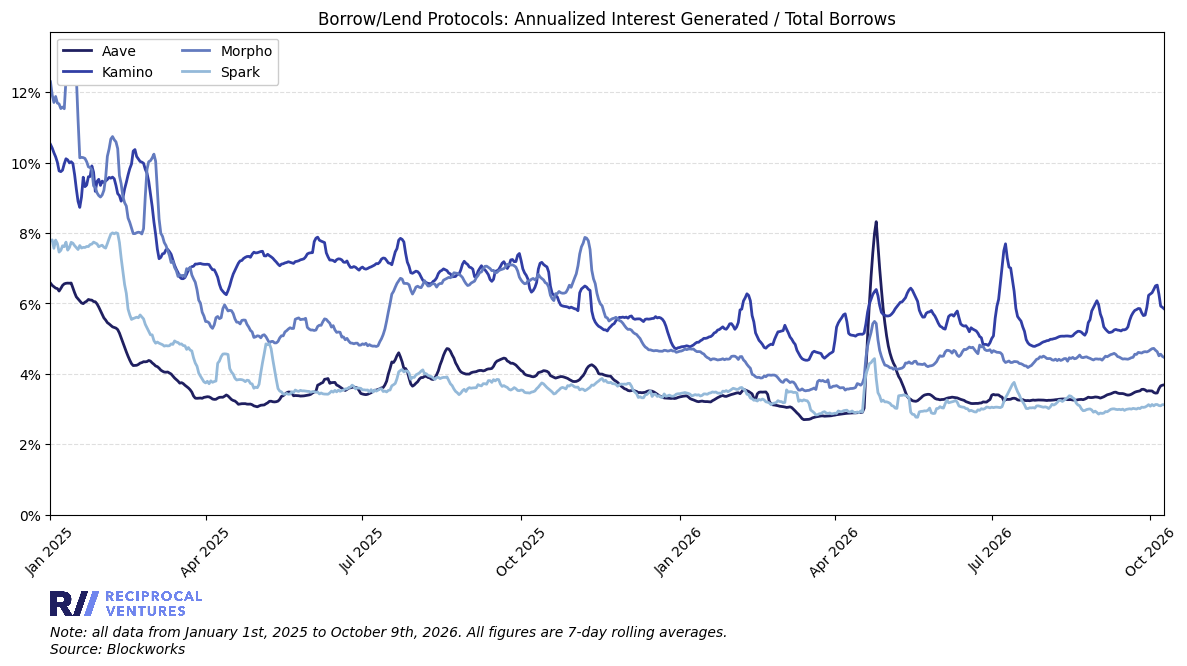

,Aave,Kamino,Morpho,Spark
Median,3.5%,6.2%,5.0%,3.5%
80th Percentile,4.1%,7.2%,6.7%,3.9%
20th Percentile,3.3%,5.2%,4.4%,3.1%
Most Recent,3.7%,5.8%,4.5%,3.1%


Note: All data from January 1st, 2025 to October 9th, 2026. All figures are 7-day rolling averages.
Source: Blockworks.

Table saved to: outputs/tables/borrow-lend-annualized-interest-generated-to-total-borrows-7d-table.png


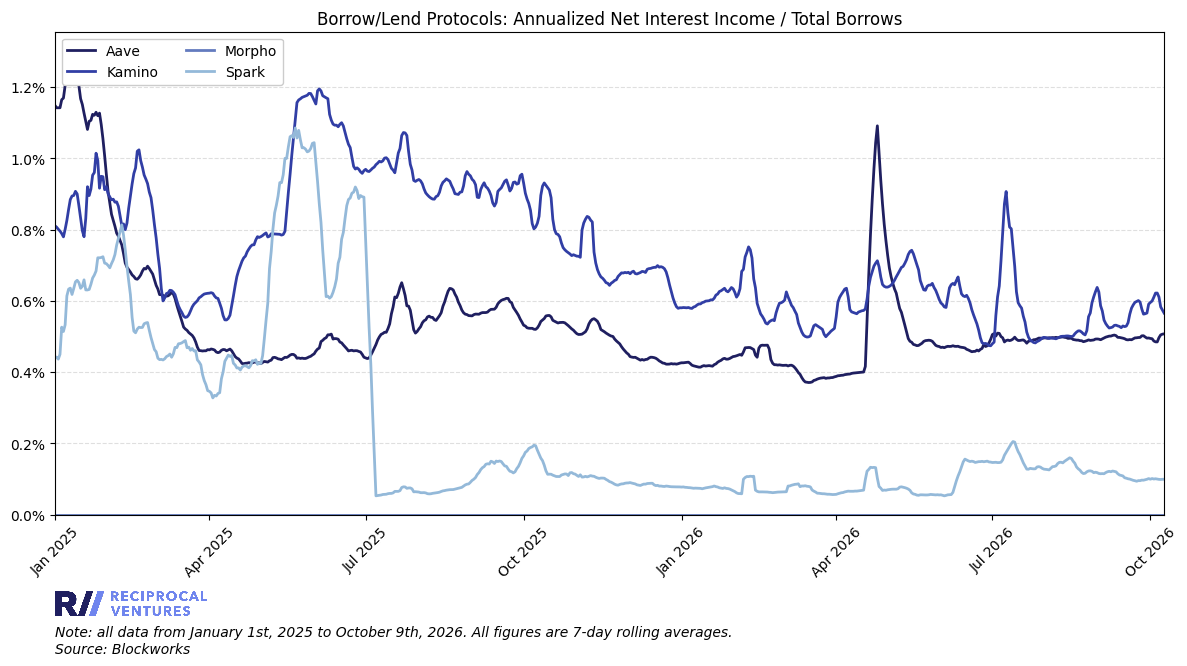

,Aave,Kamino,Morpho,Spark
Median,0.49%,0.68%,0.00%,0.12%
80th Percentile,0.57%,0.92%,0.00%,0.46%
20th Percentile,0.44%,0.57%,0.00%,0.07%
Most Recent,0.51%,0.57%,0.00%,0.10%


Note: All data from January 1st, 2025 to October 9th, 2026. All figures are 7-day rolling averages.
Source: Blockworks.

Table saved to: outputs/tables/borrow-lend-annualized-net-interest-income-to-total-borrows-7d-table.png


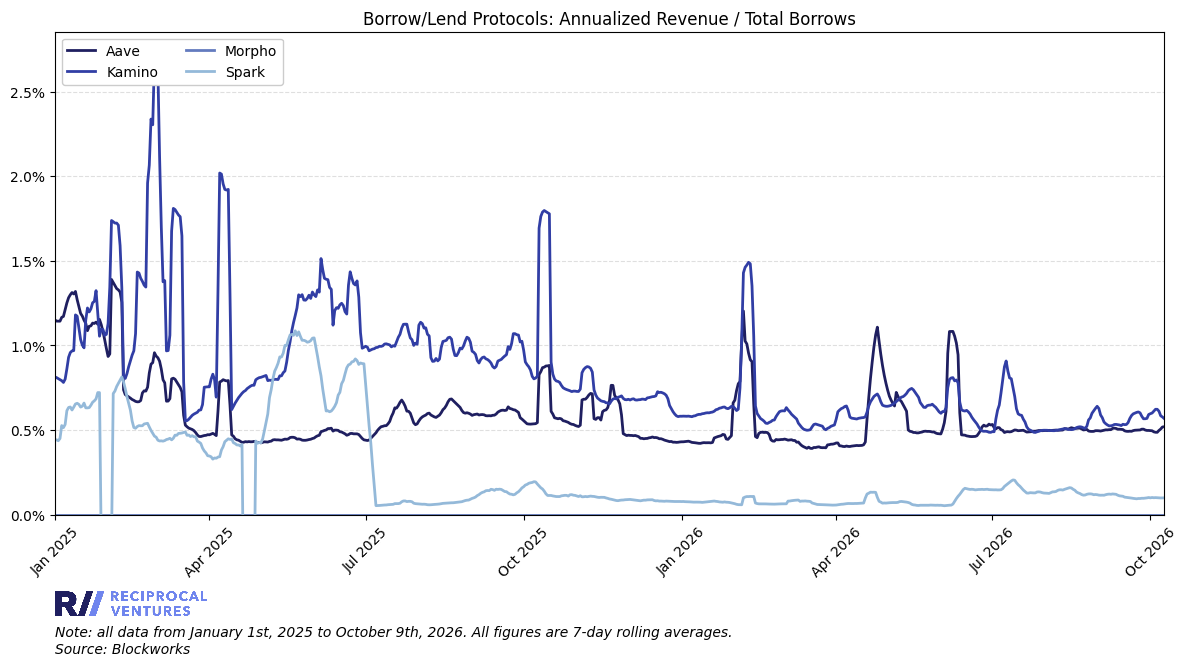

,Aave,Kamino,Morpho,Spark
Median,0.5%,0.7%,0.0%,0.1%
80th Percentile,0.7%,1.1%,0.0%,0.4%
20th Percentile,0.4%,0.6%,0.0%,0.1%
Most Recent,0.5%,0.6%,0.0%,0.1%


Note: All data from January 1st, 2025 to October 9th, 2026. All figures are 7-day rolling averages.
Source: Blockworks.

Table saved to: outputs/tables/borrow-lend-annualized-revenue-to-total-borrows-7d-table.png


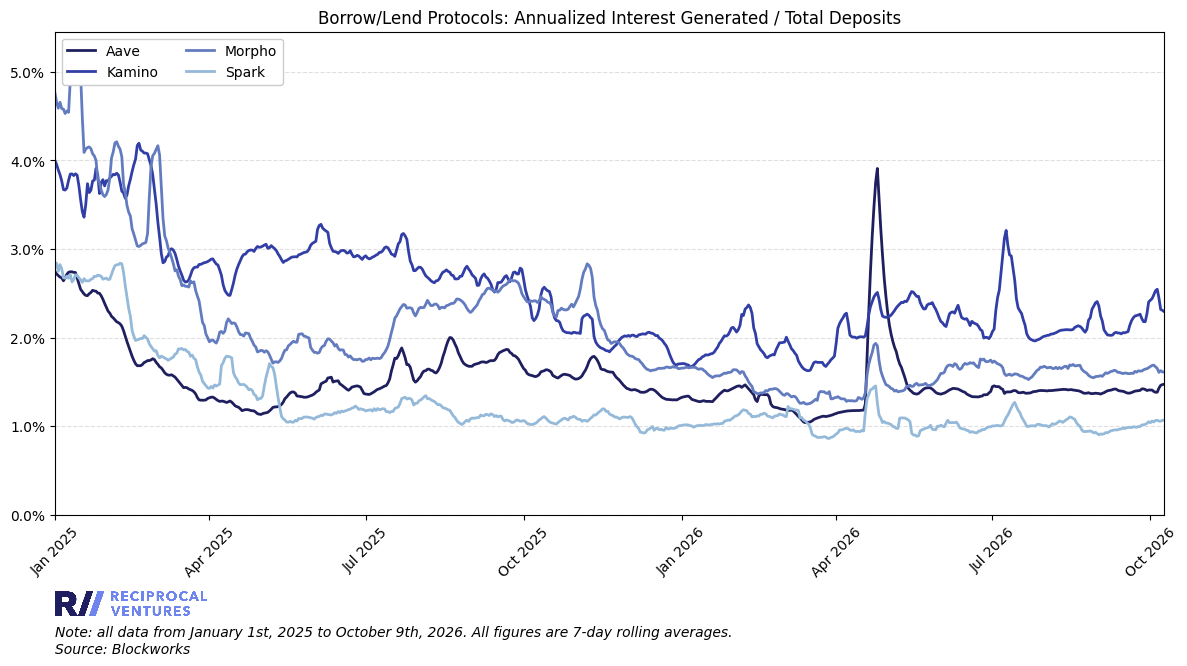

,Aave,Kamino,Morpho,Spark
Median,1.4%,2.4%,1.8%,1.1%
80th Percentile,1.7%,2.9%,2.4%,1.4%
20th Percentile,1.3%,2.0%,1.6%,1.0%
Most Recent,1.5%,2.3%,1.6%,1.1%


Note: All data from January 1st, 2025 to October 9th, 2026. All figures are 7-day rolling averages.
Source: Blockworks.

Table saved to: outputs/tables/borrow-lend-annualized-interest-generated-to-total-deposits-7d-table.png


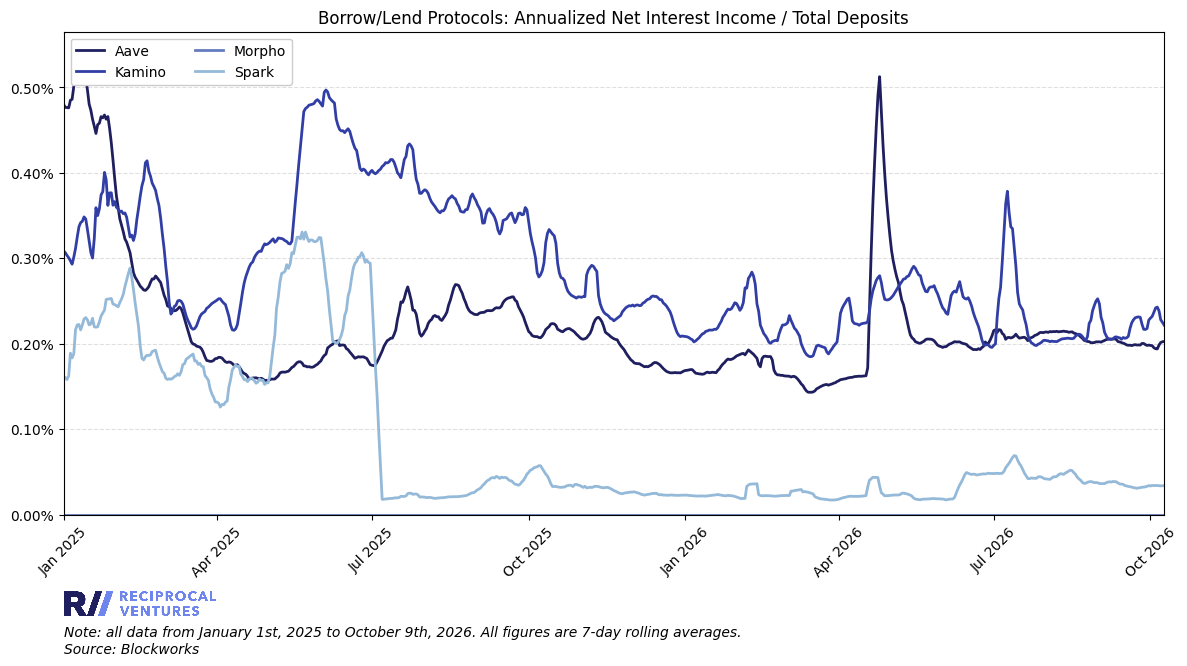

,Aave,Kamino,Morpho,Spark
Median,0.20%,0.26%,0.00%,0.04%
80th Percentile,0.24%,0.36%,0.00%,0.17%
20th Percentile,0.17%,0.22%,0.00%,0.02%
Most Recent,0.20%,0.22%,0.00%,0.03%


Note: All data from January 1st, 2025 to October 9th, 2026. All figures are 7-day rolling averages.
Source: Blockworks.

Table saved to: outputs/tables/borrow-lend-annualized-net-interest-income-to-total-deposits-7d-table.png


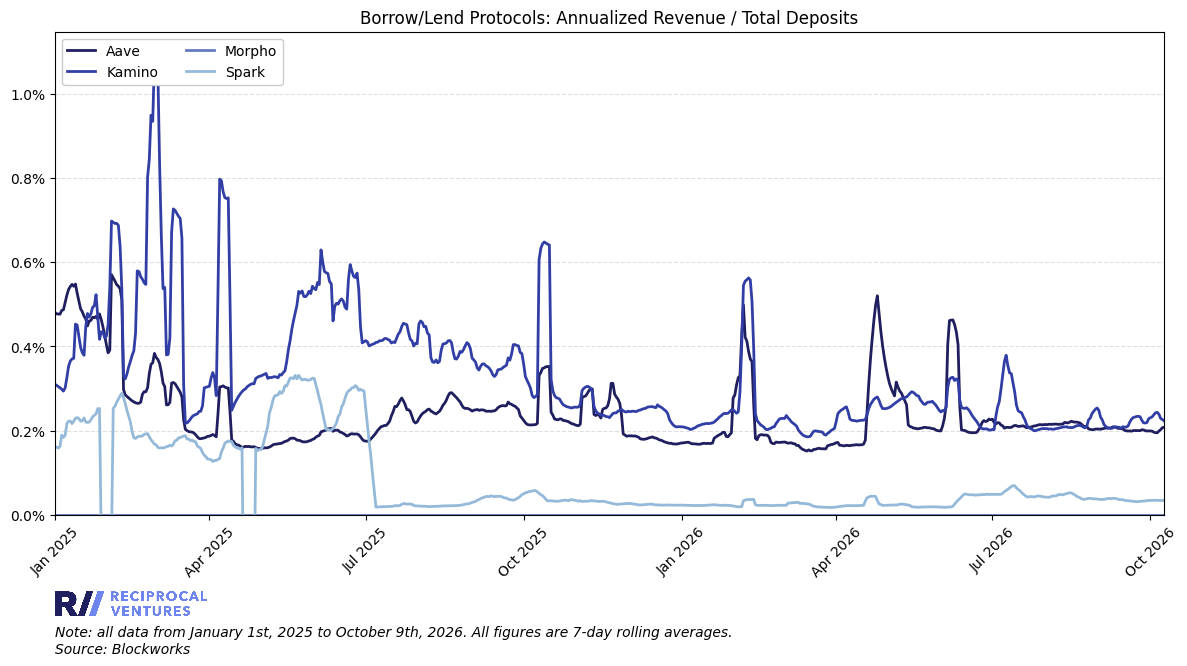

,Aave,Kamino,Morpho,Spark
Median,0.21%,0.28%,0.00%,0.03%
80th Percentile,0.28%,0.42%,0.00%,0.17%
20th Percentile,0.18%,0.22%,0.00%,0.02%
Most Recent,0.21%,0.22%,0.00%,0.03%


Note: All data from January 1st, 2025 to October 9th, 2026. All figures are 7-day rolling averages.
Source: Blockworks.

Table saved to: outputs/tables/borrow-lend-annualized-revenue-to-total-deposits-7d-table.png


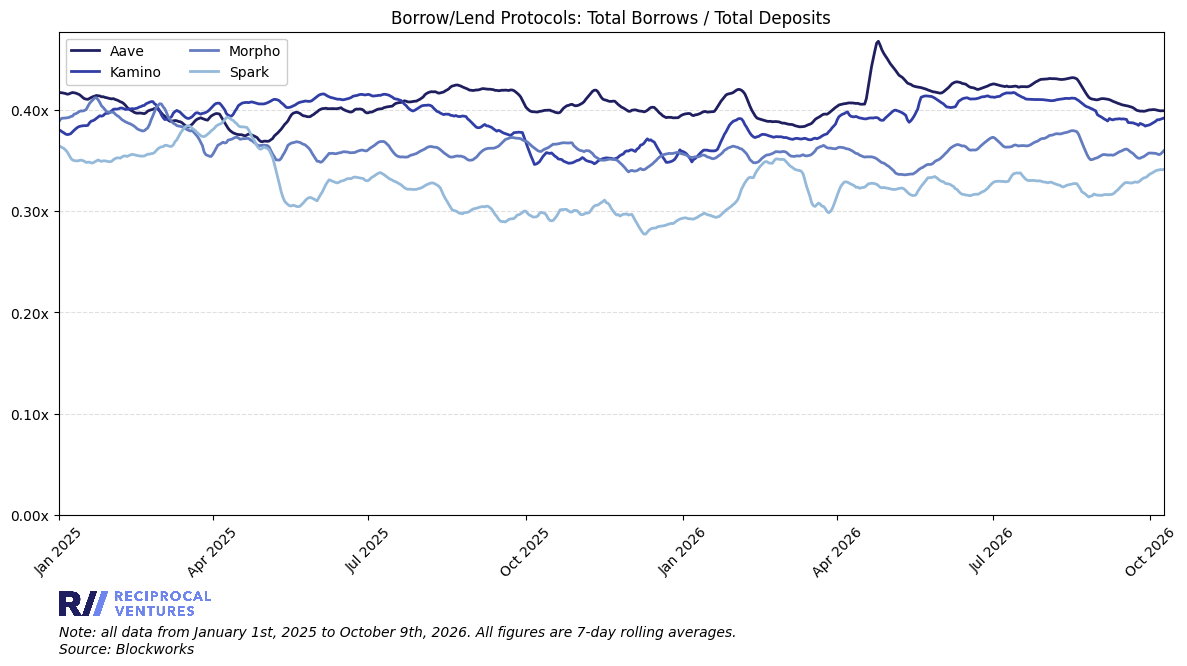

,Aave,Kamino,Morpho,Spark
Median,0.41x,0.39x,0.36x,0.33x
80th Percentile,0.42x,0.41x,0.37x,0.35x
20th Percentile,0.40x,0.37x,0.35x,0.30x
Most Recent,0.40x,0.39x,0.36x,0.34x


Note: All data from January 1st, 2025 to October 9th, 2026. All figures are 7-day rolling averages.
Source: Blockworks.

Table saved to: outputs/tables/borrow-lend-total-borrows-to-total-deposits-7d-table.png
Done


In [81]:
# Test plotting borrow/lend efficiency ratios by protocol

metrics = [
    'interest_generated_to_total_borrows',
    'net_interest_income_to_total_borrows',
    'revenue_to_total_borrows',
    'interest_generated_to_total_deposits',
    'net_interest_income_to_total_deposits',
    'revenue_to_total_deposits',
    'total_borrows_to_total_deposits',
]
start_date = '2025-01-01'
trailing_window = 7
annualize = True  # set True to annualize the flow-based ratios (the utilization ratio is never annualized)

visualization.borrow_lend_ratios_by_protocol(
    metrics,
    start_date,
    plots_filepath,
    tables_filepath,
    date,
    trailing_window=trailing_window,
    annualize=annualize,
)

In [82]:
# VALUATION MULTIPLES

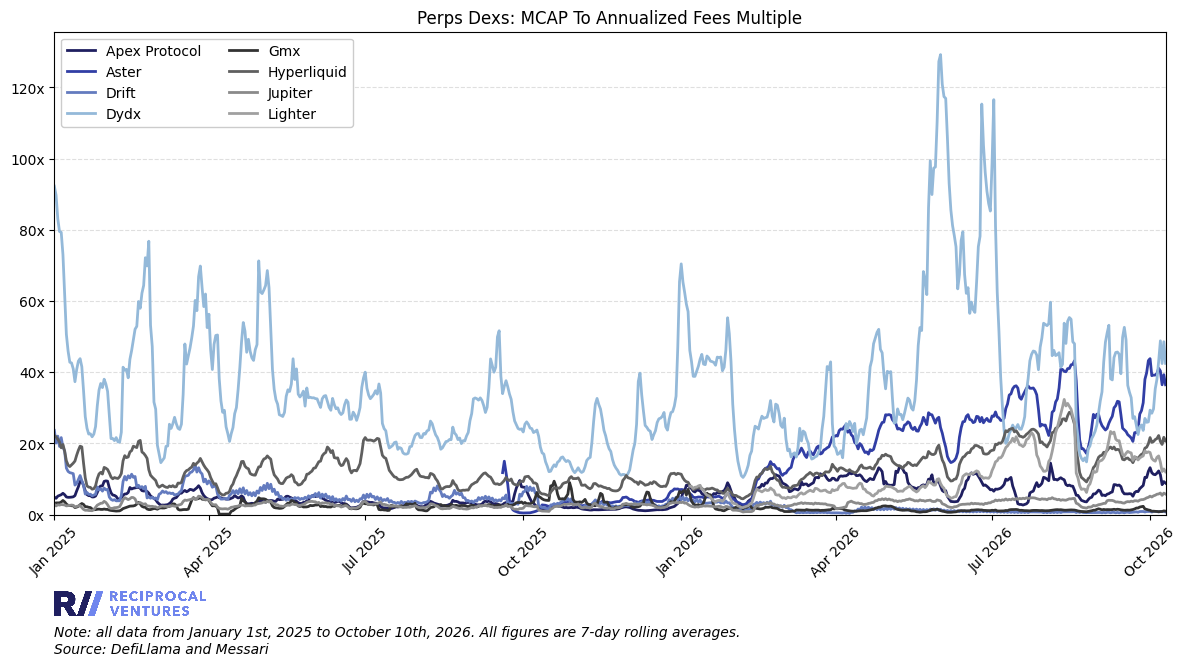

,Apex Protocol,Aster,Drift,Dydx,Gmx,Hyperliquid,Jupiter,Lighter
Median,5x,18x,3x,31x,2x,12x,3x,8x
80th Percentile,8x,27x,6x,47x,3x,17x,4x,16x
20th Percentile,3x,4x,1x,21x,1x,8x,2x,6x
Most Recent,9x,36x,1x,43x,1x,21x,6x,12x


Note: All data from January 1st, 2025 to October 10th, 2026. All figures are 7-day rolling averages.
Source: DefiLlama and Messari.

Table saved to: outputs/tables/perps_dexs-mcap-to-annualized-fees-multiple-7d-table.png


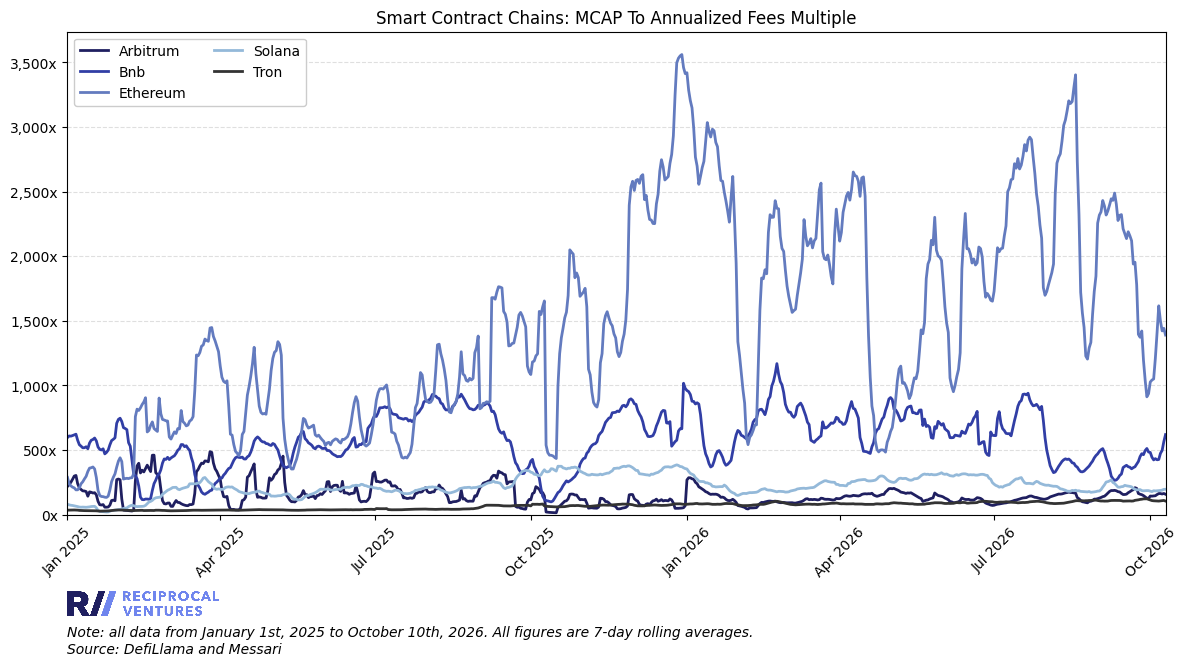

,Arbitrum,Bnb,Ethereum,Solana,Tron
Median,134x,591x,"1,303x",215x,73x
80th Percentile,195x,797x,"2,301x",306x,91x
20th Percentile,93x,412x,653x,175x,37x
Most Recent,158x,620x,"1,390x",197x,105x


Note: All data from January 1st, 2025 to October 10th, 2026. All figures are 7-day rolling averages.
Source: DefiLlama and Messari.

Table saved to: outputs/tables/smart_contract_chains-mcap-to-annualized-fees-multiple-7d-table.png


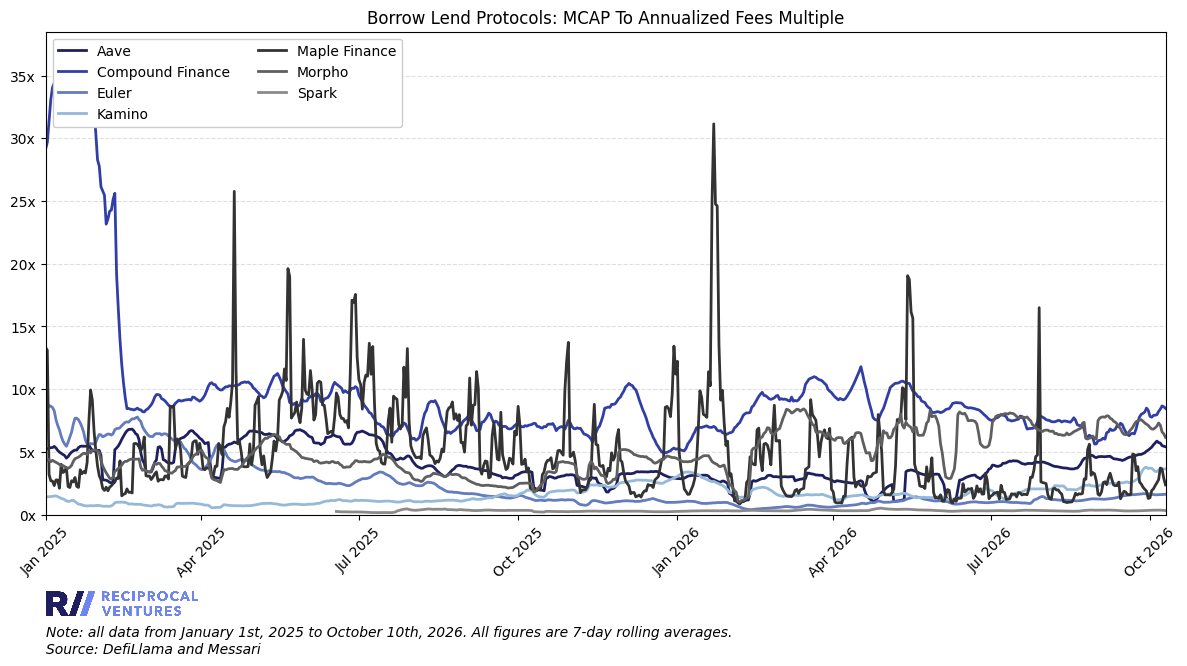

,Aave,Compound Finance,Euler,Kamino,Maple Finance,Morpho,Spark
Median,3.6x,8.4x,1.3x,1.5x,3.8x,4.5x,0.3x
80th Percentile,5.5x,10.0x,3.5x,2.2x,7.5x,6.7x,0.4x
20th Percentile,2.9x,7.0x,1.0x,0.9x,2.0x,3.3x,0.3x
Most Recent,5.4x,8.5x,1.6x,3.6x,2.4x,6.2x,0.3x


Note: All data from January 1st, 2025 to October 10th, 2026. All figures are 7-day rolling averages.
Source: DefiLlama and Messari.

Table saved to: outputs/tables/borrow_lend_protocols-mcap-to-annualized-fees-multiple-7d-table.png
No data for category: launchpads


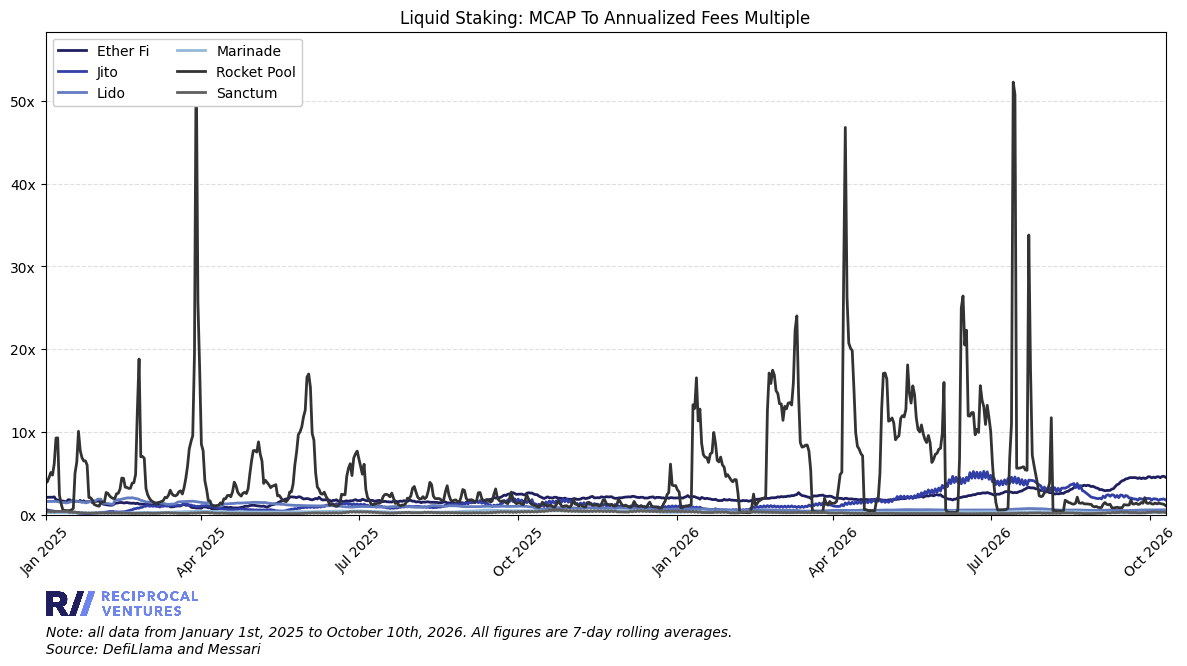

,Ether Fi,Jito,Lido,Marinade,Rocket Pool,Sanctum
Median,1.9x,1.1x,0.8x,0.3x,2.1x,0.2x
80th Percentile,2.4x,2.0x,1.2x,0.4x,7.6x,0.3x
20th Percentile,1.5x,0.8x,0.6x,0.3x,1.2x,0.2x
Most Recent,4.5x,1.8x,0.6x,0.3x,1.1x,0.3x


Note: All data from January 1st, 2025 to October 10th, 2026. All figures are 7-day rolling averages.
Source: DefiLlama and Messari.

Table saved to: outputs/tables/liquid_staking-mcap-to-annualized-fees-multiple-7d-table.png


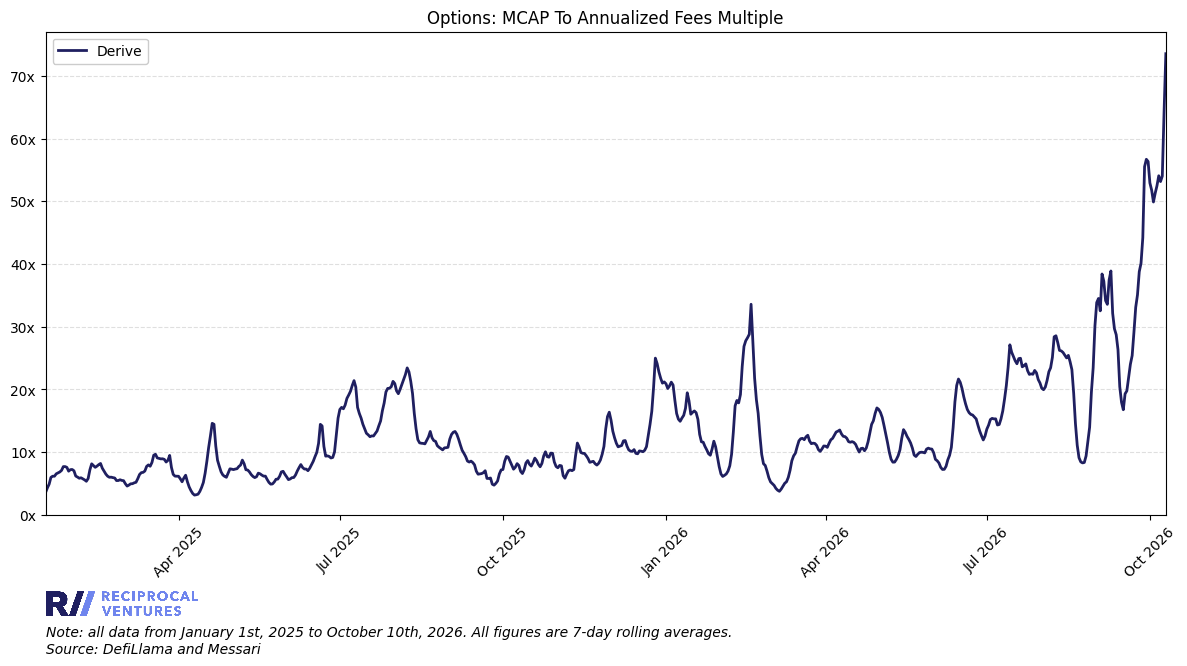

,Derive
Median,11x
80th Percentile,19x
20th Percentile,7x
Most Recent,74x


Note: All data from January 1st, 2025 to October 10th, 2026. All figures are 7-day rolling averages.
Source: DefiLlama and Messari.


c:\Users\JamesEvans\OneDrive - Reciprocal Ventures\Documents\Research\dd-tools\src\visualization\visualization.py:2317: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()



Table saved to: outputs/tables/options-mcap-to-annualized-fees-multiple-7d-table.png


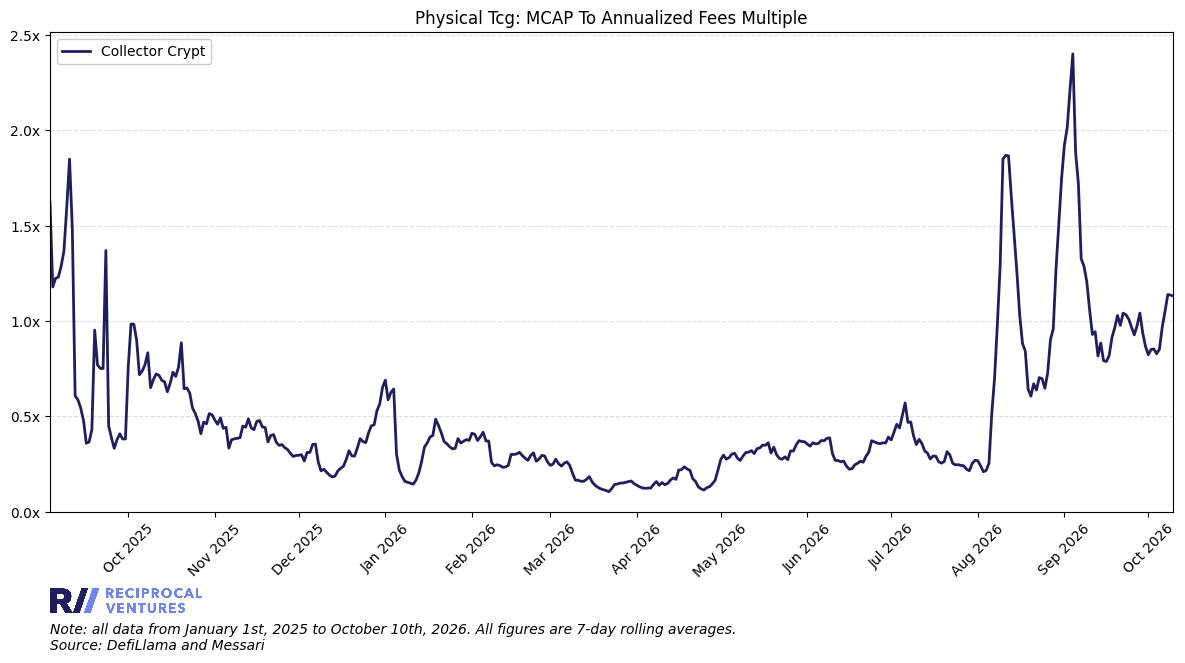

,Collector Crypt
Median,0.36x
80th Percentile,0.73x
20th Percentile,0.24x
Most Recent,1.13x


Note: All data from January 1st, 2025 to October 10th, 2026. All figures are 7-day rolling averages.
Source: DefiLlama and Messari.

Table saved to: outputs/tables/physical_tcg-mcap-to-annualized-fees-multiple-7d-table.png


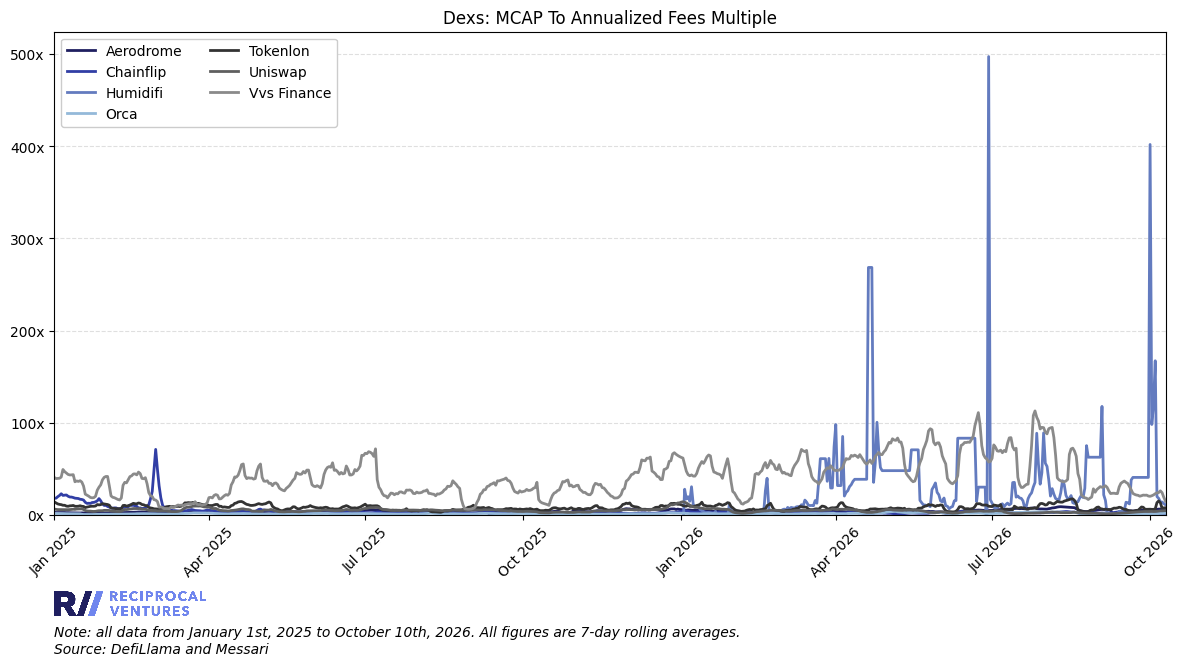

,Aerodrome,Chainflip,Humidifi,Orca,Tokenlon,Uniswap,Vvs Finance
Median,4x,2x,18x,1x,7x,4x,37x
80th Percentile,5x,4x,48x,2x,10x,6x,59x
20th Percentile,3x,2x,5x,1x,5x,3x,22x
Most Recent,6x,1x,11x,2x,7x,4x,15x


Note: All data from January 1st, 2025 to October 10th, 2026. All figures are 7-day rolling averages.
Source: DefiLlama and Messari.

Table saved to: outputs/tables/dexs-mcap-to-annualized-fees-multiple-7d-table.png
Done


In [83]:
# Test plotting valuation multiples by category

metric = 'MCAP-to-annualized-fees-multiple-7d'
start_date = '2025-01-01'
input_filepath = 'data/processed/valuation-multiples/all-protocols-by-category.json'

visualization.protocol_multiples_by_category(metric, start_date, input_filepath, plots_filepath, tables_filepath, date)

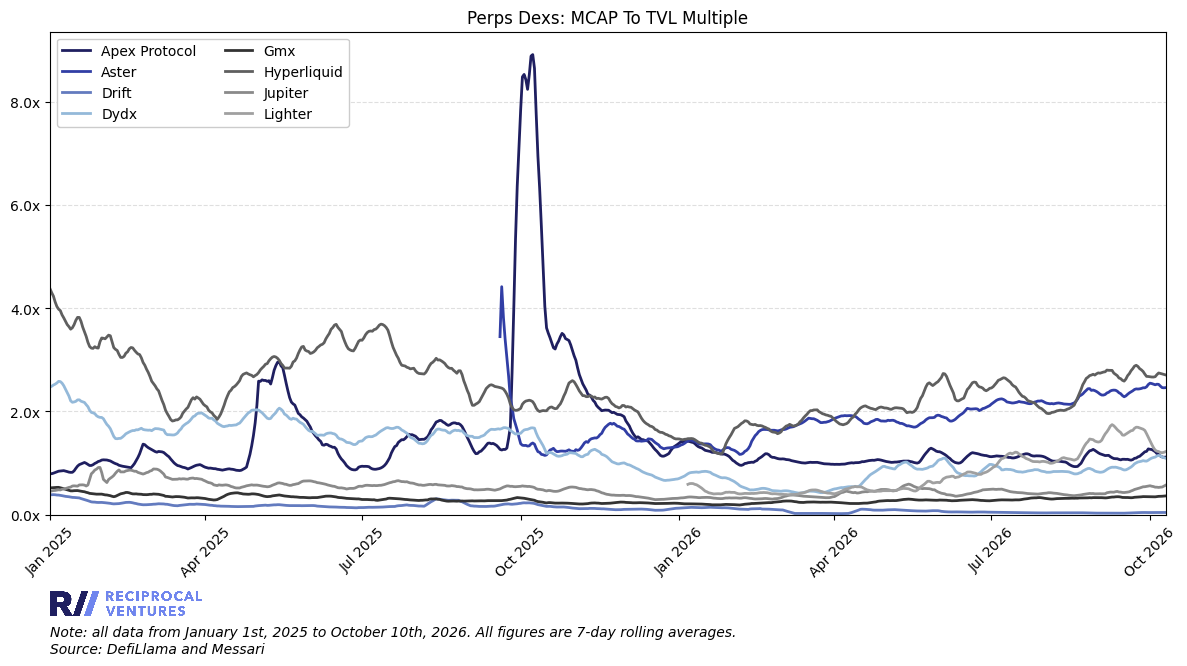

,Apex Protocol,Aster,Drift,Dydx,Gmx,Hyperliquid,Jupiter,Lighter
Median,1.1x,1.8x,0.1x,1.1x,0.3x,2.4x,0.5x,0.6x
80th Percentile,1.6x,2.2x,0.2x,1.7x,0.3x,3.0x,0.6x,1.2x
20th Percentile,1.0x,1.4x,0.0x,0.8x,0.2x,2.0x,0.4x,0.4x
Most Recent,1.1x,2.5x,0.0x,1.1x,0.4x,2.7x,0.6x,1.2x


Note: All data from January 1st, 2025 to October 10th, 2026. All figures are 7-day rolling averages.
Source: DefiLlama and Messari.

Table saved to: outputs/tables/perps_dexs-mcap-to-tvl-multiple-7d-table.png
No data for category: smart_contract_chains


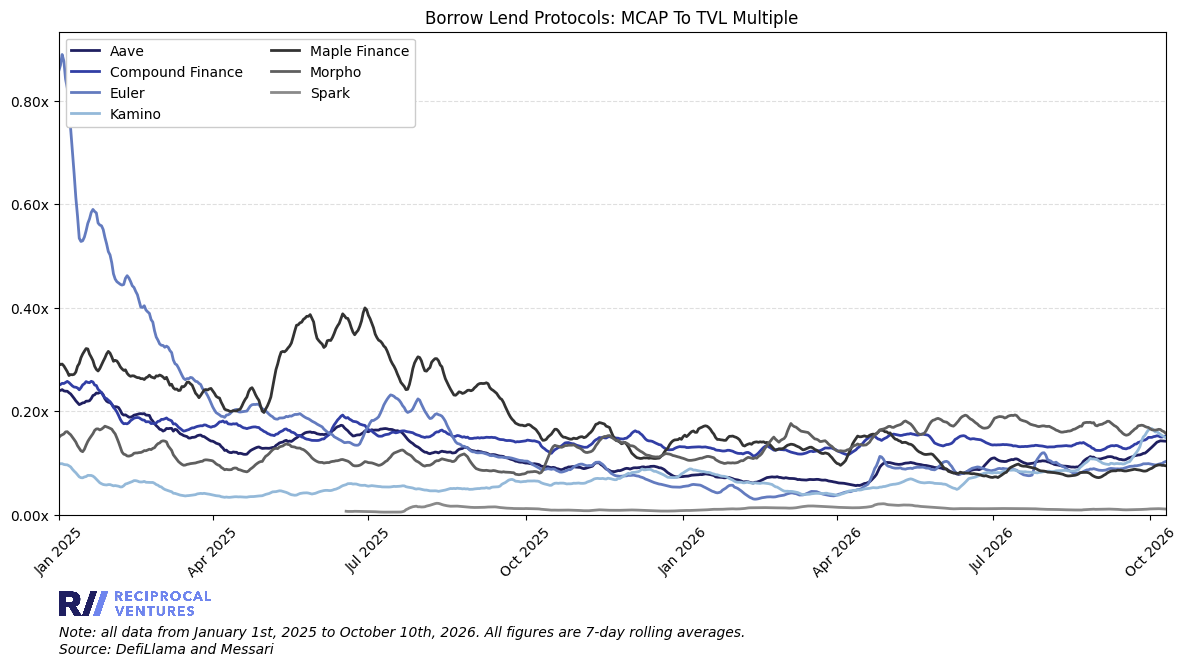

,Aave,Compound Finance,Euler,Kamino,Maple Finance,Morpho,Spark
Median,0.11x,0.15x,0.10x,0.06x,0.16x,0.13x,0.01x
80th Percentile,0.15x,0.17x,0.20x,0.08x,0.27x,0.17x,0.01x
20th Percentile,0.08x,0.13x,0.07x,0.05x,0.10x,0.10x,0.01x
Most Recent,0.14x,0.15x,0.10x,0.15x,0.09x,0.16x,0.01x


Note: All data from January 1st, 2025 to October 10th, 2026. All figures are 7-day rolling averages.
Source: DefiLlama and Messari.

Table saved to: outputs/tables/borrow_lend_protocols-mcap-to-tvl-multiple-7d-table.png
No data for category: launchpads


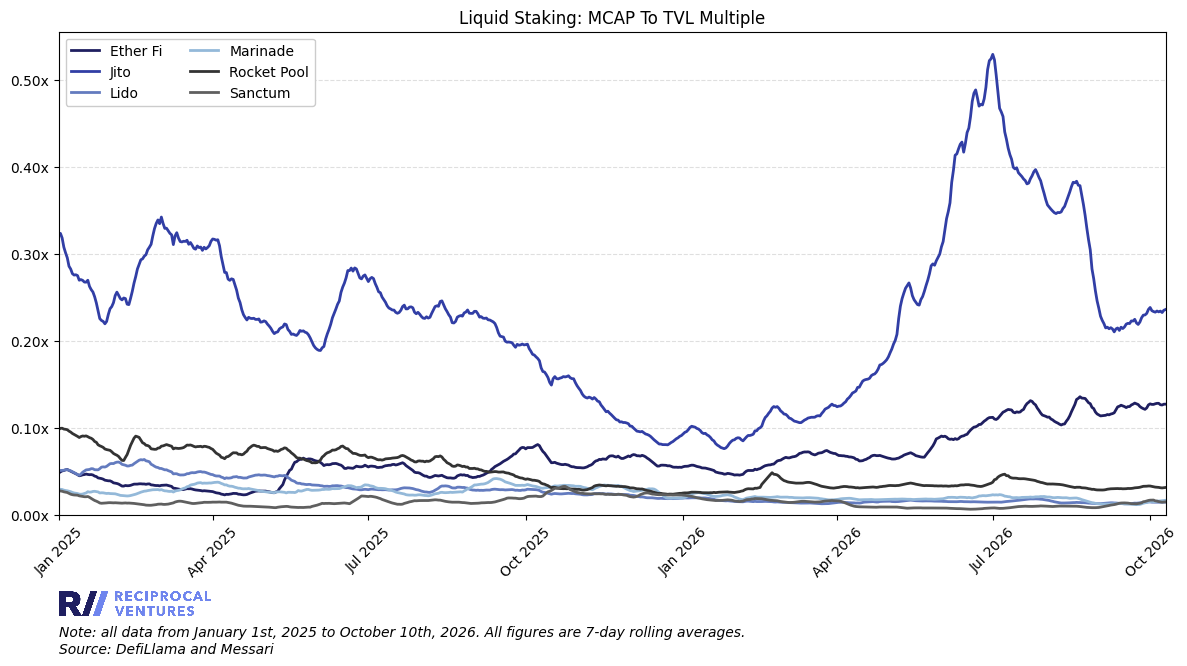

,Ether Fi,Jito,Lido,Marinade,Rocket Pool,Sanctum
Median,0.06x,0.23x,0.02x,0.02x,0.04x,0.01x
80th Percentile,0.09x,0.31x,0.04x,0.03x,0.07x,0.02x
20th Percentile,0.04x,0.12x,0.01x,0.02x,0.03x,0.01x
Most Recent,0.13x,0.24x,0.01x,0.02x,0.03x,0.01x


Note: All data from January 1st, 2025 to October 10th, 2026. All figures are 7-day rolling averages.
Source: DefiLlama and Messari.

Table saved to: outputs/tables/liquid_staking-mcap-to-tvl-multiple-7d-table.png


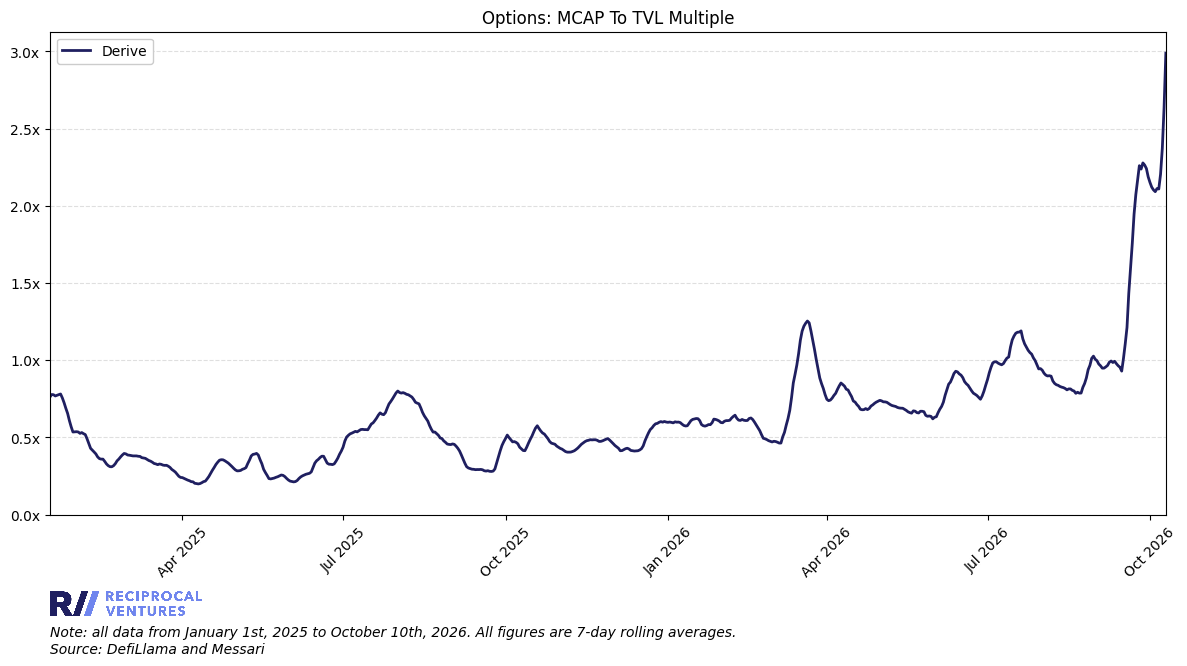

,Derive
Median,0.6x
80th Percentile,0.8x
20th Percentile,0.4x
Most Recent,3.0x


Note: All data from January 1st, 2025 to October 10th, 2026. All figures are 7-day rolling averages.
Source: DefiLlama and Messari.


c:\Users\JamesEvans\OneDrive - Reciprocal Ventures\Documents\Research\dd-tools\src\visualization\visualization.py:2317: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()



Table saved to: outputs/tables/options-mcap-to-tvl-multiple-7d-table.png
No data for category: physical_tcg


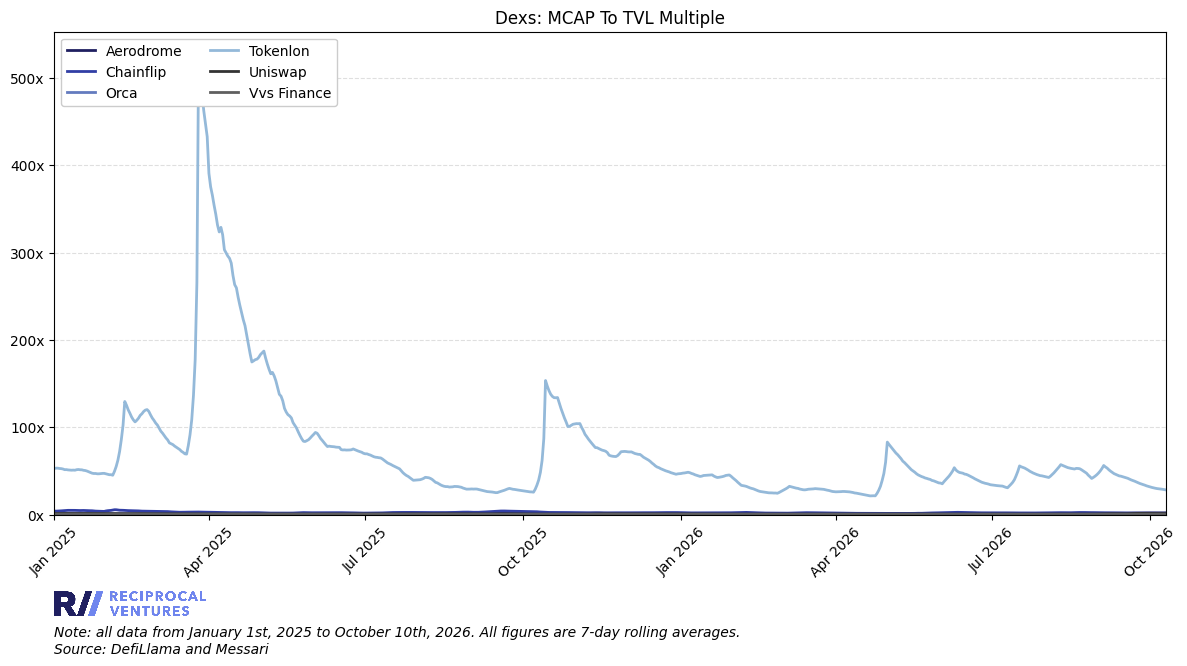

,Aerodrome,Chainflip,Orca,Tokenlon,Uniswap,Vvs Finance
Median,1x,2x,0x,48x,1x,0x
80th Percentile,2x,3x,0x,85x,1x,1x
20th Percentile,1x,2x,0x,32x,1x,0x
Most Recent,2x,2x,0x,28x,1x,0x


Note: All data from January 1st, 2025 to October 10th, 2026. All figures are 7-day rolling averages.
Source: DefiLlama and Messari.

Table saved to: outputs/tables/dexs-mcap-to-tvl-multiple-7d-table.png
Done


In [84]:
# Test plotting valuation multiples by category

metric = 'MCAP-to-TVL-multiple-7d'
start_date = '2025-01-01'
input_filepath = 'data/processed/valuation-multiples/all-protocols-by-category.json'

visualization.protocol_multiples_by_category(metric, start_date, input_filepath, plots_filepath, tables_filepath, date)

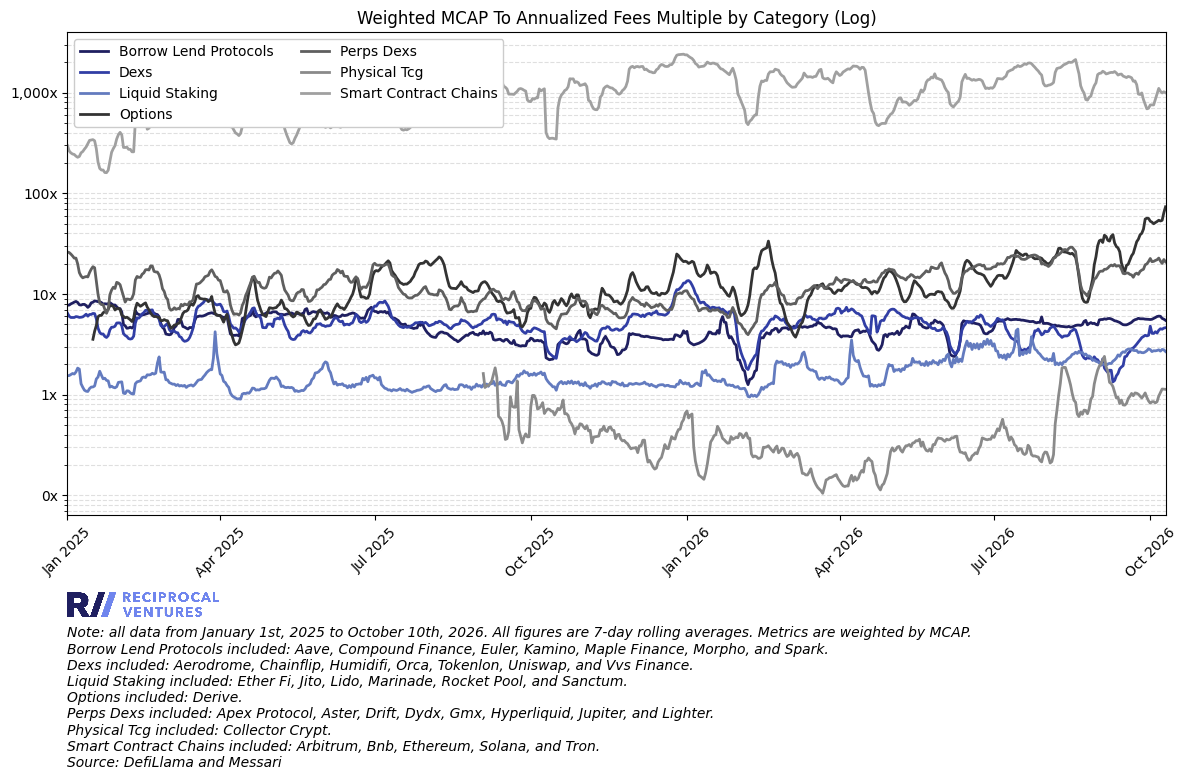

,Borrow Lend Protocols,Dexs,Liquid Staking,Options,Perps Dexs,Physical Tcg,Smart Contract Chains
Median,4.7x,5.0x,1.4x,11x,11x,0.36x,911x
80th Percentile,6.1x,6.3x,2.1x,19x,17x,0.73x,"1,554x"
20th Percentile,3.6x,3.9x,1.2x,7x,8x,0.24x,529x
Most Recent,5.5x,4.6x,2.7x,74x,21x,1.13x,"1,000x"


Note: All data from January 1st, 2025 to October 10th, 2026. All figures are 7-day rolling averages. Metrics are weighted by MCAP.
Borrow Lend Protocols included: Aave, Compound Finance, Euler, Kamino, Maple Finance, Morpho, and Spark.
Dexs included: Aerodrome, Chainflip, Humidifi, Orca, Tokenlon, Uniswap, and Vvs Finance.
Liquid Staking included: Ether Fi, Jito, Lido, Marinade, Rocket Pool, and Sanctum.
Options included: Derive.
Perps Dexs included: Apex Protocol, Aster, Drift, Dydx, Gmx, Hyperliquid, Jupiter, and Lighter.
Physical Tcg included: Collector Crypt.
Smart Contract Chains included: Arbitrum, Bnb, Ethereum, Solana, and Tron.
Source: DefiLlama and Messari.

Table saved to: outputs/tables/weighted-mcap-weighted-mcap-to-annualized-fees-multiple-7d-by-category-table.png
Done


In [85]:
# Test plotting aggregated valuation multiples

metric = 'MCAP-weighted-MCAP-to-annualized-fees-multiple-7d'
log_scale = True
start_date = '2025-01-01'
input_filepath = 'data/processed/valuation-multiples/weighted-multiples-by-category.json' # Don't change, just included as reference to see what metric options are available

visualization.weighted_multiples_by_category(metric, start_date, plots_filepath, tables_filepath, date, input_filepath, log_scale)

No data for category: perps_dexs
No data for category: smart_contract_chains


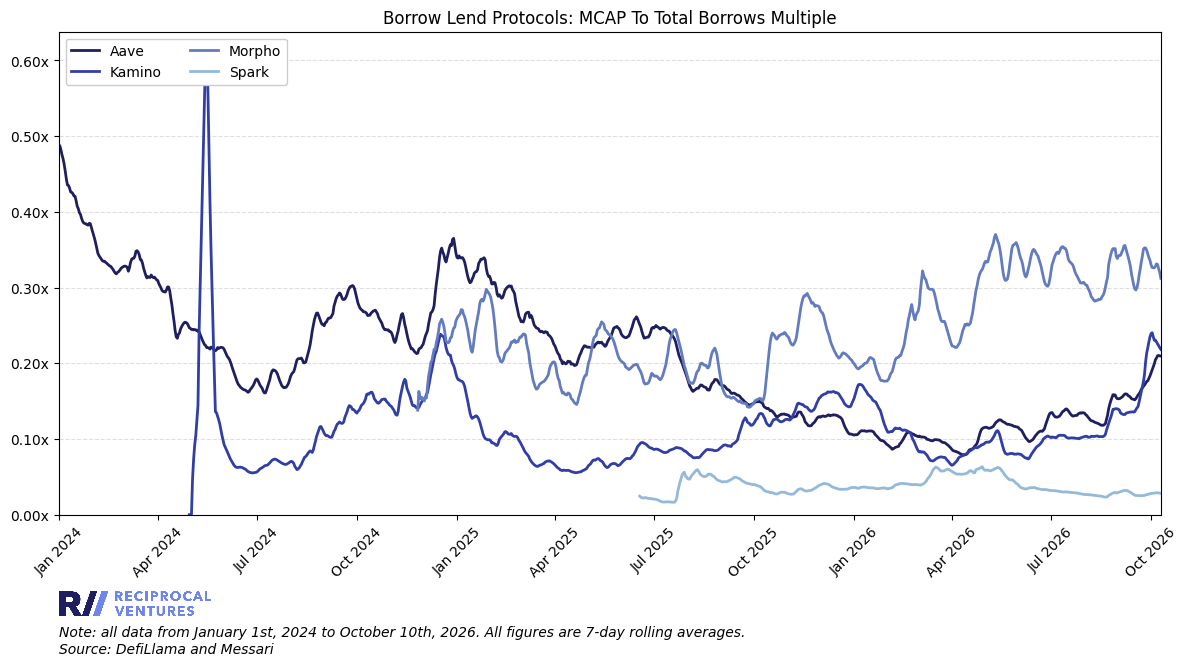

,Aave,Kamino,Morpho,Spark
Median,0.20x,0.10x,0.23x,0.04x
80th Percentile,0.28x,0.14x,0.31x,0.05x
20th Percentile,0.12x,0.07x,0.19x,0.03x
Most Recent,0.21x,0.22x,0.31x,0.03x


Note: All data from January 1st, 2024 to October 10th, 2026. All figures are 7-day rolling averages.
Source: DefiLlama and Messari.

Table saved to: outputs/tables/borrow_lend_protocols-mcap-to-total-borrows-multiple-7d-table.png
No data for category: launchpads
No data for category: liquid_staking
No data for category: options
No data for category: physical_tcg
No data for category: dexs
Done


In [86]:
# Test plotting valuation multiples for borrow/lend

metric = 'MCAP-to-total-borrows-multiple-7d'
start_date = '2024-01-01'
input_filepath = 'data/processed/valuation-multiples/all-protocols-by-category.json'

visualization.protocol_multiples_by_category(metric, start_date, input_filepath, plots_filepath, tables_filepath, date)

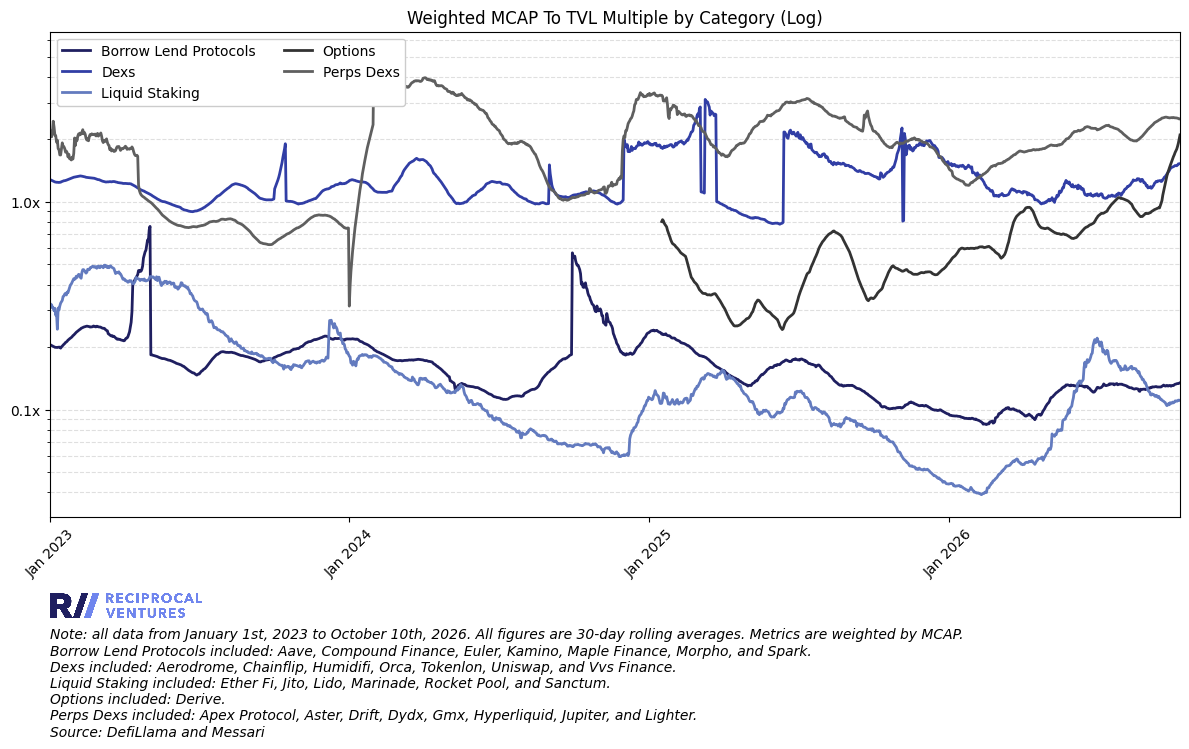

,Borrow Lend Protocols,Dexs,Liquid Staking,Options,Perps Dexs
Median,0.16x,1.19x,0.12x,0.6x,1.9x
80th Percentile,0.21x,1.52x,0.19x,0.8x,2.6x
20th Percentile,0.12x,1.02x,0.07x,0.4x,1.0x
Most Recent,0.13x,1.53x,0.11x,2.1x,2.5x


Note: All data from January 1st, 2023 to October 10th, 2026. All figures are 30-day rolling averages. Metrics are weighted by MCAP.
Borrow Lend Protocols included: Aave, Compound Finance, Euler, Kamino, Maple Finance, Morpho, and Spark.
Dexs included: Aerodrome, Chainflip, Humidifi, Orca, Tokenlon, Uniswap, and Vvs Finance.
Liquid Staking included: Ether Fi, Jito, Lido, Marinade, Rocket Pool, and Sanctum.
Options included: Derive.
Perps Dexs included: Apex Protocol, Aster, Drift, Dydx, Gmx, Hyperliquid, Jupiter, and Lighter.
Source: DefiLlama and Messari.

Table saved to: outputs/tables/weighted-mcap-weighted-mcap-to-tvl-multiple-30d-by-category-table.png
Done


In [87]:
# Test plotting aggregated valuation multiples

metric = 'MCAP-weighted-MCAP-to-TVL-multiple-30d'
input_filepath = 'data/processed/valuation-multiples/weighted-multiples-by-category.json' # Don't change, just included as reference to see what metric options are available
log_scale = True
start_date = '2023-01-01'

visualization.weighted_multiples_by_category(metric, start_date, plots_filepath, tables_filepath, date, input_filepath,  log_scale)

In [88]:
# Test implied valuation for a protocol based on category multiples
protocol_slug = 'lighter'
protocol_name = 'Lighter'
category = 'perps_dexs'
multiple_type='MCAP-weighted-MCAP-to-annualized-fees-multiple-7d'
start_date='2025-01-01'
protocol_trailing_window=7

result = visualization.implied_valuation_from_category_multiples(
    protocol_slug,
    protocol_name,
    category,
    multiple_type,
    start_date,
    protocol_trailing_window
)

Lighter Implied Valuation from Perps Dexs Multiples

Protocol: Lighter
Latest Annualized Fees (7d avg): $72m
Latest MCAP (7d avg): $933m
Current Price: $3.73
Latest MCAP/Annualized Fees Multiple (7d avg): 12x
As of: October 9th, 2026

Category: Perps Dexs
Multiple: MCAP Weighted MCAP To Annualized Fees Multiple 7D
--------------------------------------------------------------------------------
Statistic            Perps Dexs Multiple   Implied MCAP  Implied Price
--------------------------------------------------------------------------------
Median                               11x          $826m          $3.30
80th Percentile                      17x          $1.3b          $4.99
20th Percentile                       8x          $555m          $2.21
Most Recent                          21x          $1.5b          $6.10
--------------------------------------------------------------------------------

Protocol: Lighter
Multiple: MCAP/Annualized Fees (7d avg)
---------------------------

In [89]:
# Test implied valuation for a protocol based on category multiples
protocol_slug = 'aave'
protocol_name = 'Aave'
category = 'borrow_lend_protocols'
multiple_type='FDV-weighted-FDV-to-annualized-fees-multiple-30d'
start_date='2024-01-01'
protocol_trailing_window=7

result = visualization.implied_valuation_from_category_multiples(
    protocol_slug,
    protocol_name,
    category,
    multiple_type,
    start_date,
    protocol_trailing_window
)

Aave Implied Valuation from Borrow Lend Protocols Multiples

Protocol: Aave
Latest Annualized Fees (7d avg): $498m
Latest FDV (30d avg): $2.8b
Current Price: $172.44
Latest FDV/Annualized Fees Multiple (30d avg): 5.3x
As of: October 9th, 2026

Category: Borrow Lend Protocols
Multiple: FDV Weighted FDV To Annualized Fees Multiple 30D
--------------------------------------------------------------------------------
Statistic            Borrow Lend Protocols Multiple    Implied FDV  Implied Price
--------------------------------------------------------------------------------
Median                                        11.4x          $5.7b        $355.53
80th Percentile                               17.4x          $8.7b        $541.10
20th Percentile                                7.0x          $3.5b        $218.47
Most Recent                                    8.0x          $4.0b        $247.10
--------------------------------------------------------------------------------

Protocol: A

In [90]:
# Test implied valuation for a protocol based on category multiples
protocol_slug = 'kamino'
protocol_name = 'Kamino'
category = 'borrow_lend_protocols'
multiple_type='FDV-weighted-FDV-to-annualized-fees-multiple-7d'
start_date='2024-01-01'
protocol_trailing_window=7

result = visualization.implied_valuation_from_category_multiples(
    protocol_slug,
    protocol_name,
    category,
    multiple_type,
    start_date,
    protocol_trailing_window
)

Kamino Implied Valuation from Borrow Lend Protocols Multiples

Protocol: Kamino
Latest Annualized Fees (7d avg): $60m
Latest FDV (7d avg): $354m
Current Price: $0.0354
Latest FDV/Annualized Fees Multiple (7d avg): 6.4x
As of: October 9th, 2026

Category: Borrow Lend Protocols
Multiple: FDV Weighted FDV To Annualized Fees Multiple 7D
--------------------------------------------------------------------------------
Statistic            Borrow Lend Protocols Multiple    Implied FDV  Implied Price
--------------------------------------------------------------------------------
Median                                         7.9x          $476m        $0.0476
80th Percentile                               10.9x          $657m        $0.0657
20th Percentile                                5.6x          $338m        $0.0338
Most Recent                                    6.7x          $401m        $0.0401
--------------------------------------------------------------------------------

Protocol: K

In [91]:
# Derive implied valuation from perps DEX multiples (Derive is filed under 'options' in the index;
# the function finds it there and compares it against the category named here)
protocol_slug = 'derive'
protocol_name = 'Derive'
category = 'perps_dexs'
multiple_type='MCAP-weighted-MCAP-to-annualized-fees-multiple-7d'
start_date='2025-02-01'  # DRV first priced 2025-01-15
protocol_trailing_window=7

result = visualization.implied_valuation_from_category_multiples(
    protocol_slug,
    protocol_name,
    category,
    multiple_type,
    start_date,
    protocol_trailing_window
)

Derive Implied Valuation from Perps Dexs Multiples

Protocol: Derive
Latest Annualized Fees (7d avg): $7m
Latest MCAP (7d avg): $553m
Current Price: $0.552
Latest MCAP/Annualized Fees Multiple (7d avg): 74x
As of: October 9th, 2026

Category: Perps Dexs
Multiple: MCAP Weighted MCAP To Annualized Fees Multiple 7D
--------------------------------------------------------------------------------
Statistic            Perps Dexs Multiple   Implied MCAP  Implied Price
--------------------------------------------------------------------------------
Median                               11x           $82m        $0.0815
80th Percentile                      17x          $124m         $0.124
20th Percentile                       8x           $55m        $0.0551
Most Recent                          21x          $151m         $0.151
--------------------------------------------------------------------------------

Protocol: Derive
Multiple: MCAP/Annualized Fees (7d avg)
------------------------------

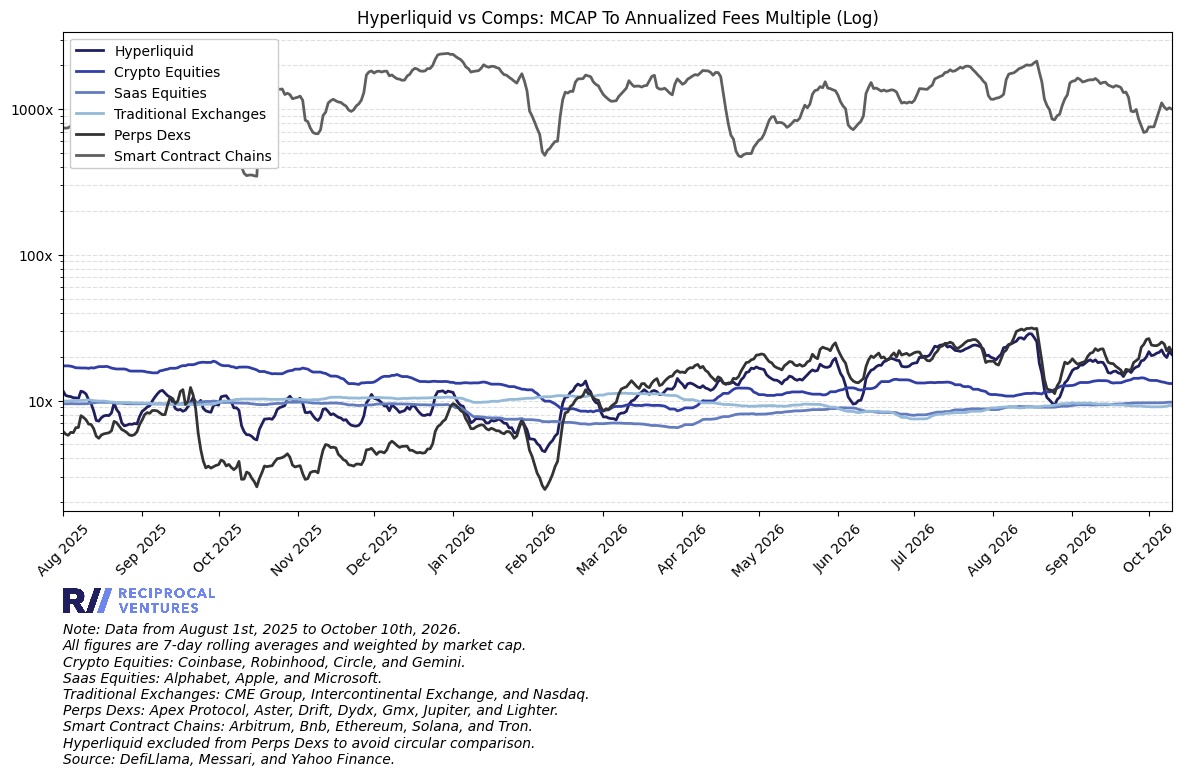

,Hyperliquid,Crypto Equities,Saas Equities,Traditional Exchanges,Perps Dexs,Smart Contract Chains
Median,11.1x,13.2x,9.0x,9.6x,11.8x,"1,264x"
80th Percentile,17.2x,15.7x,9.5x,10.4x,19.8x,"1,709x"
20th Percentile,7.9x,11.0x,7.6x,9.1x,4.6x,853x
Most Recent,21x,13.1x,9.7x,9.2x,22x,"1,000x"


Note: Data from August 1st, 2025 to October 10th, 2026. 
All figures are 7-day rolling averages and weighted by market cap.
Crypto Equities: Coinbase, Robinhood, Circle, and Gemini.
Saas Equities: Alphabet, Apple, and Microsoft.
Traditional Exchanges: CME Group, Intercontinental Exchange, and Nasdaq.
Perps Dexs: Apex Protocol, Aster, Drift, Dydx, Gmx, Jupiter, and Lighter.
Smart Contract Chains: Arbitrum, Bnb, Ethereum, Solana, and Tron.
Hyperliquid excluded from Perps Dexs to avoid circular comparison.
Source: DefiLlama, Messari, and Yahoo Finance.

Table saved to: outputs/tables/hyperliquid-vs-comps-mcap-to-annualized-fees-multiple-7d-table.png


In [104]:
# Test comparing asset multiples vs equity comps and liquid comps

breakout_assets = 'hyperliquid'  # Can also be a list: ['hyperliquid', 'dydx']
liquid_comp_categories = ['perps_dexs', 'smart_contract_chains']  # Auto-formatted to "Perps Dexs", "Smart Contract Chains"
equity_comps = ['crypto_equities', 'saas_equities', 'traditional_exchanges']  # Display names auto-fetched from index, can be either single names or categories
multiple_type = 'MCAP-to-annualized-fees-multiple-7d'
start_date = '2025-08-01'
log_scale = True  # Set to True for log scale y-axis

result = visualization.asset_vs_comps_multiples(
    breakout_assets=breakout_assets,
    liquid_comp_categories=liquid_comp_categories,
    equity_comps=equity_comps,
    multiple_type=multiple_type,
    start_date=start_date,
    plots_filepath=plots_filepath,
    tables_filepath=tables_filepath,
    date=date,
    log_scale=log_scale
)

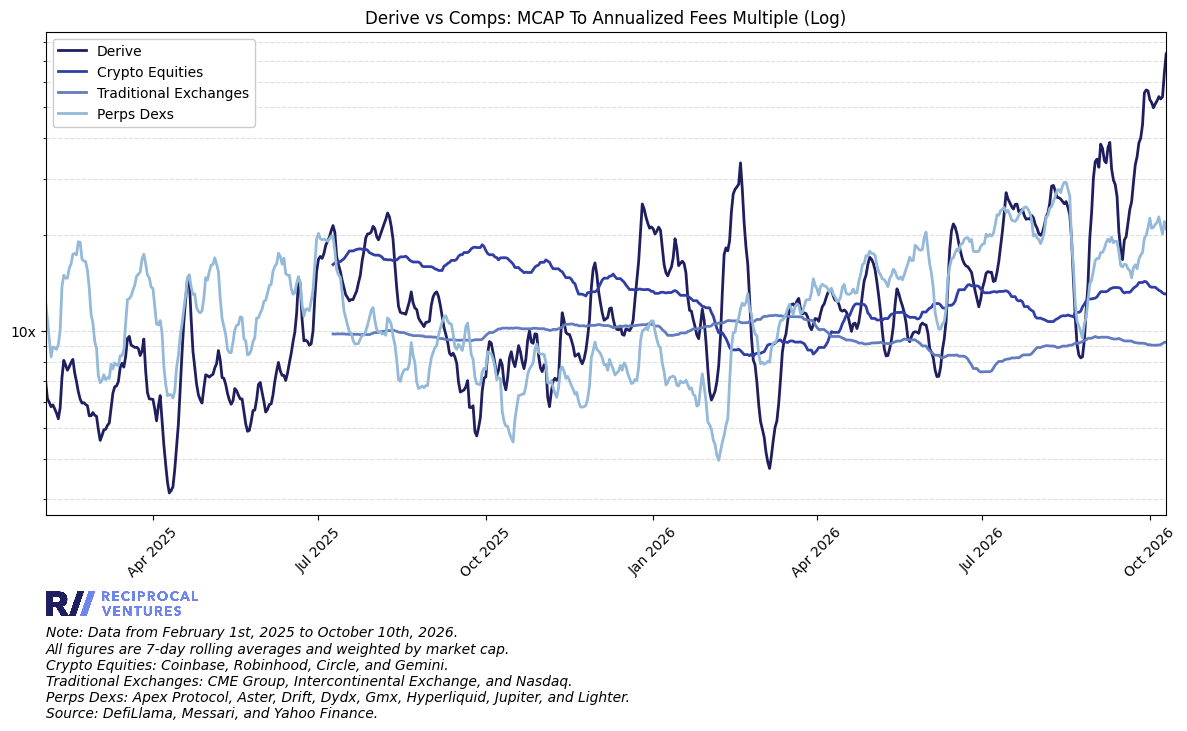

,Derive,Crypto Equities,Traditional Exchanges,Perps Dexs
Median,10.7x,13.2x,9.7x,11.3x
80th Percentile,19.3x,16.1x,10.4x,17.1x
20th Percentile,7.0x,11.0x,9.1x,7.6x
Most Recent,74x,13.1x,9.2x,21x


Note: Data from February 1st, 2025 to October 10th, 2026. 
All figures are 7-day rolling averages and weighted by market cap.
Crypto Equities: Coinbase, Robinhood, Circle, and Gemini.
Traditional Exchanges: CME Group, Intercontinental Exchange, and Nasdaq.
Perps Dexs: Apex Protocol, Aster, Drift, Dydx, Gmx, Hyperliquid, Jupiter, and Lighter.
Source: DefiLlama, Messari, and Yahoo Finance.

Table saved to: outputs/tables/derive-vs-comps-mcap-to-annualized-fees-multiple-7d-table.png


In [93]:
# Derive vs perps DEX comps and equity comps. 'options' is left out of liquid_comp_categories
# until a second options protocol with Messari market-cap data is in the index (Derive is the only one).

breakout_assets = 'derive'
liquid_comp_categories = ['perps_dexs']
equity_comps = ['crypto_equities', 'traditional_exchanges']
multiple_type = 'MCAP-to-annualized-fees-multiple-7d'
start_date = '2025-02-01'  # DRV first priced 2025-01-15
log_scale = True

result = visualization.asset_vs_comps_multiples(
    breakout_assets=breakout_assets,
    liquid_comp_categories=liquid_comp_categories,
    equity_comps=equity_comps,
    multiple_type=multiple_type,
    start_date=start_date,
    plots_filepath=plots_filepath,
    tables_filepath=tables_filepath,
    date=date,
    log_scale=log_scale
)

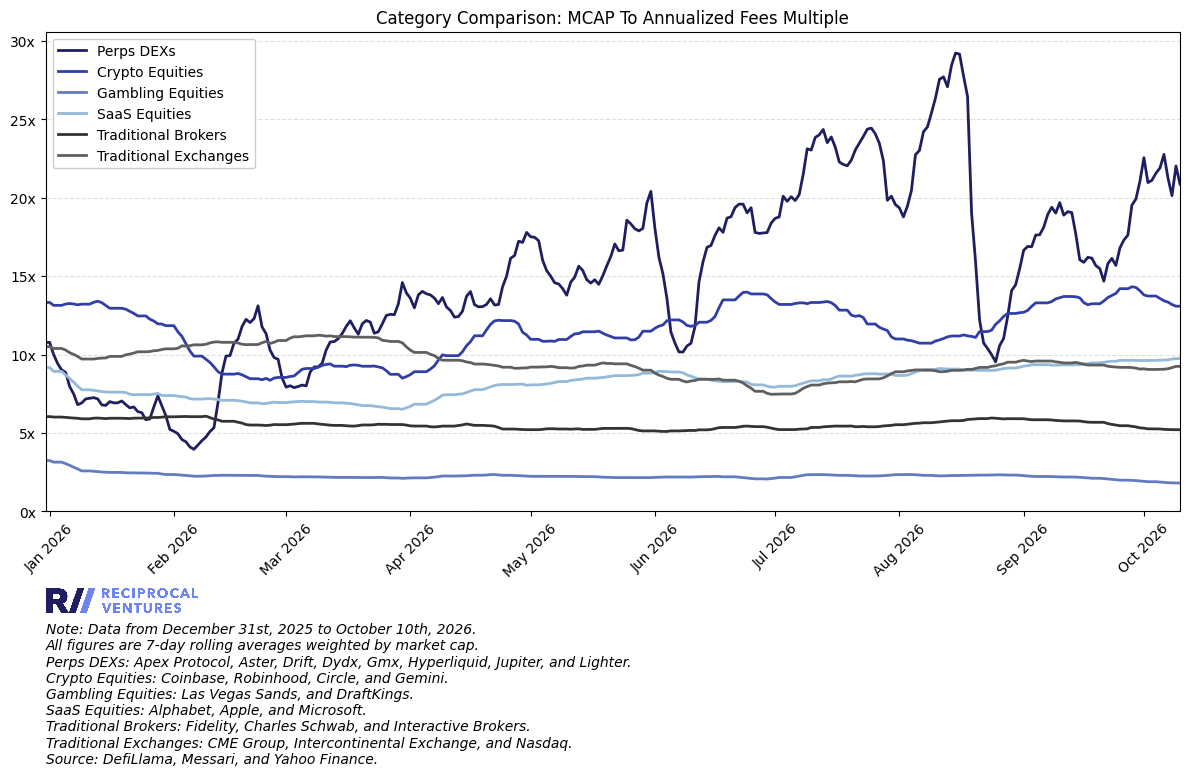

,Perps DEXs,Crypto Equities,Gambling Equities,SaaS Equities,Traditional Brokers,Traditional Exchanges
Median,14.7x,11.8x,2.2x,8.3x,5.5x,9.3x
80th Percentile,19.7x,13.3x,2.3x,9.0x,5.9x,10.5x
20th Percentile,9.9x,9.6x,2.2x,7.2x,5.3x,8.7x
Most Recent,21x,13.1x,1.81x,9.7x,5.2x,9.2x


Note: Data from December 31st, 2025 to October 10th, 2026.
All figures are 7-day rolling averages weighted by market cap.
Perps DEXs: Apex Protocol, Aster, Drift, Dydx, Gmx, Hyperliquid, Jupiter, and Lighter.
Crypto Equities: Coinbase, Robinhood, Circle, and Gemini.
Gambling Equities: Las Vegas Sands, and DraftKings.
SaaS Equities: Alphabet, Apple, and Microsoft.
Traditional Brokers: Fidelity, Charles Schwab, and Interactive Brokers.
Traditional Exchanges: CME Group, Intercontinental Exchange, and Nasdaq.
Source: DefiLlama, Messari, and Yahoo Finance.

Table saved to: outputs/tables/category-comps-perps_dexs-vs-crypto_equities-vs-gambling_equities-etc-mcap-to-annualized-fees-multiple-7d-table.png


In [94]:
# Compare valuation multiples across different categories (no breakout asset)
# Compares crypto equities, gambling equities, and SaaS equities

protocol_categories = {
    'perps_dexs': 'Perps DEXs'
}
equity_categories = {
    'crypto_equities': 'Crypto Equities',
    'gambling_equities': 'Gambling Equities',
    'saas_equities': 'SaaS Equities',
    'traditional_brokers': 'Traditional Brokers',
    'traditional_exchanges': 'Traditional Exchanges'
}
multiple_type = 'MCAP-to-annualized-fees-multiple-7d'
start_date = '2025-12-31'
log_scale = False

result = visualization.category_comps_multiples(
    protocol_categories=protocol_categories,
    equity_categories=equity_categories,
    multiple_type=multiple_type,
    start_date=start_date,
    plots_filepath=plots_filepath,
    tables_filepath=tables_filepath,
    date=date,
    log_scale=log_scale
)

In [95]:
# EARNINGS RANKINGS (all protocols tracked by DefiLlama)

In [100]:
# Top N protocols by annualized earnings / market cap. Universe = every DefiLlama protocol rolled up to
# its parent, built by data_processing.build_universe_earnings in example-pull-raw-data.ipynb for each of
# DefiLlama's trailing windows (earnings = revenue - incentives; mcap = largest child-reported mcap in
# /protocols). window_days picks the window here: 1, 7, 30 or 365 (DefiLlama reports no other totals
# universe-wide); figures are annualized x365/window_days. Chains and protocols without a listed token
# have no mcap and drop out of the yield tables.
top_n = 50
window_days = 7   # 1, 7, 30 or 365: DefiLlama's trailing windows
min_mcap = 50e6    # $; a yield on a $20k market cap is noise, so rank only protocols above this size
spike_share = 0.50 # flag a row when one day is >= this share of the window's revenue (a 30d window annualized
                   # multiplies that day by ~12; regular weekly payers top out near 33%). No flags for 1d.
universe, universe_asof = data_processing.load_universe_earnings(window_days=window_days)
universe['revenue_spike'] = universe.revenue_max_day_share >= spike_share
universe['holders_rev_spike'] = universe.holders_rev_max_day_share >= spike_share
spike_note = (f'one day is >= {spike_share:.0%} of the {window_days}d window (revenue_max_day / revenue_max_day_share in the data), '
              'so the annualized figure is driven by that day')
ann_note = (f'Note: trailing {window_days}d totals annualized (x365/{window_days}), data as of {universe_asof}. '
            'Earnings = revenue - token incentives. ')
# the five annualized columns every ranking table below carries, in this order
earnings_cols = {'ann_fees': ('Ann. fees', 'usd'), 'ann_revenue': ('Ann. revenue', 'usd'),
                 'ann_holders_rev': ('Ann. holders rev', 'usd'), 'ann_earnings': ('Ann. earnings', 'usd'),
                 'earnings_minus_holders_rev': ('Earnings - holders rev', 'usd')}

top_yield = visualization.ranking_table(
    universe[universe.mcap >= min_mcap], sort_col='earnings_yield', n=top_n,
    title=f'Top {top_n} protocols by annualized earnings / market cap (mcap >= ${min_mcap/1e6:,.0f}m, {window_days}d window)',
    columns={'name': ('Protocol', None), 'category': ('Category', None), 'mcap': ('Mcap', 'usd'), **earnings_cols,
             'earnings_yield': ('Earnings / mcap', 'pct1'), 'incentives_status': ('Incentives', None)},
    tables_filepath=tables_filepath, date=date, filename=f'top-{top_n}-earnings-yield-{window_days}d',
    flag_col='revenue_spike', flag_note=spike_note,
    note=ann_note + "'none' = DefiLlama tracks no incentives, so earnings equal revenue. Source: DefiLlama.")


,Protocol,Category,Mcap,Ann. fees,Ann. revenue,Ann. holders rev,Ann. earnings,Earnings - holders rev,Earnings / mcap,Incentives
#,,,,,,,,,,
1,StonkFun,Launchpad,$108m,$130m,$130m,$69m,$130m,$61m,120.1%,none
2,Collector Crypt,Physical TCG,$245m,$216m,$216m,$604k,$216m,$215m,88.0%,none
3,Pump,Launchpad,$2.6b,$2.7b,$956m,$432m,$956m,$524m,36.7%,tracked
4,Meteora,Dexs,$237m,$616m,$74m,$4.5m,$74m,$69m,31.1%,tracked
5,GMX,Derivatives,$89m,$83m,$22m,$3.4m,$21m,$18m,23.8%,tracked
6,SoSoValue,Indexes,$119m,$22m,$24m,$0.00,$24m,$24m,20.3%,tracked
7,edgeX,Derivatives,$126m,$29m,$21m,$7.5m,$21m,$13m,16.5%,tracked
8,Spark,Lending,$72m,$234m,$11m,$3.4m,$11m,$7.8m,15.5%,tracked
9,CoWSwap,DEX Aggregator,$85m,$22m,$13m,$0.00,$13m,$13m,15.2%,tracked


116 protocols qualified; showing top 50.
Note: trailing 7d totals annualized (x365/7), data as of 2026-10-10. Earnings = revenue - token incentives. 'none' = DefiLlama tracks no incentives, so earnings equal revenue. Source: DefiLlama.
* one day is >= 50% of the 7d window (revenue_max_day / revenue_max_day_share in the data), so the annualized figure is driven by that day
Table saved to: outputs/tables/top-50-earnings-yield-7d.png


In [101]:
# Table 1b: the same earnings-yield ranking, optionally restricted to protocols whose token incentives
# DefiLlama tracks, so every row's earnings are revenue - incentives rather than revenue alone.
tracked_only = False   # True: only protocols whose incentives DefiLlama tracks (earnings = revenue - incentives);
                      # False: every protocol ('none' rows have earnings = revenue). Also used by Table 1c.
tracked_mask = (universe.incentives_status == 'tracked') if tracked_only else True
tracked_suffix = '-tracked-incentives' if tracked_only else ''
tracked_label = ' with tracked incentives' if tracked_only else ''
tracked_note = ('Only protocols with incentives tracked by DefiLlama. ' if tracked_only
                else "'none' = DefiLlama tracks no incentives, so earnings equal revenue. ")
tracked = universe[(universe.mcap >= min_mcap) & tracked_mask]

top_yield_tracked = visualization.ranking_table(
    tracked, sort_col='earnings_yield', n=top_n,
    title=f'Top {top_n} protocols{tracked_label} by annualized earnings / market cap (mcap >= ${min_mcap/1e6:,.0f}m, {window_days}d window)',
    columns={'name': ('Protocol', None), 'category': ('Category', None), 'mcap': ('Mcap', 'usd'), **earnings_cols,
             'earnings_yield': ('Earnings / mcap', 'pct1'), 'incentives_status': ('Incentives', None)},
    tables_filepath=tables_filepath, date=date, filename=f'top-{top_n}-earnings-yield{tracked_suffix}-{window_days}d',
    flag_col='revenue_spike', flag_note=spike_note,
    note=ann_note + tracked_note + 'Source: DefiLlama.')


,Protocol,Category,Mcap,Ann. fees,Ann. revenue,Ann. holders rev,Ann. earnings,Earnings - holders rev,Earnings / mcap,Incentives
#,,,,,,,,,,
1,StonkFun,Launchpad,$108m,$130m,$130m,$69m,$130m,$61m,120.1%,none
2,Collector Crypt,Physical TCG,$245m,$216m,$216m,$604k,$216m,$215m,88.0%,none
3,Pump,Launchpad,$2.6b,$2.7b,$956m,$432m,$956m,$524m,36.7%,tracked
4,Meteora,Dexs,$237m,$616m,$74m,$4.5m,$74m,$69m,31.1%,tracked
5,GMX,Derivatives,$89m,$83m,$22m,$3.4m,$21m,$18m,23.8%,tracked
6,SoSoValue,Indexes,$119m,$22m,$24m,$0.00,$24m,$24m,20.3%,tracked
7,edgeX,Derivatives,$126m,$29m,$21m,$7.5m,$21m,$13m,16.5%,tracked
8,Spark,Lending,$72m,$234m,$11m,$3.4m,$11m,$7.8m,15.5%,tracked
9,CoWSwap,DEX Aggregator,$85m,$22m,$13m,$0.00,$13m,$13m,15.2%,tracked


116 protocols qualified; showing top 50.
Note: trailing 7d totals annualized (x365/7), data as of 2026-10-10. Earnings = revenue - token incentives. 'none' = DefiLlama tracks no incentives, so earnings equal revenue. Source: DefiLlama.
* one day is >= 50% of the 7d window (revenue_max_day / revenue_max_day_share in the data), so the annualized figure is driven by that day
Table saved to: outputs/tables/top-50-earnings-yield-7d.png


In [102]:
# Table 1c: the same universe (tracked_only from Table 1b) ranked by absolute annualized earnings (largest first)
# rather than yield, for every protocol with a listed token (mcap > 0) regardless of the min_mcap size floor above.
tracked_any_mcap = universe[(universe.mcap > 0) & tracked_mask]

top_earnings_tracked = visualization.ranking_table(
    tracked_any_mcap, sort_col='ann_earnings', n=top_n,
    title=f'Top {top_n} protocols{tracked_label} by annualized earnings (mcap > 0, {window_days}d window)',
    columns={'name': ('Protocol', None), 'category': ('Category', None), 'mcap': ('Mcap', 'usd'), **earnings_cols,
             'earnings_yield': ('Earnings / mcap', 'pct1'), 'incentives_status': ('Incentives', None)},
    tables_filepath=tables_filepath, date=date, filename=f'top-{top_n}-earnings{tracked_suffix}-{window_days}d',
    flag_col='revenue_spike', flag_note=spike_note,
    note=ann_note + tracked_note + 'Only protocols with a listed market cap. Source: DefiLlama.')


,Protocol,Category,Mcap,Ann. fees,Ann. revenue,Ann. holders rev,Ann. earnings,Earnings - holders rev,Earnings / mcap,Incentives
#,,,,,,,,,,
1,Pump,Launchpad,$2.6b,$2.7b,$956m,$432m,$956m,$524m,36.7%,tracked
2,Hyperliquid,Derivatives,$19b,$910m,$730m,$730m,$730m,$0.00,3.9%,tracked
3,Tron,Chain,$31b,$289m,$289m,$289m,$289m,$0.00,0.9%,tracked
4,Collector Crypt,Physical TCG,$245m,$216m,$216m,$604k,$216m,$215m,88.0%,none
5,World Liberty Financial,Lending,$1.8b,$151m,$151m,$0.00,$151m,$151m,8.3%,none
6,StonkFun,Launchpad,$108m,$130m,$130m,$69m,$130m,$61m,120.1%,none
7,Uniswap,Dexs,$4.7b,$1.2b,$83m,$83m,$83m,-$246k,1.7%,tracked
8,Meteora,Dexs,$237m,$616m,$74m,$4.5m,$74m,$69m,31.1%,tracked
9,Aave,Lending,$2.7b,$498m,$63m,$0.00,$63m,$63m,2.4%,tracked


503 protocols qualified; showing top 50.
Note: trailing 7d totals annualized (x365/7), data as of 2026-10-10. Earnings = revenue - token incentives. 'none' = DefiLlama tracks no incentives, so earnings equal revenue. Only protocols with a listed market cap. Source: DefiLlama.
* one day is >= 50% of the 7d window (revenue_max_day / revenue_max_day_share in the data), so the annualized figure is driven by that day
Table saved to: outputs/tables/top-50-earnings-7d.png


In [103]:
# Top N protocols by annualized earnings - annualized holders revenue, most negative first: a negative gap
# means the protocol pays token holders more than it earns over the window (buybacks / distributions funded
# beyond earnings); positive = retaining earnings. Includes chains and protocols without a listed mcap.
top_n = 20

top_payout_gap = visualization.ranking_table(
    universe, sort_col='earnings_minus_holders_rev', n=top_n, ascending=True,
    title=f'Top {top_n} protocols by annualized holders revenue in excess of earnings ({window_days}d window)',
    columns={'name': ('Protocol', None), 'category': ('Category', None), **earnings_cols,
             'incentives_status': ('Incentives', None)},
    tables_filepath=tables_filepath, date=date, filename=f'top-{top_n}-holders-rev-minus-earnings-{window_days}d',
    flag_col='holders_rev_spike', flag_note=spike_note.replace('revenue_max_day', 'holders_rev_max_day'),
    note=ann_note + 'Source: DefiLlama.')


,Protocol,Category,Ann. fees,Ann. revenue,Ann. holders rev,Ann. earnings,Earnings - holders rev,Incentives
#,,,,,,,,
1,Bitcoin,Chain,$85m,$0.00,$0.00,-$14b,-$14b,tracked
2,Aerodrome,Dexs,$136m,$92m,$92m,-$82m,-$173m,tracked
3,Litecoin,Chain,$197k,$0.00,$0.00,-$89m,-$89m,tracked
4,Fragment,NFT Marketplace,$392m,-$64m,$0.00,-$64m,-$64m,none
5,ORE Protocol,Gamified Mining,$49m,$49m,$48m,-$5.9m,-$54m,tracked
6,Curve Finance *,Dexs,$36m,$14m,$14m,-$17m,-$31m,tracked
7,Aster,Derivatives,$49m,$0.00,$30m,$0.00,-$30m,tracked
8,Pharaoh Exchange,Dexs,$32m,$31m,$31m,$2.7m,-$28m,tracked
9,Pons,Launchpad,$276m,$39m,$57m,$39m,-$18m,none


2337 protocols qualified; showing top 20.
Note: trailing 7d totals annualized (x365/7), data as of 2026-10-10. Earnings = revenue - token incentives. Source: DefiLlama.
* one day is >= 50% of the 7d window (holders_rev_max_day / holders_rev_max_day_share in the data), so the annualized figure is driven by that day
Table saved to: outputs/tables/top-20-holders-rev-minus-earnings-7d.png
